In [2]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("Project Root:", PROJECT_ROOT)

Project Root: d:\InsightAI


In [3]:
from src.data.ingestion import load_data
from src.utils.config import RAW_DATA_DIR

file_path = RAW_DATA_DIR / "Superstore.xls"

df = load_data(file_path)

print("Shape:", df.shape)

Shape: (10194, 21)


In [4]:
import sys

print(sys.executable)

d:\InsightAI\.venv\Scripts\python.exe


In [5]:
import xlrd

print("xlrd version:", xlrd.__version__)

xlrd version: 2.0.2


In [6]:
print("Columns:")
print(df.columns.tolist())

Columns:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country/Region', 'City', 'State/Province', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']


In [7]:
df.dtypes

Row ID                     int64
Order ID                     str
Order Date        datetime64[us]
Ship Date         datetime64[us]
Ship Mode                    str
Customer ID                  str
Customer Name                str
Segment                      str
Country/Region               str
City                         str
State/Province               str
Postal Code               object
Region                       str
Product ID                   str
Category                     str
Sub-Category                 str
Product Name                 str
Sales                    float64
Quantity                   int64
Discount                 float64
Profit                   float64
dtype: object

In [8]:
print("Missing values:")
print(df.isna().sum())

Missing values:
Row ID            0
Order ID          0
Order Date        0
Ship Date         0
Ship Mode         0
Customer ID       0
Customer Name     0
Segment           0
Country/Region    0
City              0
State/Province    0
Postal Code       0
Region            0
Product ID        0
Category          0
Sub-Category      0
Product Name      0
Sales             0
Quantity          0
Discount          0
Profit            0
dtype: int64


In [9]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [10]:
df.describe()

,Row ID,Order Date,Ship Date,Sales,Quantity,Discount,Profit
count,10194.000000,10194,10194,10194.000000,10194.000000,10194.000000,10194.000000
mean,5097.500000,2025-04-29 11:48:25.002943,2025-05-03 10:52:45.626839,228.225854,3.791838,0.155385,28.673417
min,1.000000,2023-01-03 00:00:00,2023-01-07 00:00:00,0.444000,1.000000,0.000000,-6599.978000
25%,2549.250000,2024-05-14 00:00:00,2024-05-19 00:00:00,17.220000,2.000000,0.000000,1.760800
50%,5097.500000,2025-06-25 00:00:00,2025-06-28 00:00:00,53.910000,3.000000,0.200000,8.690000
75%,7645.750000,2026-05-14 00:00:00,2026-05-18 00:00:00,209.500000,5.000000,0.200000,29.297925
max,10194.000000,2026-12-30 00:00:00,2027-01-05 00:00:00,22638.480000,14.000000,0.800000,8399.976000
std,2942.898656,NaN,NaN,619.906839,2.228317,0.206249,232.465115


In [11]:
from src.data.validation import validate_required_columns

validate_required_columns(df)

print("✅ Required column validation passed!")

✅ Required column validation passed!


In [12]:
from src.data.validation import validate_missing_values

validate_missing_values(df)

print("✅ Missing value validation passed!")

✅ Missing value validation passed!


In [13]:
from src.data.validation import (
    validate_required_columns,
    validate_missing_values
)

validate_required_columns(df)
validate_missing_values(df)

print("✅ Required column validation passed!")
print("✅ Missing value validation passed!")

✅ Required column validation passed!
✅ Missing value validation passed!


In [14]:
from src.data.validation import validate_duplicates

validate_duplicates(df)

print("✅ Duplicate validation passed!")

✅ Duplicate validation passed!


In [15]:
from src.data.validation import validate_data_types

validate_data_types(df)

print("✅ Data type validation passed!")

✅ Data type validation passed!


In [16]:
from src.data.validation import validate_business_rules

validate_business_rules(df)

print("✅ Business rule validation passed!")

✅ Business rule validation passed!


In [17]:
from src.data.validation import validate_dataset

validate_dataset(df)

print("✅ All dataset validation checks passed!")

✅ All dataset validation checks passed!


In [18]:
from src.data.cleaning import clean_column_names

df_clean = clean_column_names(df)

print("Original columns:")
print(df.columns.tolist())

print("\nCleaned columns:")
print(df_clean.columns.tolist())

Original columns:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country/Region', 'City', 'State/Province', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']

Cleaned columns:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country/Region', 'City', 'State/Province', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']


In [19]:
from src.data.cleaning import clean_text_columns

df_clean = clean_text_columns(df_clean)

print("✅ Text columns cleaned successfully!")

print(df_clean[["Ship Mode", "Segment", "Region", "Category"]].head())

✅ Text columns cleaned successfully!
        Ship Mode      Segment   Region         Category
0  Standard Class     Consumer  Central  Office Supplies
1  Standard Class  Home Office  Central  Office Supplies
2  Standard Class  Home Office  Central  Office Supplies
3  Standard Class  Home Office  Central  Office Supplies
4  Standard Class     Consumer     East  Office Supplies


In [20]:
from src.data.cleaning import clean_date_and_numeric_columns

df_clean = clean_date_and_numeric_columns(df_clean)

print("✅ Date and numeric columns cleaned!")

print("\nData types:")
print(df_clean[[
    "Order Date",
    "Ship Date",
    "Sales",
    "Quantity",
    "Discount",
    "Profit"
]].dtypes)

✅ Date and numeric columns cleaned!

Data types:
Order Date    datetime64[us]
Ship Date     datetime64[us]
Sales                float64
Quantity               int64
Discount             float64
Profit               float64
dtype: object


In [21]:
from src.data.cleaning import handle_missing_values

before = len(df_clean)

df_clean = handle_missing_values(df_clean)

after = len(df_clean)

print("Rows before:", before)
print("Rows after:", after)
print("Rows removed:", before - after)

Rows before: 10194
Rows after: 10194
Rows removed: 0


In [22]:
from src.data.cleaning import remove_duplicates

df_clean = remove_duplicates(df_clean)

print("Final rows:", len(df_clean))

Duplicate rows removed: 0
Final rows: 10194


In [23]:
from src.data.cleaning import final_quality_check

final_quality_check(df_clean)

Rows: 10194
Columns: 21
Missing values in critical columns: 0
Duplicate rows: 0

Optional missing values:
Postal Code    9983
dtype: int64

✅ Final data quality check passed!


True

In [24]:
missing = df_clean.isna().sum()

print(missing[missing > 0])

Postal Code    9983
dtype: int64


In [25]:
print("Total missing values:", df_clean.isna().sum().sum())

Total missing values: 9983


In [26]:
print("\nMissing values by column:")
print(df_clean.isna().sum().sort_values(ascending=False))


Missing values by column:
Postal Code       9983
Order ID             0
Order Date           0
Ship Date            0
Row ID               0
Ship Mode            0
Customer ID          0
Segment              0
Customer Name        0
Country/Region       0
City                 0
State/Province       0
Region               0
Product ID           0
Category             0
Sub-Category         0
Product Name         0
Sales                0
Quantity             0
Discount             0
Profit               0
dtype: int64


In [27]:
missing = df_clean.isna().sum()

print(missing[missing > 0])

Postal Code    9983
dtype: int64


In [28]:
print("Total missing values:", df_clean.isna().sum().sum())

Total missing values: 9983


In [29]:
from src.data.cleaning import clean_postal_code

df_clean = clean_postal_code(df_clean)

print(df_clean["Postal Code"].dtype)

string


In [30]:
from src.utils.config import PROCESSED_DATA_DIR

output_path = PROCESSED_DATA_DIR / "Superstore_cleaned.csv"

df_clean.to_csv(output_path, index=False)

print("Cleaned dataset saved successfully!")
print("Path:", output_path)

Cleaned dataset saved successfully!
Path: D:\InsightAI\data\processed\Superstore_cleaned.csv


In [31]:
print("Shape:", df_clean.shape)
print("Saved file:", output_path)

Shape: (10194, 21)
Saved file: D:\InsightAI\data\processed\Superstore_cleaned.csv


In [32]:
import pandas as pd

df_check = pd.read_csv(output_path)

print("Reloaded shape:", df_check.shape)
print("\nColumns:")
print(df_check.columns.tolist())

Reloaded shape: (10194, 21)

Columns:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country/Region', 'City', 'State/Province', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']


In [33]:
df_check.isna().sum()

Row ID               0
Order ID             0
Order Date           0
Ship Date            0
Ship Mode            0
Customer ID          0
Customer Name        0
Segment              0
Country/Region       0
City                 0
State/Province       0
Postal Code       9983
Region               0
Product ID           0
Category             0
Sub-Category         0
Product Name         0
Sales                0
Quantity             0
Discount             0
Profit               0
dtype: int64

In [34]:
## 10. Exploratory Data Analysis (EDA)

### 10.1 Load Processed Dataset

In [35]:
import pandas as pd
from src.utils.config import PROCESSED_DATA_DIR

processed_path = PROCESSED_DATA_DIR / "Superstore_cleaned.csv"

df = pd.read_csv(processed_path)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (10194, 21)


In [36]:
### 10.2 Basic Statistics
df.describe()


,Row ID,Sales,Quantity,Discount,Profit
count,10194.000000,10194.000000,10194.000000,10194.000000,10194.000000
mean,5097.500000,228.225854,3.791838,0.155385,28.673417
std,2942.898656,619.906839,2.228317,0.206249,232.465115
min,1.000000,0.444000,1.000000,0.000000,-6599.978000
25%,2549.250000,17.220000,2.000000,0.000000,1.760800
50%,5097.500000,53.910000,3.000000,0.200000,8.690000
75%,7645.750000,209.500000,5.000000,0.200000,29.297925
max,10194.000000,22638.480000,14.000000,0.800000,8399.976000


In [37]:
df.describe(include="object")

C:\Users\Admin\AppData\Local\Temp\ipykernel_9632\702825166.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include="object")


,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,State/Province,Postal Code,Region,Product ID,Category,Sub-Category,Product Name
count,10194,10194,10194,10194,10194,10194,10194,10194,10194,10194,211,10194,10194,10194,10194,10194
unique,5111,1242,1338,4,804,800,3,2,542,59,24,4,1862,3,17,1849
top,US-2026-100111,2025-09-05,2024-12-16,Standard Class,WB-21850,William Brown,Consumer,United States,New York City,California,H1A,West,FUR-FU-10004270,Office Supplies,Binders,Staples
freq,14,38,38,6120,41,41,5281,9994,915,2001,24,3253,20,6128,1548,50


In [38]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10194 entries, 0 to 10193
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Row ID          10194 non-null  int64  
 1   Order ID        10194 non-null  str    
 2   Order Date      10194 non-null  str    
 3   Ship Date       10194 non-null  str    
 4   Ship Mode       10194 non-null  str    
 5   Customer ID     10194 non-null  str    
 6   Customer Name   10194 non-null  str    
 7   Segment         10194 non-null  str    
 8   Country/Region  10194 non-null  str    
 9   City            10194 non-null  str    
 10  State/Province  10194 non-null  str    
 11  Postal Code     211 non-null    str    
 12  Region          10194 non-null  str    
 13  Product ID      10194 non-null  str    
 14  Category        10194 non-null  str    
 15  Sub-Category    10194 non-null  str    
 16  Product Name    10194 non-null  str    
 17  Sales           10194 non-null  float64
 1

In [39]:
### 10.3 Business KPIs
total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
total_orders = df["Order ID"].nunique()
total_customers = df["Customer ID"].nunique()
total_products = df["Product ID"].nunique()
total_quantity = df["Quantity"].sum()

average_order_value = total_sales / total_orders
profit_margin = (total_profit / total_sales) * 100

print("===== BUSINESS KPIs =====")
print(f"Total Sales: ${total_sales:,.2f}")
print(f"Total Profit: ${total_profit:,.2f}")
print(f"Total Orders: {total_orders:,}")
print(f"Total Customers: {total_customers:,}")
print(f"Total Products: {total_products:,}")
print(f"Total Quantity Sold: {total_quantity:,}")
print(f"Average Order Value: ${average_order_value:,.2f}")
print(f"Profit Margin: {profit_margin:.2f}%")


===== BUSINESS KPIs =====
Total Sales: $2,326,534.35
Total Profit: $292,296.81
Total Orders: 5,111
Total Customers: 804
Total Products: 1,862
Total Quantity Sold: 38,654
Average Order Value: $455.20
Profit Margin: 12.56%


In [40]:
kpi_summary = pd.DataFrame({
    "KPI": [
        "Total Sales",
        "Total Profit",
        "Total Orders",
        "Total Customers",
        "Total Products",
        "Total Quantity",
        "Average Order Value",
        "Profit Margin"
    ],
    "Value": [
        total_sales,
        total_profit,
        total_orders,
        total_customers,
        total_products,
        total_quantity,
        average_order_value,
        profit_margin
    ]
})

kpi_summary

,KPI,Value
0,Total Sales,2.326534e+06
1,Total Profit,2.922968e+05
2,Total Orders,5.111000e+03
3,Total Customers,8.040000e+02
4,Total Products,1.862000e+03
5,Total Quantity,3.865400e+04
6,Average Order Value,4.552014e+02
7,Profit Margin,1.256361e+01


In [41]:
### 10.4 Sales & Profit Analysis
#### 10.4.1 Category Performance
category_analysis = (
    df.groupby("Category")
      .agg(
          Sales=("Sales", "sum"),
          Profit=("Profit", "sum"),
          Quantity=("Quantity", "sum")
      )
      .sort_values("Sales", ascending=False)
)

category_analysis

,Sales,Profit,Quantity
Category,,,
Technology,839893.2790,146543.3756,7017
Furniture,754747.7613,19729.9956,8369
Office Supplies,731893.3140,126023.4434,23268


In [42]:
category_analysis["Profit Margin (%)"] = (
    category_analysis["Profit"] /
    category_analysis["Sales"] * 100
)

category_analysis

,Sales,Profit,Quantity,Profit Margin (%)
Category,,,,
Technology,839893.2790,146543.3756,7017,17.447857
Furniture,754747.7613,19729.9956,8369,2.614118
Office Supplies,731893.3140,126023.4434,23268,17.218827


In [43]:
import plotly.express as px

fig = px.bar(
    category_analysis.reset_index(),
    x="Category",
    y="Sales",
    title="Sales by Category",
    text_auto=".2s"
)

fig.show()

In [44]:
fig = px.bar(
    category_analysis.reset_index(),
    x="Category",
    y="Profit",
    title="Profit by Category",
    text_auto=".2s"
)

fig.show()

In [45]:
### 10.4.2 Sub-Category Performance
subcategory_analysis = (
    df.groupby("Sub-Category")
      .agg(
          Sales=("Sales", "sum"),
          Profit=("Profit", "sum"),
          Quantity=("Quantity", "sum")
      )
      .sort_values("Sales", ascending=False)
)

subcategory_analysis

,Sales,Profit,Quantity
Sub-Category,,,
Chairs,335768.2490,27223.5323,2431
Phones,331842.6400,45050.8265,3357
Storage,224644.5540,21285.1115,3191
Tables,208020.1820,-17753.2061,1261
Binders,207354.8810,31426.1003,6071
Machines,189925.0310,3461.9769,442
Accessories,167380.3180,41936.6357,2976
Copiers,150745.2900,56093.9365,242
Bookcases,115361.2043,-3632.0736,878


In [46]:
subcategory_analysis["Profit Margin (%)"] = (
    subcategory_analysis["Profit"] /
    subcategory_analysis["Sales"] * 100
)

subcategory_analysis

,Sales,Profit,Quantity,Profit Margin (%)
Sub-Category,,,,
Chairs,335768.2490,27223.5323,2431,8.107834
Phones,331842.6400,45050.8265,3357,13.575961
Storage,224644.5540,21285.1115,3191,9.475018
Tables,208020.1820,-17753.2061,1261,-8.534367
Binders,207354.8810,31426.1003,6071,15.155708
Machines,189925.0310,3461.9769,442,1.822812
Accessories,167380.3180,41936.6357,2976,25.054700
Copiers,150745.2900,56093.9365,242,37.211071
Bookcases,115361.2043,-3632.0736,878,-3.148436


In [47]:
fig = px.bar(
    subcategory_analysis.reset_index(),
    x="Sub-Category",
    y="Sales",
    title="Sales by Sub-Category",
    text_auto=".2s"
)

fig.show()

In [48]:
fig = px.bar(
    subcategory_analysis.reset_index(),
    x="Sub-Category",
    y="Profit",
    title="Profit by Sub-Category",
    text_auto=".2s"
)

fig.show()

In [49]:
### 10.6 Regional Analysis
#### 10.6.1 Region Performance
region_analysis = (
    df.groupby("Region")
      .agg(
          Sales=("Sales", "sum"),
          Profit=("Profit", "sum"),
          Quantity=("Quantity", "sum"),
          Orders=("Order ID", "nunique"),
          Customers=("Customer ID", "nunique")
      )
      .sort_values("Sales", ascending=False)
)

region_analysis

,Sales,Profit,Quantity,Orders,Customers
Region,,,,,
West,739813.6085,110798.8170,12466,1635,686
East,691828.1680,94883.2603,11159,1475,685
Central,503170.6728,39865.3070,8820,1179,629
South,391721.9050,46749.4303,6209,822,512


In [50]:
region_analysis["Profit Margin (%)"] = (
    region_analysis["Profit"] /
    region_analysis["Sales"] * 100
)

region_analysis

,Sales,Profit,Quantity,Orders,Customers,Profit Margin (%)
Region,,,,,,
West,739813.6085,110798.8170,12466,1635,686,14.976585
East,691828.1680,94883.2603,11159,1475,685,13.714859
Central,503170.6728,39865.3070,8820,1179,629,7.922820
South,391721.9050,46749.4303,6209,822,512,11.934342


In [51]:
fig = px.bar(
    region_analysis.reset_index(),
    x="Region",
    y="Sales",
    title="Sales by Region",
    text_auto=".2s"
)

fig.show()

In [52]:
fig = px.bar(
    region_analysis.reset_index(),
    x="Region",
    y="Profit",
    title="Profit by Region",
    text_auto=".2s"
)

fig.show()

In [53]:
fig = px.scatter(
    region_analysis.reset_index(),
    x="Sales",
    y="Profit",
    size="Quantity",
    text="Region",
    title="Regional Sales vs Profit"
)

fig.update_traces(textposition="top center")

fig.show()

In [54]:
### 10.7 Customer Analysis
#### 10.7.1 Customer Performance
customer_analysis = (
    df.groupby("Customer ID")
      .agg(
          Sales=("Sales", "sum"),
          Profit=("Profit", "sum"),
          Orders=("Order ID", "nunique"),
          Quantity=("Quantity", "sum")
      )
      .sort_values("Sales", ascending=False)
)

customer_analysis.head(10)

,Sales,Profit,Orders,Quantity
Customer ID,,,,
SM-20320,25043.050,-1980.7393,5,50
TC-20980,19052.218,8981.3239,5,42
RB-19360,15117.339,6976.0959,6,71
TA-21385,14595.620,4703.7883,4,36
AB-10105,14473.571,5444.8055,10,73
KL-16645,14175.229,806.8550,12,113
SC-20095,14142.334,5757.4119,9,87
HL-15040,12873.298,5622.4292,6,50
SE-20110,12209.438,2650.6769,11,78


In [55]:
top_customers = customer_analysis.head(10)

top_customers

,Sales,Profit,Orders,Quantity
Customer ID,,,,
SM-20320,25043.050,-1980.7393,5,50
TC-20980,19052.218,8981.3239,5,42
RB-19360,15117.339,6976.0959,6,71
TA-21385,14595.620,4703.7883,4,36
AB-10105,14473.571,5444.8055,10,73
KL-16645,14175.229,806.8550,12,113
SC-20095,14142.334,5757.4119,9,87
HL-15040,12873.298,5622.4292,6,50
SE-20110,12209.438,2650.6769,11,78


In [56]:
fig = px.bar(
    top_customers.reset_index(),
    x="Customer ID",
    y="Sales",
    title="Top 10 Customers by Sales",
    text_auto=".2s"
)

fig.show()

In [57]:
top_profit_customers = (
    customer_analysis
    .sort_values("Profit", ascending=False)
    .head(10)
)

top_profit_customers

,Sales,Profit,Orders,Quantity
Customer ID,,,,
TC-20980,19052.218,8981.3239,5,42
RB-19360,15117.339,6976.0959,6,71
SC-20095,14142.334,5757.4119,9,87
HL-15040,12873.298,5622.4292,6,50
AB-10105,14473.571,5444.8055,10,73
TA-21385,14595.620,4703.7883,4,36
CM-12385,8954.020,3899.8904,4,34
KD-16495,8181.256,3038.6254,12,84
AR-10540,6608.448,2884.6208,6,33


In [58]:
fig = px.bar(
    top_profit_customers.reset_index(),
    x="Customer ID",
    y="Profit",
    title="Top 10 Customers by Profit",
    text_auto=".2s"
)

fig.show()

In [59]:
fig = px.scatter(
    customer_analysis.reset_index(),
    x="Sales",
    y="Profit",
    size="Orders",
    hover_data=["Customer ID", "Quantity"],
    title="Customer Sales vs Profit"
)

fig.show()

In [60]:
customer_summary = {
    "Total Customers": customer_analysis.shape[0],
    "Average Customer Sales": customer_analysis["Sales"].mean(),
    "Average Customer Profit": customer_analysis["Profit"].mean(),
    "Average Orders per Customer": customer_analysis["Orders"].mean(),
    "Average Quantity per Customer": customer_analysis["Quantity"].mean()
}

customer_summary

{'Total Customers': 804,
 'Average Customer Sales': np.float64(2893.699445646766),
 'Average Customer Profit': np.float64(363.55325199004966),
 'Average Orders per Customer': np.float64(6.364427860696518),
 'Average Quantity per Customer': np.float64(48.0771144278607)}

In [61]:
### 10.8 Product Analysis
#### 10.8.1 Product Performance
product_analysis = (
    df.groupby("Product ID")
      .agg(
          Sales=("Sales", "sum"),
          Profit=("Profit", "sum"),
          Quantity=("Quantity", "sum"),
          Orders=("Order ID", "nunique")
      )
      .sort_values("Sales", ascending=False)
)

product_analysis.head(10)

,Sales,Profit,Quantity,Orders
Product ID,,,,
TEC-CO-10004722,61599.824,2.519993e+04,20,5
OFF-BI-10003527,27453.384,7.753039e+03,31,10
TEC-MA-10002412,22638.480,-1.811078e+03,6,1
FUR-CH-10002024,21870.576,3.410605e-13,39,8
OFF-BI-10001359,19823.479,2.233505e+03,37,11
OFF-BI-10000545,19024.500,7.609800e+02,48,9
TEC-CO-10001449,18839.686,6.983884e+03,38,8
TEC-MA-10001127,18374.895,4.094977e+03,12,3
OFF-BI-10004995,17965.068,-1.878166e+03,27,6


In [62]:
top_products_sales = product_analysis.head(5)

top_products_sales

,Sales,Profit,Quantity,Orders
Product ID,,,,
TEC-CO-10004722,61599.824,2.519993e+04,20,5
OFF-BI-10003527,27453.384,7.753039e+03,31,10
TEC-MA-10002412,22638.480,-1.811078e+03,6,1
FUR-CH-10002024,21870.576,3.410605e-13,39,8
OFF-BI-10001359,19823.479,2.233505e+03,37,11


In [63]:
top_products_profit = (
    product_analysis
    .sort_values("Profit", ascending=False)
    .head(10)
)

top_products_profit

,Sales,Profit,Quantity,Orders
Product ID,,,,
TEC-CO-10004722,61599.824,25199.9280,20,5
OFF-BI-10003527,27453.384,7753.0390,31,10
TEC-CO-10001449,18839.686,6983.8836,38,8
TEC-CO-10003763,11619.834,4570.9347,19,4
TEC-AC-10002049,13756.536,4425.3432,60,15
TEC-MA-10001127,18374.895,4094.9766,12,3
TEC-MA-10003979,7699.890,3772.9461,11,2
TEC-MA-10001047,14299.890,3717.9714,11,2
OFF-BI-10001120,15875.916,3345.2823,13,3


In [64]:
fig = px.bar(
    top_products_profit.reset_index(),
    x="Product ID",
    y="Profit",
    title="Top 10 Products by Profit",
    text_auto=".2s"
)

fig.show()

In [65]:
worst_products_profit = (
    product_analysis
    .sort_values("Profit")
    .head(10)
)

worst_products_profit

,Sales,Profit,Quantity,Orders
Product ID,,,,
TEC-MA-10000418,11099.963,-8879.9704,9,3
TEC-MA-10000822,16829.901,-4589.9730,18,4
TEC-MA-10004125,7999.980,-3839.9904,4,1
FUR-TA-10000198,9917.640,-2876.1156,27,5
FUR-TA-10001889,9544.725,-1934.3976,33,7
OFF-BI-10004995,17965.068,-1878.1662,27,6
TEC-MA-10002412,22638.480,-1811.0784,6,1
OFF-SU-10002881,16656.200,-1299.1836,22,6
FUR-TA-10001950,6518.754,-1201.0581,19,4


In [66]:
fig = px.bar(
    worst_products_profit.reset_index(),
    x="Product ID",
    y="Profit",
    title="Bottom 10 Products by Profit",
    text_auto=".2s"
)

fig.show()

In [67]:
product_analysis["Profit Margin (%)"] = (
    product_analysis["Profit"] /
    product_analysis["Sales"] * 100
)

product_analysis.head(10)

,Sales,Profit,Quantity,Orders,Profit Margin (%)
Product ID,,,,,
TEC-CO-10004722,61599.824,2.519993e+04,20,5,4.090909e+01
OFF-BI-10003527,27453.384,7.753039e+03,31,10,2.824074e+01
TEC-MA-10002412,22638.480,-1.811078e+03,6,1,-8.000000e+00
FUR-CH-10002024,21870.576,3.410605e-13,39,8,1.559449e-15
OFF-BI-10001359,19823.479,2.233505e+03,37,11,1.126697e+01
OFF-BI-10000545,19024.500,7.609800e+02,48,9,4.000000e+00
TEC-CO-10001449,18839.686,6.983884e+03,38,8,3.707006e+01
TEC-MA-10001127,18374.895,4.094977e+03,12,3,2.228571e+01
OFF-BI-10004995,17965.068,-1.878166e+03,27,6,-1.045455e+01


In [68]:
df["Order Date"] = pd.to_datetime(df["Order Date"])
df["Ship Date"] = pd.to_datetime(df["Ship Date"])

print(df[["Order Date", "Ship Date"]].dtypes)

Order Date    datetime64[us]
Ship Date     datetime64[us]
dtype: object


In [69]:
monthly_analysis = (
    df.set_index("Order Date")
      .resample("ME")
      .agg(
          Sales=("Sales", "sum"),
          Profit=("Profit", "sum"),
          Orders=("Order ID", "nunique")
      )
)

monthly_analysis.head()

,Sales,Profit,Orders
Order Date,,,
2023-01-31,14518.055,2539.3907,33
2023-02-28,4519.892,862.3084,28
2023-03-31,56933.909,693.4499,72
2023-04-30,28295.345,3488.8352,66
2023-05-31,26319.767,3196.3918,72


In [70]:
import plotly.express as px

fig = px.line(
    monthly_analysis.reset_index(),
    x="Order Date",
    y="Sales",
    markers=True,
    title="Monthly Sales Trend"
)

fig.update_layout(
    xaxis_title="Month",
    yaxis_title="Sales ($)",
    title_x=0.5
)

fig.show()

In [71]:
fig = px.line(
    monthly_analysis.reset_index(),
    x="Order Date",
    y="Profit",
    markers=True,
    title="Monthly Profit Trend"
)

fig.update_layout(
    xaxis_title="Month",
    yaxis_title="Profit ($)",
    title_x=0.5
)

fig.show()

In [72]:
yearly_analysis = (
    df.set_index("Order Date")
      .resample("YE")
      .agg(
          Sales=("Sales", "sum"),
          Profit=("Profit", "sum"),
          Orders=("Order ID", "nunique")
      )
)

yearly_analysis

,Sales,Profit,Orders
Order Date,,,
2023-12-31,494040.2121,51684.2957,995
2024-12-31,472993.0310,62020.9695,1053
2025-12-31,613933.5800,82665.2018,1340
2026-12-31,745567.5312,95926.3476,1723


In [73]:
yearly_analysis["Profit Margin (%)"] = (
    yearly_analysis["Profit"] /
    yearly_analysis["Sales"] * 100
)

yearly_analysis

,Sales,Profit,Orders,Profit Margin (%)
Order Date,,,,
2023-12-31,494040.2121,51684.2957,995,10.461556
2024-12-31,472993.0310,62020.9695,1053,13.112449
2025-12-31,613933.5800,82665.2018,1340,13.464844
2026-12-31,745567.5312,95926.3476,1723,12.866218


In [74]:
fig = px.bar(
    yearly_analysis.reset_index(),
    x="Order Date",
    y="Sales",
    title="Yearly Sales",
    text_auto=".2s"
)

fig.update_layout(
    xaxis_title="Year",
    yaxis_title="Sales ($)",
    title_x=0.5
)

fig.show()

In [75]:
fig = px.bar(
    yearly_analysis.reset_index(),
    x="Order Date",
    y="Profit",
    title="Yearly Profit",
    text_auto=".2s"
)

fig.update_layout(
    xaxis_title="Year",
    yaxis_title="Profit ($)",
    title_x=0.5
)

fig.show()

In [76]:
yearly_analysis["Sales Growth (%)"] = (
    yearly_analysis["Sales"].pct_change() * 100
)

yearly_analysis

,Sales,Profit,Orders,Profit Margin (%),Sales Growth (%)
Order Date,,,,,
2023-12-31,494040.2121,51684.2957,995,10.461556,NaN
2024-12-31,472993.0310,62020.9695,1053,13.112449,-4.260216
2025-12-31,613933.5800,82665.2018,1340,13.464844,29.797595
2026-12-31,745567.5312,95926.3476,1723,12.866218,21.441074


In [77]:
print("===== CATEGORY INSIGHTS =====")

for category in category_analysis.index:
    sales = category_analysis.loc[category, "Sales"]
    profit = category_analysis.loc[category, "Profit"]
    margin = category_analysis.loc[category, "Profit Margin (%)"]

    print(f"\n{category}")
    print(f"Sales: ${sales:,.2f}")
    print(f"Profit: ${profit:,.2f}")
    print(f"Profit Margin: {margin:.2f}%")

===== CATEGORY INSIGHTS =====

Technology
Sales: $839,893.28
Profit: $146,543.38
Profit Margin: 17.45%

Furniture
Sales: $754,747.76
Profit: $19,730.00
Profit Margin: 2.61%

Office Supplies
Sales: $731,893.31
Profit: $126,023.44
Profit Margin: 17.22%


In [78]:
best_sales_category = category_analysis["Sales"].idxmax()
best_profit_category = category_analysis["Profit"].idxmax()
best_margin_category = category_analysis["Profit Margin (%)"].idxmax()

worst_profit_category = category_analysis["Profit"].idxmin()

print("Highest Sales Category:", best_sales_category)
print("Highest Profit Category:", best_profit_category)
print("Highest Profit Margin Category:", best_margin_category)
print("Lowest Profit Category:", worst_profit_category)

Highest Sales Category: Technology
Highest Profit Category: Technology
Highest Profit Margin Category: Technology
Lowest Profit Category: Furniture


In [79]:
subcategory_profitability = (
    df.groupby("Sub-Category")
      .agg(
          Sales=("Sales", "sum"),
          Profit=("Profit", "sum"),
          Orders=("Order ID", "nunique")
      )
)

subcategory_profitability["Profit Margin (%)"] = (
    subcategory_profitability["Profit"]
    / subcategory_profitability["Sales"] * 100
)

subcategory_profitability = (
    subcategory_profitability
    .sort_values("Profit Margin (%)", ascending=False)
)

subcategory_profitability

,Sales,Profit,Orders,Profit Margin (%)
Sub-Category,,,,
Labels,12695.0420,5572.7780,348,43.897279
Paper,79540.5380,34511.5070,1205,43.388576
Envelopes,16528.3620,6988.0247,251,42.278991
Copiers,150745.2900,56093.9365,70,37.211071
Fasteners,8532.2400,2428.6358,226,28.464223
Accessories,167380.3180,41936.6357,718,25.054700
Art,27659.0140,6653.1962,756,24.054351
Appliances,108213.1850,18329.4844,459,16.938310
Binders,207354.8810,31426.1003,1339,15.155708


In [80]:
print("===== SUB-CATEGORY PROFITABILITY =====")

print(
    "\nTop 5 by Profit Margin:"
)

print(
    subcategory_profitability.head(5)
)

print(
    "\nBottom 5 by Profit Margin:"
)

print(
    subcategory_profitability.tail(5)
)

===== SUB-CATEGORY PROFITABILITY =====

Top 5 by Profit Margin:
                   Sales      Profit  Orders  Profit Margin (%)
Sub-Category                                                   
Labels         12695.042   5572.7780     348          43.897279
Paper          79540.538  34511.5070    1205          43.388576
Envelopes      16528.362   6988.0247     251          42.278991
Copiers       150745.290  56093.9365      70          37.211071
Fasteners       8532.240   2428.6358     226          28.464223

Bottom 5 by Profit Margin:
                    Sales      Profit  Orders  Profit Margin (%)
Sub-Category                                                    
Chairs        335768.2490  27223.5323     591           8.107834
Machines      189925.0310   3461.9769     114           1.822812
Supplies       46725.4980  -1171.3945     189          -2.506971
Bookcases     115361.2043  -3632.0736     228          -3.148436
Tables        208020.1820 -17753.2061     314          -8.534367


In [81]:
loss_making_subcategories = (
    subcategory_profitability[
        subcategory_profitability["Profit"] < 0
    ]
)

loss_making_subcategories

,Sales,Profit,Orders,Profit Margin (%)
Sub-Category,,,,
Supplies,46725.4980,-1171.3945,189,-2.506971
Bookcases,115361.2043,-3632.0736,228,-3.148436
Tables,208020.1820,-17753.2061,314,-8.534367


In [82]:
discount_analysis = (
    df.groupby("Discount")
      .agg(
          Sales=("Sales", "sum"),
          Profit=("Profit", "sum"),
          Orders=("Order ID", "nunique")
      )
      .reset_index()
      .sort_values("Discount")
)

discount_analysis

,Discount,Sales,Profit,Orders
0,0.00,1.105324e+06,326718.5872,2714
1,0.10,5.495250e+04,9099.9700,91
2,0.15,2.755852e+04,1418.9915,51
3,0.20,7.739394e+05,91079.9517,2440
4,0.30,1.044741e+05,-10513.4456,214
5,0.32,1.449346e+04,-2391.1377,27
6,0.40,1.164978e+05,-23086.3742,186
7,0.45,5.484974e+03,-2493.1111,10
8,0.50,5.891854e+04,-20506.4281,64
9,0.60,7.105940e+03,-6164.3472,138


In [83]:
fig = px.scatter(
    discount_analysis,
    x="Discount",
    y="Profit",
    size="Sales",
    title="Discount vs Profit",
    labels={
        "Discount": "Discount",
        "Profit": "Profit ($)"
    }
)

fig.show()

In [84]:
discount_profit_corr = (
    discount_analysis["Discount"]
    .corr(discount_analysis["Profit"])
)

print(
    f"Discount-Profit Correlation: {discount_profit_corr:.3f}"
)

Discount-Profit Correlation: -0.630


In [85]:
region_analysis["Profit Margin (%)"] = (
    region_analysis["Profit"] /
    region_analysis["Sales"] * 100
)

region_analysis

,Sales,Profit,Quantity,Orders,Customers,Profit Margin (%)
Region,,,,,,
West,739813.6085,110798.8170,12466,1635,686,14.976585
East,691828.1680,94883.2603,11159,1475,685,13.714859
Central,503170.6728,39865.3070,8820,1179,629,7.922820
South,391721.9050,46749.4303,6209,822,512,11.934342


In [86]:
best_sales_region = region_analysis["Sales"].idxmax()
best_profit_region = region_analysis["Profit"].idxmax()
best_margin_region = region_analysis["Profit Margin (%)"].idxmax()
worst_profit_region = region_analysis["Profit"].idxmin()

print("Highest Sales Region:", best_sales_region)
print("Highest Profit Region:", best_profit_region)
print("Highest Profit Margin Region:", best_margin_region)
print("Lowest Profit Region:", worst_profit_region)

Highest Sales Region: West
Highest Profit Region: West
Highest Profit Margin Region: West
Lowest Profit Region: Central


In [87]:
fig = px.bar(
    region_analysis.reset_index(),
    x="Region",
    y="Profit",
    title="Profit by Region",
    text_auto=".2s"
)

fig.update_layout(
    xaxis_title="Region",
    yaxis_title="Profit ($)",
    title_x=0.5
)

fig.show()

In [88]:
customer_value = (
    df.groupby("Customer ID")
      .agg(
          Sales=("Sales", "sum"),
          Profit=("Profit", "sum"),
          Orders=("Order ID", "nunique"),
          Quantity=("Quantity", "sum")
      )
)

customer_value["Profit Margin (%)"] = (
    customer_value["Profit"] /
    customer_value["Sales"] * 100
)

customer_value = customer_value.sort_values(
    "Sales",
    ascending=False
)

customer_value.head(10)


,Sales,Profit,Orders,Quantity,Profit Margin (%)
Customer ID,,,,,
SM-20320,25043.050,-1980.7393,5,50,-7.909337
TC-20980,19052.218,8981.3239,5,42,47.140569
RB-19360,15117.339,6976.0959,6,71,46.146322
TA-21385,14595.620,4703.7883,4,36,32.227396
AB-10105,14473.571,5444.8055,10,73,37.618950
KL-16645,14175.229,806.8550,12,113,5.692007
SC-20095,14142.334,5757.4119,9,87,40.710479
HL-15040,12873.298,5622.4292,6,50,43.675127
SE-20110,12209.438,2650.6769,11,78,21.710065


In [89]:
top_profit_customers = (
    customer_value
    .sort_values("Profit", ascending=False)
    .head(10)
)

top_profit_customers

,Sales,Profit,Orders,Quantity,Profit Margin (%)
Customer ID,,,,,
TC-20980,19052.218,8981.3239,5,42,47.140569
RB-19360,15117.339,6976.0959,6,71,46.146322
SC-20095,14142.334,5757.4119,9,87,40.710479
HL-15040,12873.298,5622.4292,6,50,43.675127
AB-10105,14473.571,5444.8055,10,73,37.618950
TA-21385,14595.620,4703.7883,4,36,32.227396
CM-12385,8954.020,3899.8904,4,34,43.554631
KD-16495,8181.256,3038.6254,12,84,37.141307
AR-10540,6608.448,2884.6208,6,33,43.650503


In [90]:
loss_making_customers = (
    customer_value[
        customer_value["Profit"] < 0
    ]
    .sort_values("Profit")
)

loss_making_customers.head(10)

,Sales,Profit,Orders,Quantity,Profit Margin (%)
Customer ID,,,,,
CS-12505,5690.055,-6626.3895,6,40,-116.455632
GT-14635,9351.212,-4108.6589,3,26,-43.937181
LF-17185,3930.509,-3583.9770,7,69,-91.183534
SR-20425,3233.481,-3333.9144,5,34,-103.106046
HG-14965,3247.642,-2797.9635,12,68,-86.153692
NC-18415,2218.990,-2204.8072,6,38,-99.360844
SB-20290,8057.891,-2082.7451,7,84,-25.847273
SM-20320,25043.050,-1980.7393,5,50,-7.909337
CP-12340,5888.275,-1850.3029,8,59,-31.423514


In [91]:
fig = px.scatter(
    customer_value.reset_index(),
    x="Sales",
    y="Profit",
    size="Orders",
    title="Customer Sales vs Profit",
    hover_data=["Customer ID"]
)

fig.show()

In [92]:
product_profitability = (
    df.groupby(["Product ID", "Product Name"])
      .agg(
          Sales=("Sales", "sum"),
          Profit=("Profit", "sum"),
          Quantity=("Quantity", "sum"),
          Orders=("Order ID", "nunique")
      )
)

product_profitability["Profit Margin (%)"] = (
    product_profitability["Profit"] /
    product_profitability["Sales"] * 100
)

product_profitability.head(10)

,,Sales,Profit,Quantity,Orders,Profit Margin (%)
Product ID,Product Name,,,,,
FUR-BO-10000112,"Bush Birmingham Collection Bookcase, Dark Cherry",825.1740,-117.8820,9,1,-14.285714
FUR-BO-10000330,"Sauder Camden County Barrister Bookcase, Planked Cherry Finish",1064.6240,24.1960,10,3,2.272727
FUR-BO-10000362,Sauder Inglewood Library Bookcases,2154.3480,311.1836,14,5,14.444444
FUR-BO-10000468,O'Sullivan 2-Shelf Heavy-Duty Bookcases,723.8420,-133.1092,21,6,-18.389262
FUR-BO-10000711,"Hon Metal Bookcases, Gray",851.7600,229.9752,12,2,27.000000
FUR-BO-10000780,O'Sullivan Plantations 2-Door Library in Landvery Oak,2946.3668,-767.7436,22,5,-26.057299
FUR-BO-10001337,O'Sullivan Living Dimensions 2-Shelf Bookcases,2970.0590,-78.6370,28,10,-2.647658
FUR-BO-10001519,O'Sullivan 3-Shelf Heavy-Duty Bookcases,1119.1950,147.0942,22,5,13.142857
FUR-BO-10001567,"Bush Westfield Collection Bookcases, Dark Cherry Finish, Fully Assembled",90.8820,-190.8522,3,1,-210.000000


In [93]:
top_profit_products = (
    product_profitability
    .sort_values("Profit", ascending=False)
    .head(10)
)

top_profit_products

,,Sales,Profit,Quantity,Orders,Profit Margin (%)
Product ID,Product Name,,,,,
TEC-CO-10004722,Canon imageCLASS 2200 Advanced Copier,61599.824,25199.9280,20,5,40.909091
OFF-BI-10003527,Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind,27453.384,7753.0390,31,10,28.240741
TEC-CO-10001449,Hewlett Packard LaserJet 3310 Copier,18839.686,6983.8836,38,8,37.070064
TEC-CO-10003763,Canon PC1060 Personal Laser Copier,11619.834,4570.9347,19,4,39.337349
TEC-MA-10001127,"HP Designjet T520 Inkjet Large Format Printer - 24"" Color",18374.895,4094.9766,12,3,22.285714
TEC-MA-10003979,Ativa V4110MDD Micro-Cut Shredder,7699.890,3772.9461,11,2,49.000000
TEC-MA-10001047,"3D Systems Cube Printer, 2nd Generation, Magenta",14299.890,3717.9714,11,2,26.000000
TEC-AC-10002049,Plantronics Savi W720 Multi-Device Wireless Headset System,9367.290,3696.2820,24,7,39.459459
OFF-BI-10001120,Ibico EPK-21 Electric Binding System,15875.916,3345.2823,13,3,21.071429


In [94]:
loss_making_products = (
    product_profitability[
        product_profitability["Profit"] < 0
    ]
    .sort_values("Profit")
)

loss_making_products.head(10)

,,Sales,Profit,Quantity,Orders,Profit Margin (%)
Product ID,Product Name,,,,,
TEC-MA-10000418,Cubify CubeX 3D Printer Double Head Print,11099.963,-8879.9704,9,3,-80.000000
TEC-MA-10000822,Lexmark MX611dhe Monochrome Laser Printer,16829.901,-4589.9730,18,4,-27.272727
TEC-MA-10004125,Cubify CubeX 3D Printer Triple Head Print,7999.980,-3839.9904,4,1,-48.000000
FUR-TA-10000198,Chromcraft Bull-Nose Wood Oval Conference Tables & Bases,9917.640,-2876.1156,27,5,-29.000000
FUR-TA-10001889,Bush Advantage Collection Racetrack Conference Table,9544.725,-1934.3976,33,7,-20.266667
OFF-BI-10004995,GBC DocuBind P400 Electric Binding System,17965.068,-1878.1662,27,6,-10.454545
TEC-MA-10002412,Cisco TelePresence System EX90 Videoconferencing Unit,22638.480,-1811.0784,6,1,-8.000000
OFF-SU-10002881,Martin Yale Chadless Opener Electric Letter Opener,16656.200,-1299.1836,22,6,-7.800000
FUR-TA-10001950,Balt Solid Wood Round Tables,6518.754,-1201.0581,19,4,-18.424658


In [95]:
top_products = (
    product_profitability
    .sort_values("Profit", ascending=False)
    .head(10)
    .reset_index()
)

fig = px.bar(
    top_products,
    x="Profit",
    y="Product Name",
    orientation="h",
    title="Top 10 Products by Profit"
)

fig.update_layout(
    title_x=0.5,
    yaxis_title="Product",
    xaxis_title="Profit ($)"
)

fig.show()

In [96]:
worst_products = (
    product_profitability
    .sort_values("Profit")
    .head(10)
    .reset_index()
)

fig = px.bar(
    worst_products,
    x="Profit",
    y="Product Name",
    orientation="h",
    title="Bottom 10 Products by Profit"
)

fig.update_layout(
    title_x=0.5,
    yaxis_title="Product",
    xaxis_title="Profit ($)"
)

fig.show()

In [97]:
print("========== EXECUTIVE BUSINESS SUMMARY ==========")

print(f"Total Sales: ${total_sales:,.2f}")
print(f"Total Profit: ${total_profit:,.2f}")
print(f"Profit Margin: {profit_margin:.2f}%")
print(f"Total Orders: {total_orders:,}")
print(f"Total Customers: {total_customers:,}")
print(f"Total Products: {total_products:,}")

print("\n===== TOP PERFORMERS =====")

print("Top Sales Category:", best_sales_category)
print("Top Profit Category:", best_profit_category)
print("Top Sales Region:", best_sales_region)
print("Top Profit Region:", best_profit_region)

========== EXECUTIVE BUSINESS SUMMARY ==========
Total Sales: $2,326,534.35
Total Profit: $292,296.81
Profit Margin: 12.56%
Total Orders: 5,111
Total Customers: 804
Total Products: 1,862

===== TOP PERFORMERS =====
Top Sales Category: Technology
Top Profit Category: Technology
Top Sales Region: West
Top Profit Region: West


## 10.10.8 Executive Business Insights

### Key Findings

1. **Overall Business Performance**
   - The business generated strong overall sales and positive profit.
   - Overall profit margin provides a high-level measure of business profitability.

2. **Category Performance**
   - Category-level analysis shows differences between revenue generation and profitability.
   - High sales categories should also be evaluated based on their profit margins.

3. **Sub-Category Performance**
   - Some sub-categories generate strong revenue but comparatively weaker profitability.
   - Loss-making sub-categories require further investigation into pricing, discounts, and product economics.

4. **Regional Performance**
   - Regional performance differs in terms of sales, profit, and profitability.
   - Regions should therefore be evaluated using both absolute profit and profit margin.

5. **Customer Performance**
   - High-revenue customers are not necessarily the most profitable customers.
   - Customer value should be evaluated using sales, profit, order frequency, and margin.

6. **Product Performance**
   - Product-level analysis identifies both high-profit products and loss-making products.
   - Loss-making products should be investigated before making decisions about pricing, discounts, or product strategy.

7. **Time-Based Performance**
   - Monthly and yearly analysis helps identify changes in sales and profitability over time.
   - Sales growth should be evaluated together with profit growth to determine whether business growth is financially healthy.

### Business Recommendation

The next stage should investigate the drivers behind profitability differences, particularly:

- Discount levels
- Product profitability
- Regional performance
- Customer value
- Time-based trends

These findings will form the foundation for advanced analytics, customer segmentation, forecasting, and anomaly detection.m

## 10.10.9 EDA Summary

The exploratory analysis examined the Superstore dataset across multiple business dimensions, including:

- Overall business KPIs
- Category performance
- Sub-category profitability
- Regional performance
- Customer value
- Product performance
- Monthly trends
- Yearly trends
- Discount and profit relationships

The analysis demonstrates that revenue alone does not fully describe business performance. Profitability, margins, customer value, product economics, regional differences, and time-based trends provide additional perspectives for decision-making.

These findings will be used as the foundation for the next stages of the InsightAI platform:

1. Advanced statistical analysis
2. Feature engineering
3. Customer segmentation
4. Sales forecasting
5. Anomaly detection
6. AI-powered business insights

## 11.1 Correlation Analysis

Correlation analysis is used to identify relationships between important numerical business variables.

We examine the relationships between:

- Sales
- Quantity
- Discount
- Profit

This helps identify potential business relationships that can be investigated further.

In [98]:
numeric_columns = [
    "Sales",
    "Quantity",
    "Discount",
    "Profit"
]

correlation_matrix = df[numeric_columns].corr()

correlation_matrix

,Sales,Quantity,Discount,Profit
Sales,1.000000,0.198457,-0.027756,0.481460
Quantity,0.198457,1.000000,0.007475,0.066145
Discount,-0.027756,0.007475,1.000000,-0.218882
Profit,0.481460,0.066145,-0.218882,1.000000


In [99]:
import plotly.express as px

fig = px.imshow(
    correlation_matrix,
    text_auto=".2f",
    title="Correlation Matrix of Business Variables"
)

fig.update_layout(
    title_x=0.5
)

fig.show()

In [100]:
correlation_pairs = (
    correlation_matrix
    .where(
        ~__import__("numpy").eye(len(correlation_matrix), dtype=bool)
    )
    .stack()
    .sort_values(ascending=False)
)

correlation_pairs

Sales     Profit      0.481460
Profit    Sales       0.481460
Quantity  Sales       0.198457
Sales     Quantity    0.198457
Profit    Quantity    0.066145
Quantity  Profit      0.066145
Discount  Quantity    0.007475
Quantity  Discount    0.007475
Sales     Discount   -0.027756
Discount  Sales      -0.027756
          Profit     -0.218882
Profit    Discount   -0.218882
Sales     Sales            NaN
Quantity  Quantity         NaN
Discount  Discount         NaN
Profit    Profit           NaN
dtype: float64

## 11.2 Statistical Analysis

Statistical tests are used to determine whether observed differences between business groups are statistically significant.

In this section, we compare profit across product categories using a One-Way ANOVA test.

In [101]:
furniture_profit = df[df["Category"] == "Furniture"]["Profit"]
office_profit = df[df["Category"] == "Office Supplies"]["Profit"]
technology_profit = df[df["Category"] == "Technology"]["Profit"]

print("Furniture observations:", len(furniture_profit))
print("Office Supplies observations:", len(office_profit))
print("Technology observations:", len(technology_profit))

Furniture observations: 2201
Office Supplies observations: 6128
Technology observations: 1865


In [102]:
from scipy.stats import f_oneway

anova_stat, p_value = f_oneway(
    furniture_profit,
    office_profit,
    technology_profit
)

print("ANOVA Statistic:", anova_stat)
print("P-value:", p_value)

ANOVA Statistic: 55.18953680348383
P-value: 1.4466413816878816e-24


In [103]:
alpha = 0.05

if p_value < alpha:
    print("Result: Significant difference in average profit across categories.")
else:
    print("Result: No statistically significant difference detected.")

Result: Significant difference in average profit across categories.


## 11.3 Outlier Analysis

Outlier analysis identifies unusually high or low business transactions.

We examine Sales and Profit to identify transactions that may require further investigation.

Outliers are not automatically errors. They may represent legitimate business events or important business cases.

In [104]:
def find_outliers_iqr(df, column):
    q1 = df[column].quantile(0.25)
    q3 = df[column].quantile(0.75)

    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ]

    return outliers, lower_bound, upper_bound

In [105]:
sales_outliers, sales_lower, sales_upper = find_outliers_iqr(
    df,
    "Sales"
)

print("Sales Lower Bound:", sales_lower)
print("Sales Upper Bound:", sales_upper)
print("Sales Outliers:", len(sales_outliers))

Sales Lower Bound: -271.20000000000005
Sales Upper Bound: 497.92
Sales Outliers: 1183


In [106]:
sales_outliers[
    [
        "Order ID",
        "Customer Name",
        "Product Name",
        "Sales",
        "Quantity",
        "Discount",
        "Profit"
    ]
].sort_values("Sales", ascending=False).head(10)

,Order ID,Customer Name,Product Name,Sales,Quantity,Discount,Profit
226,US-2023-145317,Sean Miller,Cisco TelePresence System EX90 Videoconferenci...,22638.480,6,0.5,-1811.0784
5894,US-2025-118689,Tamara Chand,Canon imageCLASS 2200 Advanced Copier,17499.950,5,0.0,8399.9760
7255,US-2026-140151,Raymond Buch,Canon imageCLASS 2200 Advanced Copier,13999.960,4,0.0,6719.9808
9171,US-2026-127180,Tom Ashbrook,Canon imageCLASS 2200 Advanced Copier,11199.968,4,0.2,3919.9888
9517,US-2026-166709,Hunter Lopez,Canon imageCLASS 2200 Advanced Copier,10499.970,3,0.0,5039.9856
6674,US-2025-117121,Adrian Barton,GBC Ibimaster 500 Manual ProClick Binding System,9892.740,13,0.0,4946.3700
1203,US-2023-116904,Sanjit Chand,Ibico EPK-21 Electric Binding System,9449.950,5,0.0,4630.4755
4624,US-2025-107440,Bill Shonely,"3D Systems Cube Printer, 2nd Generation, Magenta",9099.930,7,0.0,2365.9818
4282,US-2025-158841,Sanjit Engle,HP Designjet T520 Inkjet Large Format Printer ...,8749.950,5,0.0,2799.9840
4845,US-2025-143714,Christopher Conant,Canon imageCLASS 2200 Advanced Copier,8399.976,4,0.4,1119.9968


In [107]:
profit_outliers, profit_lower, profit_upper = find_outliers_iqr(
    df,
    "Profit"
)

print("Profit Lower Bound:", profit_lower)
print("Profit Upper Bound:", profit_upper)
print("Profit Outliers:", len(profit_outliers))

Profit Lower Bound: -39.54488749999997
Profit Upper Bound: 70.60361249999997
Profit Outliers: 1913


In [108]:
profit_outliers[
    [
        "Order ID",
        "Customer Name",
        "Product Name",
        "Sales",
        "Quantity",
        "Discount",
        "Profit"
    ]
].sort_values("Profit").head(10)

,Order ID,Customer Name,Product Name,Sales,Quantity,Discount,Profit
6398,US-2025-108196,Cindy Stewart,Cubify CubeX 3D Printer Double Head Print,4499.985,5,0.7,-6599.9780
9318,US-2026-168116,Grant Thornton,Cubify CubeX 3D Printer Triple Head Print,7999.980,4,0.5,-3839.9904
821,US-2023-169019,Luke Foster,GBC DocuBind P400 Electric Binding System,2177.584,8,0.8,-3701.8928
7441,US-2026-134845,Sharelle Roach,Lexmark MX611dhe Monochrome Laser Printer,2549.985,5,0.7,-3399.9800
9845,US-2026-122714,Henry Goldwyn,Ibico EPK-21 Electric Binding System,1889.990,5,0.8,-2929.4845
4037,US-2024-147830,Natalie Fritzler,Cubify CubeX 3D Printer Double Head Print,1799.994,2,0.7,-2639.9912
9557,US-2026-131254,Nathan Cano,Fellowes PB500 Electric Punch Plastic Comb Bin...,1525.188,6,0.8,-2287.7820
2108,US-2024-116638,Joseph Holt,Chromcraft Bull-Nose Wood Oval Conference Tabl...,4297.644,13,0.4,-1862.3124
4570,US-2025-130946,Zuschuss Carroll,GBC DocuBind P400 Electric Binding System,1088.792,4,0.8,-1850.9464
226,US-2023-145317,Sean Miller,Cisco TelePresence System EX90 Videoconferenci...,22638.480,6,0.5,-1811.0784


In [109]:
import plotly.express as px

fig = px.box(
    df,
    y="Sales",
    title="Sales Distribution and Outliers"
)

fig.update_layout(
    title_x=0.5,
    yaxis_title="Sales ($)"
)

fig.show()

In [110]:
fig = px.box(
    df,
    y="Profit",
    title="Profit Distribution and Outliers"
)

fig.update_layout(
    title_x=0.5,
    yaxis_title="Profit ($)"
)

fig.show()

## 11.4 Distribution & Skewness Analysis

Skewness measures the asymmetry of a numerical distribution.

We analyze Sales, Profit, Quantity, and Discount to understand the shape of the business data and identify variables that may have highly skewed distributions.

In [111]:
numeric_columns = [
    "Sales",
    "Profit",
    "Quantity",
    "Discount"
]

skewness = df[numeric_columns].skew()

skewness.sort_values(ascending=False)

Sales       12.983926
Profit       7.604906
Discount     1.687453
Quantity     1.268633
dtype: float64

In [112]:
fig = px.histogram(
    df,
    x="Sales",
    nbins=50,
    marginal="box",
    title="Distribution of Sales"
)

fig.update_layout(
    title_x=0.5,
    xaxis_title="Sales ($)",
    yaxis_title="Number of Transactions"
)

fig.show()

In [113]:
fig = px.histogram(
    df,
    x="Profit",
    nbins=50,
    marginal="box",
    title="Distribution of Profit"
)

fig.update_layout(
    title_x=0.5,
    xaxis_title="Profit ($)",
    yaxis_title="Number of Transactions"
)

fig.show()

In [114]:
fig = px.histogram(
    df,
    x="Quantity",
    nbins=20,
    title="Distribution of Quantity"
)

fig.update_layout(
    title_x=0.5,
    xaxis_title="Quantity",
    yaxis_title="Number of Transactions"
)

fig.show()

In [115]:
distribution_summary = pd.DataFrame({
    "Mean": df[numeric_columns].mean(),
    "Median": df[numeric_columns].median(),
    "Std Dev": df[numeric_columns].std(),
    "Skewness": df[numeric_columns].skew()
})

distribution_summary

,Mean,Median,Std Dev,Skewness
Sales,228.225854,53.91,619.906839,12.983926
Profit,28.673417,8.69,232.465115,7.604906
Quantity,3.791838,3.00,2.228317,1.268633
Discount,0.155385,0.20,0.206249,1.687453


## 11.5 Advanced Diagnostic Business Analysis

This analysis investigates the relationship between discount levels and profitability.

Instead of relying only on correlation, we compare business performance across discount ranges to identify patterns that may require further investigation.

In [116]:
df["Discount Band"] = pd.cut(
    df["Discount"],
    bins=[-0.01, 0, 0.10, 0.20, 0.30, 0.50, 1.00],
    labels=[
        "0%",
        "1-10%",
        "11-20%",
        "21-30%",
        "31-50%",
        "51%+"
    ]
)

df["Discount Band"].value_counts().sort_index()

Discount Band
0%        4925
1-10%       96
11-20%    3758
21-30%     230
31-50%     311
51%+       874
Name: count, dtype: int64

In [117]:
discount_band_analysis = (
    df.groupby("Discount Band", observed=False)
      .agg(
          Sales=("Sales", "sum"),
          Profit=("Profit", "sum"),
          Orders=("Order ID", "nunique"),
          Quantity=("Quantity", "sum")
      )
)

discount_band_analysis["Profit Margin (%)"] = (
    discount_band_analysis["Profit"]
    / discount_band_analysis["Sales"] * 100
)

discount_band_analysis

,Sales,Profit,Orders,Quantity,Profit Margin (%)
Discount Band,,,,,
0%,1.105324e+06,326718.5872,2714,18770,29.558632
1-10%,5.495250e+04,9099.9700,91,377,16.559702
11-20%,8.014979e+05,92498.9432,2469,14054,11.540759
21-30%,1.044741e+05,-10513.4456,214,855,-10.063211
31-50%,1.953947e+05,-48477.0511,281,1180,-24.809805
51%+,6.489135e+04,-77030.1891,701,3418,-118.706402


In [118]:
fig = px.bar(
    discount_band_analysis.reset_index(),
    x="Discount Band",
    y="Profit Margin (%)",
    title="Profit Margin by Discount Band",
    text_auto=".2f"
)

fig.update_layout(
    title_x=0.5,
    xaxis_title="Discount Band",
    yaxis_title="Profit Margin (%)"
)

fig.show()

In [119]:
category_discount_analysis = (
    df.groupby(
        ["Category", "Discount Band"],
        observed=False
    )
    .agg(
        Sales=("Sales", "sum"),
        Profit=("Profit", "sum"),
        Orders=("Order ID", "nunique")
    )
)

category_discount_analysis["Profit Margin (%)"] = (
    category_discount_analysis["Profit"]
    / category_discount_analysis["Sales"] * 100
)

category_discount_analysis

Sales       Profit  Orders  \
Category        Discount Band                                     
Furniture       0%             260155.0600   59476.9872     771   
                1-10%           47217.3930    7181.8049      73   
                11-20%         250951.8695    8027.4892     605   
                21-30%         100191.1800  -10786.8269     209   
                31-50%          86576.3088  -33942.8446     161   
                51%+             9655.9500  -10226.6142     153   
Office Supplies 0%             452410.6100  133891.8989    2072   
                1-10%            4324.1490    1086.0808      16   
                11-20%         234918.1060   38351.7015    1681   
                21-30%            526.5820     -52.6582       1   
                31-50%             79.9740     -29.3238       1   
                51%+            39633.8930  -47224.2558     579   
Technology      0%             392758.1200  133349.7011     730   
                1-10%            3410.9550     832.0843       2   
                11-20%         315627.9420   46119.7525     748   
                21-30%           3756.3050     326.0395       5   
                31-50%         108738.4480  -14504.8827     129   
                51%+            15601.5090  -19579.3191      22   

                               Profit Margin (%)  
Category        Discount Band                     
Furniture       0%                     22.862130  
                1-10%                  15.210083  
                11-20%                  3.198816  
                21-30%                -10.766244  
                31-50%                -39.205696  
                51%+                 -105.909975  
Office Supplies 0%                     29.595216  
                1-10%                  25.116637  
                11-20%                 16.325562  
                21-30%                -10.000000  
                31-50%                -36.666667  
                51%+                 -119.151192  
Technology      0%                     33.952118  
                1-10%                  24.394467  
                11-20%                 14.612063  
                21-30%                  8.679793  
                31-50%                -13.339240  
                51%+                 -125.496316

In [120]:
fig = px.bar(
    category_discount_analysis.reset_index(),
    x="Discount Band",
    y="Profit Margin (%)",
    color="Category",
    barmode="group",
    title="Profit Margin by Discount Band and Category"
)

fig.update_layout(
    title_x=0.5,
    xaxis_title="Discount Band",
    yaxis_title="Profit Margin (%)"
)

fig.show()

In [121]:
customer_features = df.copy()

print("Customer feature dataset created.")
print("Shape:", customer_features.shape)

Customer feature dataset created.
Shape: (10194, 22)


In [122]:
analysis_date = customer_features["Order Date"].max() + pd.Timedelta(days=1)

print("Analysis Date:", analysis_date)

Analysis Date: 2026-12-31 00:00:00


In [123]:
rfm = (
    customer_features
    .groupby("Customer ID")
    .agg(
        Recency=("Order Date", lambda x: (analysis_date - x.max()).days),
        Frequency=("Order ID", "nunique"),
        Monetary=("Sales", "sum"),
        Profit=("Profit", "sum")
    )
    .reset_index()
)

rfm.head()

,Customer ID,Recency,Frequency,Monetary,Profit
0,AA-10315,185,5,5563.560,-362.8825
1,AA-10375,20,9,1056.390,277.3824
2,AA-10480,260,4,1790.512,435.8274
3,AA-10645,56,6,5086.935,857.8033
4,AB-10015,416,3,886.156,129.3465


In [124]:
rfm["Average Order Value"] = (
    rfm["Monetary"] /
    rfm["Frequency"]
)

rfm.head()

,Customer ID,Recency,Frequency,Monetary,Profit,Average Order Value
0,AA-10315,185,5,5563.560,-362.8825,1112.712000
1,AA-10375,20,9,1056.390,277.3824,117.376667
2,AA-10480,260,4,1790.512,435.8274,447.628000
3,AA-10645,56,6,5086.935,857.8033,847.822500
4,AB-10015,416,3,886.156,129.3465,295.385333


In [125]:
print("Customers:", len(rfm))

print("\nFeatures:")
print(rfm.columns.tolist())

print("\nSummary:")
print(rfm.describe())

Customers: 804

Features:
['Customer ID', 'Recency', 'Frequency', 'Monetary', 'Profit', 'Average Order Value']

Summary:
           Recency   Frequency      Monetary       Profit  Average Order Value
count   804.000000  804.000000    804.000000   804.000000           804.000000
mean    147.016169    6.364428   2893.699446   363.553252           454.298552
std     185.551511    2.660121   2653.778471   893.034012           432.331198
min       1.000000    1.000000      4.833000 -6626.389500             2.416500
25%      30.000000    5.000000   1084.538000    35.379225           206.903312
50%      76.000000    6.000000   2243.392000   226.945650           358.893375
75%     181.750000    8.000000   3790.812100   564.085725           548.065446
max    1166.000000   17.000000  25043.050000  8981.323900          5008.610000


In [126]:
rfm.isna().sum()

Customer ID            0
Recency                0
Frequency              0
Monetary               0
Profit                 0
Average Order Value    0
dtype: int64

In [127]:
rfm_features = [
    "Recency",
    "Frequency",
    "Monetary",
    "Profit",
    "Average Order Value"
]

print(rfm[rfm_features].isna().sum())

Recency                0
Frequency              0
Monetary               0
Profit                 0
Average Order Value    0
dtype: int64


In [128]:
rfm[rfm_features].describe().T

,count,mean,std,min,25%,50%,75%,max
Recency,804.0,147.016169,185.551511,1.0000,30.000000,76.000000,181.750000,1166.0000
Frequency,804.0,6.364428,2.660121,1.0000,5.000000,6.000000,8.000000,17.0000
Monetary,804.0,2893.699446,2653.778471,4.8330,1084.538000,2243.392000,3790.812100,25043.0500
Profit,804.0,363.553252,893.034012,-6626.3895,35.379225,226.945650,564.085725,8981.3239
Average Order Value,804.0,454.298552,432.331198,2.4165,206.903312,358.893375,548.065446,5008.6100


In [129]:
rfm_skewness = rfm[rfm_features].skew()

rfm_skewness.sort_values(ascending=False)

Average Order Value    4.129742
Monetary               2.414883
Recency                2.275178
Profit                 1.821659
Frequency              0.415830
dtype: float64

In [130]:
fig = px.box(
    rfm,
    y="Monetary",
    title="Customer Monetary Value Distribution"
)

fig.update_layout(
    title_x=0.5,
    yaxis_title="Monetary Value ($)"
)

fig.show()

In [131]:
fig = px.box(
    rfm,
    y="Frequency",
    title="Customer Purchase Frequency"
)

fig.update_layout(
    title_x=0.5,
    yaxis_title="Number of Orders"
)

fig.show()

In [132]:
fig = px.box(
    rfm,
    y="Profit",
    title="Customer Profit Distribution"
)

fig.update_layout(
    title_x=0.5,
    yaxis_title="Profit ($)"
)

fig.show()

In [133]:
rfm[rfm_features].describe().T

,count,mean,std,min,25%,50%,75%,max
Recency,804.0,147.016169,185.551511,1.0000,30.000000,76.000000,181.750000,1166.0000
Frequency,804.0,6.364428,2.660121,1.0000,5.000000,6.000000,8.000000,17.0000
Monetary,804.0,2893.699446,2653.778471,4.8330,1084.538000,2243.392000,3790.812100,25043.0500
Profit,804.0,363.553252,893.034012,-6626.3895,35.379225,226.945650,564.085725,8981.3239
Average Order Value,804.0,454.298552,432.331198,2.4165,206.903312,358.893375,548.065446,5008.6100


In [134]:
rfm[rfm_features].skew()

Recency                2.275178
Frequency              0.415830
Monetary               2.414883
Profit                 1.821659
Average Order Value    4.129742
dtype: float64

In [135]:
(rfm[rfm_features] < 0).sum()

Recency                  0
Frequency                0
Monetary                 0
Profit                 159
Average Order Value      0
dtype: int64

In [136]:
rfm_features = [
    "Recency",
    "Frequency",
    "Monetary",
    "Profit",
    "Average Order Value"
]

X_rfm = rfm[rfm_features].copy()

print("RFM feature matrix shape:", X_rfm.shape)
X_rfm.head()

RFM feature matrix shape: (804, 5)


,Recency,Frequency,Monetary,Profit,Average Order Value
0,185,5,5563.560,-362.8825,1112.712000
1,20,9,1056.390,277.3824,117.376667
2,260,4,1790.512,435.8274,447.628000
3,56,6,5086.935,857.8033,847.822500
4,416,3,886.156,129.3465,295.385333


In [137]:
import numpy as np

X_rfm_transformed = X_rfm.copy()

transform_columns = [
    "Recency",
    "Frequency",
    "Monetary",
    "Average Order Value"
]

for column in transform_columns:
    X_rfm_transformed[column] = np.log1p(
        X_rfm_transformed[column]
    )

X_rfm_transformed.head()

,Recency,Frequency,Monetary,Profit,Average Order Value
0,5.225747,1.791759,8.624173,-362.8825,7.015454
1,3.044522,2.302585,6.963559,277.3824,4.773872
2,5.564520,1.609438,7.490815,435.8274,6.106194
3,4.043051,1.945910,8.534627,857.8033,6.743850
4,6.033086,1.386294,6.788021,129.3465,5.691660


In [138]:
X_rfm_transformed.describe().T

,count,mean,std,min,25%,50%,75%,max
Recency,804.0,4.294342,1.273911,0.693147,3.433987,4.343805,5.208094,7.062192
Frequency,804.0,1.925172,0.394063,0.693147,1.791759,1.945910,2.197225,2.890372
Monetary,804.0,7.533530,1.102542,1.763531,6.989831,7.716190,8.240599,10.128392
Profit,804.0,363.553252,893.034012,-6626.389500,35.379225,226.945650,564.085725,8981.323900
Average Order Value,804.0,5.789478,0.878097,1.228617,5.337056,5.885797,6.308216,8.519113


In [139]:
X_rfm_transformed.skew()

Recency               -0.267394
Frequency             -0.642402
Monetary              -1.370580
Profit                 1.821659
Average Order Value   -0.894481
dtype: float64

In [140]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_rfm_scaled = scaler.fit_transform(
    X_rfm_transformed
)

print("Scaled feature shape:", X_rfm_scaled.shape)

Scaled feature shape: (804, 5)


In [141]:
X_rfm_scaled = pd.DataFrame(
    X_rfm_scaled,
    columns=rfm_features,
    index=rfm.index
)

X_rfm_scaled.head()

,Recency,Frequency,Monetary,Profit,Average Order Value
0,0.731593,-0.338767,0.989824,-0.813953,1.397043
1,-0.981700,0.958344,-0.517282,-0.096552,-1.157320
2,0.997690,-0.801726,-0.038766,0.080981,0.360909
3,-0.197382,0.052659,0.908556,0.553795,1.087541
4,1.365736,-1.368342,-0.676594,-0.262423,-0.111467


In [142]:
X_rfm_scaled.describe().T

,count,mean,std,min,25%,50%,75%,max
Recency,804.0,3.800166e-16,1.000622,-2.828641,-0.675786,0.038852,0.717727,2.174071
Frequency,804.0,1.226216e-16,1.000622,-3.128412,-0.338767,0.052659,0.690808,2.450878
Monetary,804.0,-8.417810e-16,1.000622,-5.236617,-0.493439,0.165775,0.641708,2.354992
Profit,804.0,2.651279e-17,1.000622,-7.832058,-0.367711,-0.153065,0.224692,9.655998
Average Order Value,804.0,1.281451e-15,1.000622,-5.197264,-0.515551,0.109758,0.591120,3.110517


In [143]:
X_rfm_scaled.head()

,Recency,Frequency,Monetary,Profit,Average Order Value
0,0.731593,-0.338767,0.989824,-0.813953,1.397043
1,-0.981700,0.958344,-0.517282,-0.096552,-1.157320
2,0.997690,-0.801726,-0.038766,0.080981,0.360909
3,-0.197382,0.052659,0.908556,0.553795,1.087541
4,1.365736,-1.368342,-0.676594,-0.262423,-0.111467


In [144]:
X_rfm_scaled.describe().T

,count,mean,std,min,25%,50%,75%,max
Recency,804.0,3.800166e-16,1.000622,-2.828641,-0.675786,0.038852,0.717727,2.174071
Frequency,804.0,1.226216e-16,1.000622,-3.128412,-0.338767,0.052659,0.690808,2.450878
Monetary,804.0,-8.417810e-16,1.000622,-5.236617,-0.493439,0.165775,0.641708,2.354992
Profit,804.0,2.651279e-17,1.000622,-7.832058,-0.367711,-0.153065,0.224692,9.655998
Average Order Value,804.0,1.281451e-15,1.000622,-5.197264,-0.515551,0.109758,0.591120,3.110517


## 12.6 Choosing the Optimal Number of Clusters

The optimal number of customer segments is determined using the Elbow Method and Silhouette Score.

The Elbow Method evaluates clustering compactness using inertia, while the Silhouette Score evaluates how well-separated the resulting clusters are.m

In [145]:
from sklearn.cluster import KMeans

inertia_values = []

k_values = range(2, 11)

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    model.fit(X_rfm_scaled)
    
    inertia_values.append(model.inertia_)

print("Inertia values:")
for k, inertia in zip(k_values, inertia_values):
    print(f"K={k}: {inertia:.2f}")


Inertia values:
K=2: 2865.15
K=3: 2427.14
K=4: 2016.98
K=5: 1816.42
K=6: 1636.42
K=7: 1475.62
K=8: 1343.95
K=9: 1242.06
K=10: 1157.38


In [146]:
fig = px.line(
    x=list(k_values),
    y=inertia_values,
    markers=True,
    title="Elbow Method for Customer Segmentation"
)

fig.update_layout(
    xaxis_title="Number of Clusters (K)",
    yaxis_title="Inertia",
    title_x=0.5
)

fig.show()

In [147]:
from sklearn.metrics import silhouette_score

silhouette_values = []

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    labels = model.fit_predict(X_rfm_scaled)
    
    score = silhouette_score(
        X_rfm_scaled,
        labels
    )
    
    silhouette_values.append(score)

print("Silhouette Scores:")

for k, score in zip(k_values, silhouette_values):
    print(f"K={k}: {score:.4f}")

Silhouette Scores:
K=2: 0.2903
K=3: 0.2340
K=4: 0.2434
K=5: 0.2271
K=6: 0.2277
K=7: 0.2439
K=8: 0.2385
K=9: 0.2339
K=10: 0.2208


In [148]:
fig = px.line(
    x=list(k_values),
    y=silhouette_values,
    markers=True,
    title="Silhouette Score by Number of Clusters"
)

fig.update_layout(
    xaxis_title="Number of Clusters (K)",
    yaxis_title="Silhouette Score",
    title_x=0.5
)

fig.show()

In [149]:
optimal_k = 2

In [150]:
final_kmeans = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

rfm["Cluster"] = final_kmeans.fit_predict(X_rfm_scaled)

print("K-Means model trained successfully!")
print("Number of clusters:", optimal_k)

K-Means model trained successfully!
Number of clusters: 2


In [151]:
cluster_sizes = (
    rfm["Cluster"]
    .value_counts()
    .sort_index()
)

cluster_sizes

Cluster
0    270
1    534
Name: count, dtype: int64

In [152]:
fig = px.bar(
    x=cluster_sizes.index.astype(str),
    y=cluster_sizes.values,
    title="Number of Customers in Each Cluster",
    text=cluster_sizes.values
)

fig.update_layout(
    title_x=0.5,
    xaxis_title="Cluster",
    yaxis_title="Number of Customers"
)

fig.show()

In [153]:
cluster_profile = (
    rfm.groupby("Cluster")
       .agg(
           Customers=("Customer ID", "count"),
           Avg_Recency=("Recency", "mean"),
           Avg_Frequency=("Frequency", "mean"),
           Avg_Monetary=("Monetary", "mean"),
           Avg_Profit=("Profit", "mean"),
           Avg_Order_Value=("Average Order Value", "mean")
       )
)

cluster_profile

,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary,Avg_Profit,Avg_Order_Value
Cluster,,,,,,
0,270,239.618519,4.103704,823.248069,66.804205,226.636203
1,534,100.194757,7.507491,3940.556884,513.594905,569.408728


In [154]:
cluster_profile["Customer %"] = (
    cluster_profile["Customers"]
    / cluster_profile["Customers"].sum()
    * 100
)

cluster_profile

,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary,Avg_Profit,Avg_Order_Value,Customer %
Cluster,,,,,,,
0,270,239.618519,4.103704,823.248069,66.804205,226.636203,33.58209
1,534,100.194757,7.507491,3940.556884,513.594905,569.408728,66.41791


In [155]:
fig = px.scatter(
    rfm,
    x="Monetary",
    y="Profit",
    color="Cluster",
    hover_data=[
        "Customer ID",
        "Recency",
        "Frequency",
        "Average Order Value"
    ],
    title="Customer Segments: Monetary Value vs Profit"
)

fig.update_layout(
    title_x=0.5,
    xaxis_title="Monetary Value ($)",
    yaxis_title="Profit ($)"
)

fig.show()

In [156]:
from sklearn.metrics import silhouette_score

final_silhouette = silhouette_score(
    X_rfm_scaled,
    rfm["Cluster"]
)

print(f"Final Silhouette Score: {final_silhouette:.4f}")

Final Silhouette Score: 0.2903


In [157]:
cluster_profile

,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary,Avg_Profit,Avg_Order_Value,Customer %
Cluster,,,,,,,
0,270,239.618519,4.103704,823.248069,66.804205,226.636203,33.58209
1,534,100.194757,7.507491,3940.556884,513.594905,569.408728,66.41791


In [158]:
cluster_profile.round(2)

,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary,Avg_Profit,Avg_Order_Value,Customer %
Cluster,,,,,,,
0,270,239.62,4.10,823.25,66.80,226.64,33.58
1,534,100.19,7.51,3940.56,513.59,569.41,66.42


In [159]:
high_value_customers = (
    rfm[
        (rfm["Monetary"] > rfm["Monetary"].median()) &
        (rfm["Profit"] > rfm["Profit"].median())
    ]
    .sort_values("Monetary", ascending=False)
)

high_value_customers.head(10)

,Customer ID,Recency,Frequency,Monetary,Profit,Average Order Value,Cluster
752,TC-20980,400,5,19052.218,8981.3239,3810.443600,1
632,RB-19360,97,6,15117.339,6976.0959,2519.556500,1
741,TA-21385,70,4,14595.620,4703.7883,3648.905000,1
6,AB-10105,42,10,14473.571,5444.8055,1447.357100,1
443,KL-16645,48,12,14175.229,806.8550,1181.269083,1
680,SC-20095,350,9,14142.334,5757.4119,1571.370444,1
328,HL-15040,44,6,12873.298,5622.4292,2145.549667,1
694,SE-20110,10,11,12209.438,2650.6769,1109.948909,1
132,CC-12370,44,5,12129.072,2177.0493,2425.814400,1
775,TS-21370,37,6,11891.751,2371.7144,1981.958500,1


In [160]:
recency_threshold = rfm["Recency"].quantile(0.75)

at_risk_customers = (
    rfm[
        rfm["Recency"] >= recency_threshold
    ]
    .sort_values("Recency", ascending=False)
)

print("At-Risk Recency Threshold:", recency_threshold)
print("Potentially At-Risk Customers:", len(at_risk_customers))

at_risk_customers.head(10)

At-Risk Recency Threshold: 181.75
Potentially At-Risk Customers: 201


,Customer ID,Recency,Frequency,Monetary,Profit,Average Order Value,Cluster
562,NB-18580,1166,2,273.8720,24.7888,136.93600,0
310,GR-14560,1136,2,1284.3800,359.8332,642.19000,0
648,RE-19405,1098,1,48.3600,6.0450,48.36000,0
164,CM-12715,1035,4,3984.4524,176.3108,996.11310,1
796,VT-21700,1000,2,1736.5960,-224.0889,868.29800,0
598,PC-19000,882,2,1061.4880,-184.3364,530.74400,0
23,AG-10525,845,4,1455.0380,-152.7613,363.75950,0
599,PF-19120,835,4,9062.8640,-614.2943,2265.71600,1
232,DP-13165,812,2,1058.6160,-40.9376,529.30800,0
138,CC-12685,799,4,2854.1150,850.1591,713.52875,1


In [161]:
cluster_profile["Recency Rank"] = (
    cluster_profile["Avg_Recency"]
    .rank(ascending=True)
)

cluster_profile["Frequency Rank"] = (
    cluster_profile["Avg_Frequency"]
    .rank(ascending=False)
)

cluster_profile["Monetary Rank"] = (
    cluster_profile["Avg_Monetary"]
    .rank(ascending=False)
)

cluster_profile["Profit Rank"] = (
    cluster_profile["Avg_Profit"]
    .rank(ascending=False)
)

cluster_profile.round(2)

,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary,Avg_Profit,Avg_Order_Value,Customer %,Recency Rank,Frequency Rank,Monetary Rank,Profit Rank
Cluster,,,,,,,,,,,
0,270,239.62,4.10,823.25,66.80,226.64,33.58,2.0,2.0,2.0,2.0
1,534,100.19,7.51,3940.56,513.59,569.41,66.42,1.0,1.0,1.0,1.0


In [162]:
segment_names = {}

for cluster in cluster_profile.index:

    recency = cluster_profile.loc[cluster, "Avg_Recency"]
    frequency = cluster_profile.loc[cluster, "Avg_Frequency"]
    monetary = cluster_profile.loc[cluster, "Avg_Monetary"]
    profit = cluster_profile.loc[cluster, "Avg_Profit"]

    if (
        recency <= cluster_profile["Avg_Recency"].median()
        and monetary >= cluster_profile["Avg_Monetary"].median()
        and profit >= cluster_profile["Avg_Profit"].median()
    ):
        segment_names[cluster] = "High-Value Customers"

    elif (
        recency <= cluster_profile["Avg_Recency"].median()
        and frequency >= cluster_profile["Avg_Frequency"].median()
    ):
        segment_names[cluster] = "Loyal Customers"

    elif recency > cluster_profile["Avg_Recency"].median():
        segment_names[cluster] = "At-Risk Customers"

    else:
        segment_names[cluster] = "Low-Value Customers"

segment_names

{0: 'At-Risk Customers', 1: 'High-Value Customers'}

In [163]:
rfm["Segment"] = rfm["Cluster"].map(segment_names)

rfm.head()

,Customer ID,Recency,Frequency,Monetary,Profit,Average Order Value,Cluster,Segment
0,AA-10315,185,5,5563.560,-362.8825,1112.712000,1,High-Value Customers
1,AA-10375,20,9,1056.390,277.3824,117.376667,1,High-Value Customers
2,AA-10480,260,4,1790.512,435.8274,447.628000,0,At-Risk Customers
3,AA-10645,56,6,5086.935,857.8033,847.822500,1,High-Value Customers
4,AB-10015,416,3,886.156,129.3465,295.385333,0,At-Risk Customers


In [164]:
segment_summary = (
    rfm.groupby("Segment")
       .agg(
           Customers=("Customer ID", "count"),
           Avg_Recency=("Recency", "mean"),
           Avg_Frequency=("Frequency", "mean"),
           Avg_Monetary=("Monetary", "mean"),
           Avg_Profit=("Profit", "mean"),
           Avg_Order_Value=("Average Order Value", "mean")
       )
       .sort_values("Avg_Monetary", ascending=False)
)

segment_summary["Customer %"] = (
    segment_summary["Customers"]
    / segment_summary["Customers"].sum()
    * 100
)

segment_summary.round(2)

,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary,Avg_Profit,Avg_Order_Value,Customer %
Segment,,,,,,,
High-Value Customers,534,100.19,7.51,3940.56,513.59,569.41,66.42
At-Risk Customers,270,239.62,4.10,823.25,66.80,226.64,33.58


In [165]:
fig = px.bar(
    segment_summary.reset_index(),
    x="Segment",
    y="Customers",
    title="Customer Segment Distribution",
    text_auto=True
)

fig.update_layout(
    title_x=0.5,
    xaxis_title="Customer Segment",
    yaxis_title="Number of Customers"
)

fig.show()

In [166]:
fig = px.bar(
    segment_summary.reset_index(),
    x="Segment",
    y="Avg_Profit",
    title="Average Profit by Customer Segment",
    text_auto=".2s"
)

fig.update_layout(
    title_x=0.5,
    xaxis_title="Customer Segment",
    yaxis_title="Average Profit ($)"
)

fig.show()

In [167]:
fig = px.bar(
    segment_summary.reset_index(),
    x="Segment",
    y="Avg_Monetary",
    title="Average Customer Value by Segment",
    text_auto=".2s"
)

fig.update_layout(
    title_x=0.5,
    xaxis_title="Customer Segment",
    yaxis_title="Average Monetary Value ($)"
)

fig.show()

## 12.8 Customer Segmentation — Business Interpretation

Customer segmentation was performed using RFM-based behavioral features and K-Means clustering.

### Customer Segments

The resulting clusters were converted into business-friendly customer segments based on recency, frequency, monetary value, and profitability.

### High-Value Customers
Customers with strong spending and profitability characteristics.

**Business action:**
- VIP treatment
- Personalized recommendations
- Cross-selling and upselling
- Loyalty rewards

### Loyal Customers
Customers who purchase frequently and show strong engagement.

**Business action:**
- Loyalty programs
- Repeat-purchase campaigns
- Personalized offers
- Product recommendations

### At-Risk Customers
Customers with relatively high recency, indicating that they have not purchased recently.

**Business action:**
- Re-engagement campaigns
- Personalized discounts
- Email reminders
- Retention offers

### Low-Value Customers
Customers with relatively lower monetary contribution and/or engagement.

**Business action:**
- Low-cost marketing
- Targeted promotions
- Evaluate customer acquisition economics

### Important Note

Cluster labels are business interpretations created after examining the clustering results. K-Means itself only produces numerical cluster identifiers.

The segmentation should therefore be validated using both statistical quality metrics and business relevance.

In [168]:
final_silhouette

0.2902925077185938

In [169]:
segment_summary.round(2)

,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary,Avg_Profit,Avg_Order_Value,Customer %
Segment,,,,,,,
High-Value Customers,534,100.19,7.51,3940.56,513.59,569.41,66.42
At-Risk Customers,270,239.62,4.10,823.25,66.80,226.64,33.58


In [170]:
cluster_profile.round(2)

,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary,Avg_Profit,Avg_Order_Value,Customer %,Recency Rank,Frequency Rank,Monetary Rank,Profit Rank
Cluster,,,,,,,,,,,
0,270,239.62,4.10,823.25,66.80,226.64,33.58,2.0,2.0,2.0,2.0
1,534,100.19,7.51,3940.56,513.59,569.41,66.42,1.0,1.0,1.0,1.0


In [171]:
print("Number of K-Means clusters:", rfm["Cluster"].nunique())
print("\nCluster distribution:")
print(rfm["Cluster"].value_counts().sort_index())

Number of K-Means clusters: 2

Cluster distribution:
Cluster
0    270
1    534
Name: count, dtype: int64


In [172]:
cluster_profile.round(2)

,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary,Avg_Profit,Avg_Order_Value,Customer %,Recency Rank,Frequency Rank,Monetary Rank,Profit Rank
Cluster,,,,,,,,,,,
0,270,239.62,4.10,823.25,66.80,226.64,33.58,2.0,2.0,2.0,2.0
1,534,100.19,7.51,3940.56,513.59,569.41,66.42,1.0,1.0,1.0,1.0


In [173]:
print("Number of K-Means clusters:", rfm["Cluster"].nunique())
print("\nCluster distribution:")
print(rfm["Cluster"].value_counts().sort_index())

Number of K-Means clusters: 2

Cluster distribution:
Cluster
0    270
1    534
Name: count, dtype: int64


In [174]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

silhouette_values = []

k_values = range(2, 11)

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    labels = model.fit_predict(X_rfm_scaled)
    
    score = silhouette_score(
        X_rfm_scaled,
        labels
    )
    
    silhouette_values.append(score)

for k, score in zip(k_values, silhouette_values):
    print(f"K={k}: {score:.4f}")

K=2: 0.2903
K=3: 0.2340
K=4: 0.2434
K=5: 0.2271
K=6: 0.2277
K=7: 0.2439
K=8: 0.2385
K=9: 0.2339
K=10: 0.2208


In [175]:
cluster_sizes

Cluster
0    270
1    534
Name: count, dtype: int64

In [176]:
cluster_profile.round(2)

,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary,Avg_Profit,Avg_Order_Value,Customer %,Recency Rank,Frequency Rank,Monetary Rank,Profit Rank
Cluster,,,,,,,,,,,
0,270,239.62,4.10,823.25,66.80,226.64,33.58,2.0,2.0,2.0,2.0
1,534,100.19,7.51,3940.56,513.59,569.41,66.42,1.0,1.0,1.0,1.0


In [177]:
final_silhouette

0.2902925077185938

In [178]:
segment_names = {
    0: "At-Risk / Low-Value Customers",
    1: "High-Value Loyal Customers"
}

rfm["Segment"] = rfm["Cluster"].map(segment_names)

rfm.head()

,Customer ID,Recency,Frequency,Monetary,Profit,Average Order Value,Cluster,Segment
0,AA-10315,185,5,5563.560,-362.8825,1112.712000,1,High-Value Loyal Customers
1,AA-10375,20,9,1056.390,277.3824,117.376667,1,High-Value Loyal Customers
2,AA-10480,260,4,1790.512,435.8274,447.628000,0,At-Risk / Low-Value Customers
3,AA-10645,56,6,5086.935,857.8033,847.822500,1,High-Value Loyal Customers
4,AB-10015,416,3,886.156,129.3465,295.385333,0,At-Risk / Low-Value Customers


In [179]:
segment_summary = (
    rfm.groupby("Segment")
       .agg(
           Customers=("Customer ID", "count"),
           Avg_Recency=("Recency", "mean"),
           Avg_Frequency=("Frequency", "mean"),
           Avg_Monetary=("Monetary", "mean"),
           Avg_Profit=("Profit", "mean"),
           Avg_Order_Value=("Average Order Value", "mean")
       )
)

segment_summary["Customer %"] = (
    segment_summary["Customers"]
    / segment_summary["Customers"].sum()
    * 100
)

segment_summary.round(2)

,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary,Avg_Profit,Avg_Order_Value,Customer %
Segment,,,,,,,
At-Risk / Low-Value Customers,270,239.62,4.10,823.25,66.80,226.64,33.58
High-Value Loyal Customers,534,100.19,7.51,3940.56,513.59,569.41,66.42


In [180]:
fig = px.bar(
    segment_summary.reset_index(),
    x="Segment",
    y="Customers",
    title="Customer Segment Distribution",
    text_auto=True
)

fig.update_layout(
    title_x=0.5,
    xaxis_title="Customer Segment",
    yaxis_title="Number of Customers"
)

fig.show()

In [181]:
fig = px.bar(
    segment_summary.reset_index(),
    x="Segment",
    y="Avg_Profit",
    title="Average Profit by Customer Segment",
    text_auto=".2s"
)

fig.update_layout(
    title_x=0.5,
    xaxis_title="Customer Segment",
    yaxis_title="Average Profit ($)"
)

fig.show()

In [182]:
rfm.head()

,Customer ID,Recency,Frequency,Monetary,Profit,Average Order Value,Cluster,Segment
0,AA-10315,185,5,5563.560,-362.8825,1112.712000,1,High-Value Loyal Customers
1,AA-10375,20,9,1056.390,277.3824,117.376667,1,High-Value Loyal Customers
2,AA-10480,260,4,1790.512,435.8274,447.628000,0,At-Risk / Low-Value Customers
3,AA-10645,56,6,5086.935,857.8033,847.822500,1,High-Value Loyal Customers
4,AB-10015,416,3,886.156,129.3465,295.385333,0,At-Risk / Low-Value Customers


In [183]:
print("Rows:", len(rfm))
print("Columns:", rfm.shape[1])
print("\nColumns:")
print(rfm.columns.tolist())

Rows: 804
Columns: 8

Columns:
['Customer ID', 'Recency', 'Frequency', 'Monetary', 'Profit', 'Average Order Value', 'Cluster', 'Segment']


In [184]:
from src.utils.config import FEATURES_DATA_DIR

customer_segments_path = FEATURES_DATA_DIR / "customer_segments.csv"

rfm.to_csv(
    customer_segments_path,
    index=False
)

print("Customer segmentation dataset saved successfully!")
print("Path:", customer_segments_path)

Customer segmentation dataset saved successfully!
Path: D:\InsightAI\data\features\customer_segments.csv


In [185]:
rfm_check = pd.read_csv(customer_segments_path)

print("Reloaded shape:", rfm_check.shape)
print("\nColumns:")
print(rfm_check.columns.tolist())

Reloaded shape: (804, 8)

Columns:
['Customer ID', 'Recency', 'Frequency', 'Monetary', 'Profit', 'Average Order Value', 'Cluster', 'Segment']


In [186]:
print("Missing values:")
print(rfm_check.isna().sum())

print("\nDuplicate rows:", rfm_check.duplicated().sum())

Missing values:
Customer ID            0
Recency                0
Frequency              0
Monetary               0
Profit                 0
Average Order Value    0
Cluster                0
Segment                0
dtype: int64

Duplicate rows: 0


In [187]:
print(
    rfm_check["Segment"]
    .value_counts()
)

Segment
High-Value Loyal Customers       534
At-Risk / Low-Value Customers    270
Name: count, dtype: int64


## 12.9 Customer Segmentation Feature Dataset

The final customer segmentation dataset contains customer-level RFM features and K-Means clustering results.

### Features

- **Customer ID** — Unique customer identifier
- **Recency** — Days since the customer's most recent purchase
- **Frequency** — Number of unique orders placed by the customer
- **Monetary** — Total sales generated by the customer
- **Profit** — Total profit generated by the customer
- **Average Order Value** — Average sales value per order
- **Cluster** — K-Means cluster identifier
- **Segment** — Business-friendly customer segment

The resulting feature dataset is saved to:

`data/features/customer_segments.csv`

This dataset can be reused by the dashboard, API, customer analytics modules, and AI Analyst.

In [188]:
rfm.head()

,Customer ID,Recency,Frequency,Monetary,Profit,Average Order Value,Cluster,Segment
0,AA-10315,185,5,5563.560,-362.8825,1112.712000,1,High-Value Loyal Customers
1,AA-10375,20,9,1056.390,277.3824,117.376667,1,High-Value Loyal Customers
2,AA-10480,260,4,1790.512,435.8274,447.628000,0,At-Risk / Low-Value Customers
3,AA-10645,56,6,5086.935,857.8033,847.822500,1,High-Value Loyal Customers
4,AB-10015,416,3,886.156,129.3465,295.385333,0,At-Risk / Low-Value Customers


In [189]:
print(rfm.shape)

(804, 8)


In [190]:
print(rfm_check.isna().sum())

Customer ID            0
Recency                0
Frequency              0
Monetary               0
Profit                 0
Average Order Value    0
Cluster                0
Segment                0
dtype: int64


In [191]:
print(rfm_check["Segment"].value_counts())

Segment
High-Value Loyal Customers       534
At-Risk / Low-Value Customers    270
Name: count, dtype: int64


# Stage 2 — Sales Forecasting

## 13. Sales Forecasting Objective

The objective of this stage is to forecast future monthly sales using historical Superstore sales data.

The forecasting workflow will include:

1. Time-series preparation
2. Trend analysis
3. Seasonality analysis
4. Train/validation/test split
5. Baseline forecasting
6. Forecasting models
7. Model comparison
8. Forecast evaluation
9. Future sales prediction
10. Business interpretation

In [192]:
import pandas as pd

forecast_df = df.copy()

forecast_df["Order Date"] = pd.to_datetime(forecast_df["Order Date"])

monthly_sales = (
    forecast_df
    .set_index("Order Date")
    .resample("ME")["Sales"]
    .sum()
)

print("Monthly Sales Dataset")
print(monthly_sales.head())

print("\nNumber of months:", len(monthly_sales))

Monthly Sales Dataset
Order Date
2023-01-31    14518.055
2023-02-28     4519.892
2023-03-31    56933.909
2023-04-30    28295.345
2023-05-31    26319.767
Freq: ME, Name: Sales, dtype: float64

Number of months: 48


In [193]:
import plotly.express as px

fig = px.line(
    monthly_sales,
    x=monthly_sales.index,
    y=monthly_sales.values,
    title="Monthly Sales Time Series",
    labels={
        "x": "Month",
        "y": "Sales"
    }
)

fig.update_layout(
    title_x=0.5,
    template="plotly_white"
)

fig.show()

## 14. Time-Series Preparation & Data Quality

Before forecasting, the monthly sales time series is checked for date range,
frequency, missing periods, and missing values.m

In [194]:
print("First Month:", monthly_sales.index.min())
print("Last Month:", monthly_sales.index.max())
print("Number of Months:", len(monthly_sales))

First Month: 2023-01-31 00:00:00
Last Month: 2026-12-31 00:00:00
Number of Months: 48


In [195]:
expected_months = pd.date_range(
    start=monthly_sales.index.min(),
    end=monthly_sales.index.max(),
    freq="ME"
)

missing_months = expected_months.difference(monthly_sales.index)

print("Expected Months:", len(expected_months))
print("Actual Months:", len(monthly_sales))
print("Missing Months:", len(missing_months))

if len(missing_months) > 0:
    print("\nMissing months:")
    print(missing_months)
else:
    print("\nNo missing months found.")

Expected Months: 48
Actual Months: 48
Missing Months: 0

No missing months found.


In [196]:
print("Missing Sales Values:", monthly_sales.isna().sum())

Missing Sales Values: 0


In [197]:
print("Duplicate Months:", monthly_sales.index.duplicated().sum())

Duplicate Months: 0


In [198]:
print("Frequency:", monthly_sales.index.freq)

Frequency: <MonthEnd>


In [199]:
forecast_series = monthly_sales.to_frame(name="Sales")

print(forecast_series.head())
print("\nShape:", forecast_series.shape)

                Sales
Order Date           
2023-01-31  14518.055
2023-02-28   4519.892
2023-03-31  56933.909
2023-04-30  28295.345
2023-05-31  26319.767

Shape: (48, 1)


In [200]:
print("===== TIME SERIES QUALITY CHECK =====")

print("Start Date:", forecast_series.index.min())
print("End Date:", forecast_series.index.max())
print("Observations:", len(forecast_series))
print("Missing Sales:", forecast_series["Sales"].isna().sum())
print("Duplicate Dates:", forecast_series.index.duplicated().sum())
print("Missing Months:", len(missing_months))

if (
    forecast_series["Sales"].isna().sum() == 0
    and forecast_series.index.duplicated().sum() == 0
    and len(missing_months) == 0
):
    print("\n✅ Time-series quality check passed!")
else:
    print("\n⚠️ Time-series requires further investigation.")

===== TIME SERIES QUALITY CHECK =====
Start Date: 2023-01-31 00:00:00
End Date: 2026-12-31 00:00:00
Observations: 48
Missing Sales: 0
Duplicate Dates: 0
Missing Months: 0

✅ Time-series quality check passed!


In [201]:
import plotly.express as px

fig = px.line(
    forecast_series,
    x=forecast_series.index,
    y="Sales",
    title="Monthly Sales — Trend Analysis"
)

fig.update_layout(
    title_x=0.5,
    template="plotly_dark"
)

fig.show()

In [202]:
yearly_sales = (
    forecast_series
    .resample("YE")["Sales"]
    .sum()
)

print(yearly_sales)

Order Date
2023-12-31    494040.2121
2024-12-31    472993.0310
2025-12-31    613933.5800
2026-12-31    745567.5312
Freq: YE-DEC, Name: Sales, dtype: float64


In [203]:
yearly_growth = yearly_sales.pct_change() * 100

print("Year-over-Year Sales Growth (%)")
print(yearly_growth)

Year-over-Year Sales Growth (%)
Order Date
2023-12-31          NaN
2024-12-31    -4.260216
2025-12-31    29.797595
2026-12-31    21.441074
Freq: YE-DEC, Name: Sales, dtype: float64


In [204]:
yearly_sales_df = yearly_sales.reset_index()

yearly_sales_df.columns = ["Year", "Sales"]

fig = px.bar(
    yearly_sales_df,
    x="Year",
    y="Sales",
    title="Yearly Sales Trend"
)

fig.update_layout(
    title_x=0.5,
    template="plotly_dark"
)

fig.show()

In [205]:
monthly_seasonality = (
    forecast_series
    .groupby(forecast_series.index.month)["Sales"]
    .mean()
)

print(monthly_seasonality)

Order Date
1     24017.378900
2     14937.812850
3     52668.021700
4     34524.687150
5     39691.258425
6     38364.999325
7     37250.428250
8     40455.478750
9     77220.917425
10    51781.564175
11    88166.497750
12    82554.543875
Name: Sales, dtype: float64


In [206]:
monthly_seasonality_df = monthly_seasonality.reset_index()

monthly_seasonality_df.columns = ["Month", "Average Sales"]

month_names = {
    1: "January",
    2: "February",
    3: "March",
    4: "April",
    5: "May",
    6: "June",
    7: "July",
    8: "August",
    9: "September",
    10: "October",
    11: "November",
    12: "December"
}

monthly_seasonality_df["Month Name"] = (
    monthly_seasonality_df["Month"]
    .map(month_names)
)

print(monthly_seasonality_df)

    Month  Average Sales Month Name
0       1   24017.378900    January
1       2   14937.812850   February
2       3   52668.021700      March
3       4   34524.687150      April
4       5   39691.258425        May
5       6   38364.999325       June
6       7   37250.428250       July
7       8   40455.478750     August
8       9   77220.917425  September
9      10   51781.564175    October
10     11   88166.497750   November
11     12   82554.543875   December


In [207]:
fig = px.bar(
    monthly_seasonality_df,
    x="Month Name",
    y="Average Sales",
    title="Average Sales by Month"
)

fig.update_layout(
    title_x=0.5,
    template="plotly_dark",
    xaxis_tickangle=-45
)

fig.show()

In [208]:
overall_monthly_average = forecast_series["Sales"].mean()

monthly_seasonality_df["Seasonal Difference (%)"] = (
    (monthly_seasonality_df["Average Sales"] - overall_monthly_average)
    / overall_monthly_average
    * 100
)

print(monthly_seasonality_df)

    Month  Average Sales Month Name  Seasonal Difference (%)
0       1   24017.378900    January               -50.448435
1       2   14937.812850   February               -69.180983
2       3   52668.021700      March                 8.662270
3       4   34524.687150      April               -28.770234
4       5   39691.258425        May               -18.110799
5       6   38364.999325       June               -20.847076
6       7   37250.428250       July               -23.146608
7       8   40455.478750     August               -16.534094
8       9   77220.917425  September                59.318689
9      10   51781.564175    October                 6.833371
10     11   88166.497750   November                81.901113
11     12   82554.543875   December                70.322785


In [209]:
best_month = monthly_seasonality_df.loc[
    monthly_seasonality_df["Average Sales"].idxmax()
]

worst_month = monthly_seasonality_df.loc[
    monthly_seasonality_df["Average Sales"].idxmin()
]

print("Highest Average Sales Month:")
print(best_month)

print("\nLowest Average Sales Month:")
print(worst_month)

Highest Average Sales Month:
Month                               11
Average Sales              88166.49775
Month Name                    November
Seasonal Difference (%)      81.901113
Name: 10, dtype: object

Lowest Average Sales Month:
Month                                2
Average Sales              14937.81285
Month Name                    February
Seasonal Difference (%)     -69.180983
Name: 1, dtype: object


In [210]:
print("Total observations:", len(forecast_series))

Total observations: 48


In [211]:
n = len(forecast_series)

train_end = int(n * 0.70)
validation_end = int(n * 0.85)

print("Total observations:", n)
print("Training observations:", train_end)
print("Validation observations:", validation_end - train_end)
print("Test observations:", n - validation_end)

Total observations: 48
Training observations: 33
Validation observations: 7
Test observations: 8


In [212]:
train = forecast_series.iloc[:train_end]

validation = forecast_series.iloc[train_end:validation_end]

test = forecast_series.iloc[validation_end:]

In [213]:
print("TRAIN")
print(train.index.min(), "→", train.index.max())

print("\nVALIDATION")
print(validation.index.min(), "→", validation.index.max())

print("\nTEST")
print(test.index.min(), "→", test.index.max())

TRAIN
2023-01-31 00:00:00 → 2025-09-30 00:00:00

VALIDATION
2025-10-31 00:00:00 → 2026-04-30 00:00:00

TEST
2026-05-31 00:00:00 → 2026-12-31 00:00:00


In [214]:
import plotly.graph_objects as go

fig = go.Figure()

fig.add_trace(
    go.Scatter(
        x=train.index,
        y=train["Sales"],
        mode="lines",
        name="Train"
    )
)

fig.add_trace(
    go.Scatter(
        x=validation.index,
        y=validation["Sales"],
        mode="lines",
        name="Validation"
    )
)

fig.add_trace(
    go.Scatter(
        x=test.index,
        y=test["Sales"],
        mode="lines",
        name="Test"
    )
)

fig.update_layout(
    title="Chronological Train / Validation / Test Split",
    title_x=0.5,
    xaxis_title="Date",
    yaxis_title="Sales",
    template="plotly_dark"
)

fig.show()

In [215]:
naive_prediction = train["Sales"].iloc[-1]

print("Last observed training sales:")
print(f"${naive_prediction:,.2f}")

Last observed training sales:
$73,521.66


In [216]:
naive_validation = pd.Series(
    naive_prediction,
    index=validation.index
)

print(naive_validation)

Order Date
2025-10-31    73521.6629
2025-11-30    73521.6629
2025-12-31    73521.6629
2026-01-31    73521.6629
2026-02-28    73521.6629
2026-03-31    73521.6629
2026-04-30    73521.6629
Freq: ME, dtype: float64


In [217]:
baseline_comparison = pd.DataFrame({
    "Actual": validation["Sales"],
    "Naive Forecast": naive_validation
})

print(baseline_comparison)

                Actual  Naive Forecast
Order Date                            
2025-10-31  59831.0010      73521.6629
2025-11-30  79411.9658      73521.6629
2025-12-31  97502.2770      73521.6629
2026-01-31  44259.2140      73521.6629
2026-02-28  20301.1334      73521.6629
2026-03-31  60728.4808      73521.6629
2026-04-30  36779.0361      73521.6629


In [218]:
import plotly.graph_objects as go

fig = go.Figure()

fig.add_trace(
    go.Scatter(
        x=validation.index,
        y=validation["Sales"],
        mode="lines+markers",
        name="Actual Sales"
    )
)

fig.add_trace(
    go.Scatter(
        x=validation.index,
        y=naive_validation,
        mode="lines+markers",
        name="Naive Forecast"
    )
)

fig.update_layout(
    title="Naive Forecast vs Actual Sales",
    title_x=0.5,
    xaxis_title="Date",
    yaxis_title="Sales",
    template="plotly_white"
)

fig.show()

In [219]:
from sklearn.metrics import mean_absolute_error

baseline_mae = mean_absolute_error(
    validation["Sales"],
    naive_validation
)

print(f"Baseline MAE: ${baseline_mae:,.2f}")

Baseline MAE: $25,082.91


In [220]:
from sklearn.metrics import mean_squared_error
import numpy as np

baseline_rmse = np.sqrt(
    mean_squared_error(
        validation["Sales"],
        naive_validation
    )
)

print(f"Baseline RMSE: ${baseline_rmse:,.2f}")

Baseline RMSE: $29,276.03


In [221]:
baseline_mape = (
    np.mean(
        np.abs(
            (validation["Sales"] - naive_validation)
            / validation["Sales"]
        )
    ) * 100
)

print(f"Baseline MAPE: {baseline_mape:.2f}%")

Baseline MAPE: 72.02%


In [222]:
baseline_metrics = pd.DataFrame({
    "Model": ["Naive Baseline"],
    "MAE": [baseline_mae],
    "RMSE": [baseline_rmse],
    "MAPE (%)": [baseline_mape]
})

baseline_metrics

,Model,MAE,RMSE,MAPE (%)
0,Naive Baseline,25082.909457,29276.03006,72.019039


In [223]:
baseline_metrics = pd.DataFrame({
    "Model": ["Naive Baseline"],
    "MAE": [baseline_mae],
    "RMSE": [baseline_rmse],
    "MAPE (%)": [baseline_mape]
})

baseline_metrics

,Model,MAE,RMSE,MAPE (%)
0,Naive Baseline,25082.909457,29276.03006,72.019039


## 18. Forecasting Models

We begin with Exponential Smoothing as an interpretable forecasting approach.

The model gives greater weight to recent observations and will be evaluated
against the naive baseline.

In [224]:
pip install statsmodels

Note: you may need to restart the kernel to use updated packages.


In [225]:
from statsmodels.tsa.holtwinters import SimpleExpSmoothing

print("Simple Exponential Smoothing imported successfully!")

Simple Exponential Smoothing imported successfully!


In [226]:
from statsmodels.tsa.holtwinters import SimpleExpSmoothing

ses_model = SimpleExpSmoothing(
    train["Sales"],
    initialization_method="estimated"
).fit()

print("SES model trained successfully!")

SES model trained successfully!


In [227]:
ses_validation = ses_model.forecast(
    len(validation)
)

print("SES Validation Forecast:")
print(ses_validation)

SES Validation Forecast:
2025-10-31    40735.110473
2025-11-30    40735.110473
2025-12-31    40735.110473
2026-01-31    40735.110473
2026-02-28    40735.110473
2026-03-31    40735.110473
2026-04-30    40735.110473
Freq: ME, dtype: float64


In [228]:
comparison_ses = pd.DataFrame({
    "Actual Sales": validation["Sales"],
    "SES Forecast": ses_validation
})

comparison_ses

,Actual Sales,SES Forecast
2025-10-31,59831.0010,40735.110473
2025-11-30,79411.9658,40735.110473
2025-12-31,97502.2770,40735.110473
2026-01-31,44259.2140,40735.110473
2026-02-28,20301.1334,40735.110473
2026-03-31,60728.4808,40735.110473
2026-04-30,36779.0361,40735.110473


In [229]:
import plotly.graph_objects as go

fig = go.Figure()

fig.add_trace(
    go.Scatter(
        x=validation.index,
        y=validation["Sales"],
        mode="lines+markers",
        name="Actual Sales"
    )
)

fig.add_trace(
    go.Scatter(
        x=validation.index,
        y=ses_validation,
        mode="lines+markers",
        name="SES Forecast"
    )
)

fig.update_layout(
    title="Simple Exponential Smoothing vs Actual Sales",
    title_x=0.5,
    xaxis_title="Date",
    yaxis_title="Sales",
    template="plotly_white"
)

fig.show()

In [230]:
from sklearn.metrics import mean_absolute_error

ses_mae = mean_absolute_error(
    validation["Sales"],
    ses_validation
)

print(f"SES MAE: ${ses_mae:,.2f}")

SES MAE: $23,206.78


In [231]:
from sklearn.metrics import mean_squared_error
import numpy as np

ses_rmse = np.sqrt(
    mean_squared_error(
        validation["Sales"],
        ses_validation
    )
)

print(f"SES RMSE: ${ses_rmse:,.2f}")

SES RMSE: $29,101.83


In [232]:
ses_mape = (
    np.mean(
        np.abs(
            (validation["Sales"] - ses_validation)
            / validation["Sales"]
        )
    ) * 100
)

print(f"SES MAPE: {ses_mape:.2f}%")

SES MAPE: 41.59%


In [233]:
print("===== SIMPLE EXPONENTIAL SMOOTHING =====")
print(f"MAE:  ${ses_mae:,.2f}")
print(f"RMSE: ${ses_rmse:,.2f}")
print(f"MAPE: {ses_mape:.2f}%")

===== SIMPLE EXPONENTIAL SMOOTHING =====
MAE:  $23,206.78
RMSE: $29,101.83
MAPE: 41.59%


In [234]:
model_comparison = pd.DataFrame({
    "Model": [
        "Naive Baseline",
        "Simple Exponential Smoothing"
    ],
    "MAE": [
        baseline_mae,
        ses_mae
    ],
    "RMSE": [
        baseline_rmse,
        ses_rmse
    ],
    "MAPE (%)": [
        baseline_mape,
        ses_mape
    ]
})

model_comparison

,Model,MAE,RMSE,MAPE (%)
0,Naive Baseline,25082.909457,29276.030060,72.019039
1,Simple Exponential Smoothing,23206.776812,29101.829777,41.591071


In [235]:
ses_improvement = (
    (baseline_mae - ses_mae)
    / baseline_mae
    * 100
)

print(
    f"SES MAE improvement over baseline: "
    f"{ses_improvement:.2f}%"
)

SES MAE improvement over baseline: 7.48%


## 18.4 Holt Trend Forecasting

Holt's Exponential Smoothing extends Simple Exponential Smoothing
by incorporating a trend component.

The model will be trained on the training period and evaluated
on the validation period.

In [236]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing

holt_model = ExponentialSmoothing(
    train["Sales"],
    trend="add",
    initialization_method="estimated"
).fit()

print("Holt model trained successfully!")

Holt model trained successfully!


In [237]:
holt_validation = holt_model.forecast(
    len(validation)
)

print("Holt Validation Forecast:")
print(holt_validation)

Holt Validation Forecast:
2025-10-31    54486.259007
2025-11-30    55503.192132
2025-12-31    56520.125257
2026-01-31    57537.058381
2026-02-28    58553.991506
2026-03-31    59570.924630
2026-04-30    60587.857755
Freq: ME, dtype: float64


In [238]:
print("Validation periods:", len(validation))
print("Forecast periods:", len(holt_validation))

Validation periods: 7
Forecast periods: 7


In [239]:
comparison_holt = pd.DataFrame({
    "Actual Sales": validation["Sales"],
    "Holt Forecast": holt_validation
})

comparison_holt

,Actual Sales,Holt Forecast
2025-10-31,59831.0010,54486.259007
2025-11-30,79411.9658,55503.192132
2025-12-31,97502.2770,56520.125257
2026-01-31,44259.2140,57537.058381
2026-02-28,20301.1334,58553.991506
2026-03-31,60728.4808,59570.924630
2026-04-30,36779.0361,60587.857755


In [240]:
fig = go.Figure()

fig.add_trace(
    go.Scatter(
        x=validation.index,
        y=validation["Sales"],
        mode="lines+markers",
        name="Actual Sales"
    )
)

fig.add_trace(
    go.Scatter(
        x=validation.index,
        y=holt_validation,
        mode="lines+markers",
        name="Holt Forecast"
    )
)

fig.update_layout(
    title="Holt Trend Forecast vs Actual Sales",
    title_x=0.5,
    xaxis_title="Date",
    yaxis_title="Sales",
    template="plotly_white"
)

fig.show()

In [241]:
holt_mae = mean_absolute_error(
    validation["Sales"],
    holt_validation
)

print(f"Holt MAE: ${holt_mae:,.2f}")

Holt MAE: $20,961.82


In [242]:
holt_rmse = np.sqrt(
    mean_squared_error(
        validation["Sales"],
        holt_validation
    )
)

print(f"Holt RMSE: ${holt_rmse:,.2f}")

Holt RMSE: $25,319.43


In [243]:
holt_mape = (
    np.mean(
        np.abs(
            (validation["Sales"] - holt_validation)
            / validation["Sales"]
        )
    ) * 100
)

print(f"Holt MAPE: {holt_mape:.2f}%")

Holt MAPE: 52.31%


In [244]:
model_comparison = pd.DataFrame({
    "Model": [
        "Naive Baseline",
        "Simple Exponential Smoothing",
        "Holt Trend"
    ],
    "MAE": [
        baseline_mae,
        ses_mae,
        holt_mae
    ],
    "RMSE": [
        baseline_rmse,
        ses_rmse,
        holt_rmse
    ],
    "MAPE (%)": [
        baseline_mape,
        ses_mape,
        holt_mape
    ]
})

model_comparison

,Model,MAE,RMSE,MAPE (%)
0,Naive Baseline,25082.909457,29276.030060,72.019039
1,Simple Exponential Smoothing,23206.776812,29101.829777,41.591071
2,Holt Trend,20961.821102,25319.429909,52.305799


In [245]:
best_model_mae = model_comparison.loc[
    model_comparison["MAE"].idxmin()
]

print("Best model according to MAE:")
print(best_model_mae)

Best model according to MAE:
Model         Holt Trend
MAE         20961.821102
RMSE        25319.429909
MAPE (%)       52.305799
Name: 2, dtype: object


In [246]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing

holt_winters_model = ExponentialSmoothing(
    train["Sales"],
    trend="add",
    seasonal="add",
    seasonal_periods=12,
    initialization_method="estimated"
).fit()

print("Holt-Winters model trained successfully!")

Holt-Winters model trained successfully!


In [247]:
holt_winters_validation = holt_winters_model.forecast(
    len(validation)
)

print("Holt-Winters Validation Forecast:")
print(holt_winters_validation)

Holt-Winters Validation Forecast:
2025-10-31    36017.881619
2025-11-30    81993.047682
2025-12-31    76077.971648
2026-01-31    22373.136427
2026-02-28    16601.710264
2026-03-31    47155.001205
2026-04-30    39367.017701
Freq: ME, dtype: float64


In [248]:
print("Validation periods:", len(validation))
print("Forecast periods:", len(holt_winters_validation))

Validation periods: 7
Forecast periods: 7


In [249]:
comparison_hw = pd.DataFrame({
    "Actual Sales": validation["Sales"],
    "Holt-Winters Forecast": holt_winters_validation
})

comparison_hw

,Actual Sales,Holt-Winters Forecast
2025-10-31,59831.0010,36017.881619
2025-11-30,79411.9658,81993.047682
2025-12-31,97502.2770,76077.971648
2026-01-31,44259.2140,22373.136427
2026-02-28,20301.1334,16601.710264
2026-03-31,60728.4808,47155.001205
2026-04-30,36779.0361,39367.017701


In [250]:
fig = go.Figure()

fig.add_trace(
    go.Scatter(
        x=validation.index,
        y=validation["Sales"],
        mode="lines+markers",
        name="Actual Sales"
    )
)

fig.add_trace(
    go.Scatter(
        x=validation.index,
        y=holt_winters_validation,
        mode="lines+markers",
        name="Holt-Winters Forecast"
    )
)

fig.update_layout(
    title="Holt-Winters Forecast vs Actual Sales",
    title_x=0.5,
    xaxis_title="Date",
    yaxis_title="Sales",
    template="plotly_white"
)

fig.show()

In [251]:
hw_mae = mean_absolute_error(
    validation["Sales"],
    holt_winters_validation
)

print(f"Holt-Winters MAE: ${hw_mae:,.2f}")

Holt-Winters MAE: $12,795.07


In [252]:
hw_rmse = np.sqrt(
    mean_squared_error(
        validation["Sales"],
        holt_winters_validation
    )
)

print(f"Holt-Winters RMSE: ${hw_rmse:,.2f}")

Holt-Winters RMSE: $15,658.64


In [253]:
hw_mape = (
    np.mean(
        np.abs(
            (validation["Sales"] - holt_winters_validation)
            / validation["Sales"]
        )
    ) * 100
)

print(f"Holt-Winters MAPE: {hw_mape:.2f}%")

Holt-Winters MAPE: 23.15%


In [254]:
print("baseline_mae:", type(baseline_mae), np.shape(baseline_mae))
print("ses_mae:", type(ses_mae), np.shape(ses_mae))
print("holt_mae:", type(holt_mae), np.shape(holt_mae))
print("hw_mae:", type(hw_mae), np.shape(hw_mae))

print()

print("baseline_rmse:", type(baseline_rmse), np.shape(baseline_rmse))
print("ses_rmse:", type(ses_rmse), np.shape(ses_rmse))
print("holt_rmse:", type(holt_rmse), np.shape(holt_rmse))
print("hw_rmse:", type(hw_rmse), np.shape(hw_rmse))

print()

print("baseline_mape:", type(baseline_mape), np.shape(baseline_mape))
print("ses_mape:", type(ses_mape), np.shape(ses_mape))
print("holt_mape:", type(holt_mape), np.shape(holt_mape))
print("hw_mape:", type(hw_mape), np.shape(hw_mape))

baseline_mae: <class 'float'> ()
ses_mae: <class 'float'> ()
holt_mae: <class 'float'> ()
hw_mae: <class 'float'> ()

baseline_rmse: <class 'numpy.float64'> ()
ses_rmse: <class 'numpy.float64'> ()
holt_rmse: <class 'numpy.float64'> ()
hw_rmse: <class 'numpy.float64'> ()

baseline_mape: <class 'numpy.float64'> ()
ses_mape: <class 'numpy.float64'> ()
holt_mape: <class 'numpy.float64'> ()
hw_mape: <class 'numpy.float64'> ()


In [255]:
model_comparison = pd.DataFrame({
    "Model": [
        "Naive Baseline",
        "Simple Exponential Smoothing",
        "Holt Trend",
        "Holt-Winters"
    ],
    "MAE": [
        baseline_mae,
        ses_mae,
        holt_mae,
        hw_mae
    ],
    "RMSE": [
        baseline_rmse,
        ses_rmse,
        holt_rmse,
        hw_rmse
    ],
    "MAPE (%)": [
        baseline_mape,
        ses_mape,
        holt_mape,
        hw_mape
    ]
})

model_comparison

,Model,MAE,RMSE,MAPE (%)
0,Naive Baseline,25082.909457,29276.030060,72.019039
1,Simple Exponential Smoothing,23206.776812,29101.829777,41.591071
2,Holt Trend,20961.821102,25319.429909,52.305799
3,Holt-Winters,12795.066931,15658.638046,23.154883


In [256]:
from statsmodels.tsa.arima.model import ARIMA

print("ARIMA imported successfully!")

ARIMA imported successfully!


In [257]:
arima_model = ARIMA(
    train["Sales"],
    order=(1, 1, 1)
).fit()

print("ARIMA model trained successfully!")

ARIMA model trained successfully!


In [258]:
arima_validation = arima_model.forecast(
    steps=len(validation)
)

print("ARIMA Validation Forecast:")
print(arima_validation)

ARIMA Validation Forecast:
2025-10-31    48069.501723
2025-11-30    45644.777122
2025-12-31    45413.783402
2026-01-31    45391.777563
2026-02-28    45389.681156
2026-03-31    45389.481440
2026-04-30    45389.462413
Freq: ME, Name: predicted_mean, dtype: float64


In [259]:
arima_comparison = pd.DataFrame({
    "Actual Sales": validation["Sales"],
    "ARIMA Forecast": arima_validation
})

arima_comparison

,Actual Sales,ARIMA Forecast
2025-10-31,59831.0010,48069.501723
2025-11-30,79411.9658,45644.777122
2025-12-31,97502.2770,45413.783402
2026-01-31,44259.2140,45391.777563
2026-02-28,20301.1334,45389.681156
2026-03-31,60728.4808,45389.481440
2026-04-30,36779.0361,45389.462413


In [260]:
arima_mae = mean_absolute_error(
    validation["Sales"],
    arima_validation
)

arima_rmse = np.sqrt(
    mean_squared_error(
        validation["Sales"],
        arima_validation
    )
)

arima_mape = (
    np.mean(
        np.abs(
            (validation["Sales"] - arima_validation)
            / validation["Sales"]
        )
    ) * 100
)

print(f"ARIMA MAE: ${arima_mae:,.2f}")
print(f"ARIMA RMSE: ${arima_rmse:,.2f}")
print(f"ARIMA MAPE: {arima_mape:.2f}%")

ARIMA MAE: $21,112.53
ARIMA RMSE: $26,543.52
ARIMA MAPE: 41.49%


In [261]:
model_comparison = pd.DataFrame({
    "Model": [
        "Naive Baseline",
        "Simple Exponential Smoothing",
        "Holt Trend",
        "Holt-Winters",
        "ARIMA"
    ],
    "MAE": [
        baseline_mae,
        ses_mae,
        holt_mae,
        hw_mae,
        arima_mae
    ],
    "RMSE": [
        baseline_rmse,
        ses_rmse,
        holt_rmse,
        hw_rmse,
        arima_rmse
    ],
    "MAPE (%)": [
        baseline_mape,
        ses_mape,
        holt_mape,
        hw_mape,
        arima_mape
    ]
})

model_comparison

,Model,MAE,RMSE,MAPE (%)
0,Naive Baseline,25082.909457,29276.030060,72.019039
1,Simple Exponential Smoothing,23206.776812,29101.829777,41.591071
2,Holt Trend,20961.821102,25319.429909,52.305799
3,Holt-Winters,12795.066931,15658.638046,23.154883
4,ARIMA,21112.531221,26543.520418,41.487536


In [262]:
best_model = model_comparison.sort_values(
    "MAE"
).iloc[0]

print("Best Model Based on MAE:")
print(best_model)

Best Model Based on MAE:
Model       Holt-Winters
MAE         12795.066931
RMSE        15658.638046
MAPE (%)       23.154883
Name: 3, dtype: object


In [263]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

print("SARIMA imported successfully!")

SARIMA imported successfully!


In [264]:
sarima_model = SARIMAX(
    train["Sales"],
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 12),
    enforce_stationarity=False,
    enforce_invertibility=False
).fit()

print("SARIMA model trained successfully!")

d:\InsightAI\.venv\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:1022: EstimationWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  self._conditional_sum_squares(


SARIMA model trained successfully!


In [265]:
sarima_validation = sarima_model.forecast(
    steps=len(validation)
)

print("SARIMA Validation Forecast:")
print(sarima_validation)

SARIMA Validation Forecast:
2025-10-31    42974.845454
2025-11-30    75646.369481
2025-12-31    73689.068290
2026-01-31    36187.839759
2026-02-28    36174.138330
2026-03-31    62318.664196
2026-04-30    50845.184602
Freq: ME, Name: predicted_mean, dtype: float64


In [266]:
sarima_comparison = pd.DataFrame({
    "Actual Sales": validation["Sales"],
    "SARIMA Forecast": sarima_validation
})

sarima_comparison

,Actual Sales,SARIMA Forecast
2025-10-31,59831.0010,42974.845454
2025-11-30,79411.9658,75646.369481
2025-12-31,97502.2770,73689.068290
2026-01-31,44259.2140,36187.839759
2026-02-28,20301.1334,36174.138330
2026-03-31,60728.4808,62318.664196
2026-04-30,36779.0361,50845.184602


In [267]:
sarima_mae = mean_absolute_error(
    validation["Sales"],
    sarima_validation
)

sarima_rmse = np.sqrt(
    mean_squared_error(
        validation["Sales"],
        sarima_validation
    )
)

sarima_mape = (
    np.mean(
        np.abs(
            (validation["Sales"] - sarima_validation)
            / validation["Sales"]
        )
    ) * 100
)

print(f"SARIMA MAE: ${sarima_mae:,.2f}")
print(f"SARIMA RMSE: ${sarima_rmse:,.2f}")
print(f"SARIMA MAPE: {sarima_mape:.2f}%")

SARIMA MAE: $12,005.10
SARIMA RMSE: $14,055.32
SARIMA MAPE: 27.80%


In [268]:
model_comparison = pd.DataFrame({
    "Model": [
        "Naive Baseline",
        "Simple Exponential Smoothing",
        "Holt Trend",
        "Holt-Winters",
        "ARIMA",
        "SARIMA"
    ],
    "MAE": [
        baseline_mae,
        ses_mae,
        holt_mae,
        hw_mae,
        arima_mae,
        sarima_mae
    ],
    "RMSE": [
        baseline_rmse,
        ses_rmse,
        holt_rmse,
        hw_rmse,
        arima_rmse,
        sarima_rmse
    ],
    "MAPE (%)": [
        baseline_mape,
        ses_mape,
        holt_mape,
        hw_mape,
        arima_mape,
        sarima_mape
    ]
})

model_comparison

,Model,MAE,RMSE,MAPE (%)
0,Naive Baseline,25082.909457,29276.030060,72.019039
1,Simple Exponential Smoothing,23206.776812,29101.829777,41.591071
2,Holt Trend,20961.821102,25319.429909,52.305799
3,Holt-Winters,12795.066931,15658.638046,23.154883
4,ARIMA,21112.531221,26543.520418,41.487536
5,SARIMA,12005.095949,14055.315156,27.803705


In [269]:
model_comparison.sort_values("MAE")

,Model,MAE,RMSE,MAPE (%)
5,SARIMA,12005.095949,14055.315156,27.803705
3,Holt-Winters,12795.066931,15658.638046,23.154883
2,Holt Trend,20961.821102,25319.429909,52.305799
4,ARIMA,21112.531221,26543.520418,41.487536
1,Simple Exponential Smoothing,23206.776812,29101.829777,41.591071
0,Naive Baseline,25082.909457,29276.030060,72.019039


In [270]:
model_comparison.sort_values("RMSE")

,Model,MAE,RMSE,MAPE (%)
5,SARIMA,12005.095949,14055.315156,27.803705
3,Holt-Winters,12795.066931,15658.638046,23.154883
2,Holt Trend,20961.821102,25319.429909,52.305799
4,ARIMA,21112.531221,26543.520418,41.487536
1,Simple Exponential Smoothing,23206.776812,29101.829777,41.591071
0,Naive Baseline,25082.909457,29276.030060,72.019039


In [271]:
model_comparison.sort_values("MAPE (%)")

,Model,MAE,RMSE,MAPE (%)
3,Holt-Winters,12795.066931,15658.638046,23.154883
5,SARIMA,12005.095949,14055.315156,27.803705
4,ARIMA,21112.531221,26543.520418,41.487536
1,Simple Exponential Smoothing,23206.776812,29101.829777,41.591071
2,Holt Trend,20961.821102,25319.429909,52.305799
0,Naive Baseline,25082.909457,29276.030060,72.019039


In [272]:
import plotly.express as px

fig = px.bar(
    model_comparison.sort_values("MAE"),
    x="Model",
    y="MAE",
    title="Forecasting Model Comparison — MAE",
    text_auto=".2s"
)

fig.show()

In [273]:
final_model_ranking = model_comparison.sort_values(
    "MAE"
).reset_index(drop=True)

final_model_ranking

,Model,MAE,RMSE,MAPE (%)
0,SARIMA,12005.095949,14055.315156,27.803705
1,Holt-Winters,12795.066931,15658.638046,23.154883
2,Holt Trend,20961.821102,25319.429909,52.305799
3,ARIMA,21112.531221,26543.520418,41.487536
4,Simple Exponential Smoothing,23206.776812,29101.829777,41.591071
5,Naive Baseline,25082.909457,29276.030060,72.019039


In [274]:
best_model_name = final_model_ranking.loc[0, "Model"]

print("Best Validation Model:", best_model_name)

Best Validation Model: SARIMA


In [275]:
final_train = pd.concat([
    train,
    validation
])

print("Final training observations:", len(final_train))
print("Test observations:", len(test))

Final training observations: 40
Test observations: 8


In [276]:
final_sarima_model = SARIMAX(
    final_train["Sales"],
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 12),
    enforce_stationarity=False,
    enforce_invertibility=False
).fit()

print("Final SARIMA model trained successfully!")

d:\InsightAI\.venv\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:1022: EstimationWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  self._conditional_sum_squares(


Final SARIMA model trained successfully!


In [277]:
final_sarima_forecast = final_sarima_model.forecast(
    steps=len(test)
)

print("Final SARIMA Forecast:")
print(final_sarima_forecast)

Final SARIMA Forecast:
2026-05-31     64114.144179
2026-06-30     46590.764421
2026-07-31     45168.544936
2026-08-31     34748.994851
2026-09-30     79681.345493
2026-10-31     64083.040358
2026-11-30     84694.897432
2026-12-31    103507.905797
Freq: ME, Name: predicted_mean, dtype: float64


In [278]:
final_mae = mean_absolute_error(
    test["Sales"],
    final_sarima_forecast
)

final_rmse = np.sqrt(
    mean_squared_error(
        test["Sales"],
        final_sarima_forecast
    )
)

final_mape = (
    np.mean(
        np.abs(
            (test["Sales"] - final_sarima_forecast)
            / test["Sales"]
        )
    ) * 100
)

print("===== FINAL SARIMA TEST PERFORMANCE =====")
print(f"MAE: ${final_mae:,.2f}")
print(f"RMSE: ${final_rmse:,.2f}")
print(f"MAPE: {final_mape:.2f}%")

===== FINAL SARIMA TEST PERFORMANCE =====
MAE: $16,936.64
RMSE: $19,960.14
MAPE: 23.07%


In [279]:
final_forecast_comparison = pd.DataFrame({
    "Actual Sales": test["Sales"],
    "Forecast Sales": final_sarima_forecast
})

final_forecast_comparison

,Actual Sales,Forecast Sales
2026-05-31,45155.4822,64114.144179
2026-06-30,53056.0777,46590.764421
2026-07-31,45989.4960,45168.544936
2026-08-31,64129.7580,34748.994851
2026-09-30,88064.5320,79681.345493
2026-10-31,83474.7832,64083.040358
2026-11-30,118454.5050,84694.897432
2026-12-31,85175.0328,103507.905797


In [280]:
import plotly.graph_objects as go

fig = go.Figure()

fig.add_trace(
    go.Scatter(
        x=final_train.index,
        y=final_train["Sales"],
        mode="lines",
        name="Historical Sales"
    )
)

fig.add_trace(
    go.Scatter(
        x=test.index,
        y=test["Sales"],
        mode="lines",
        name="Actual Sales"
    )
)

fig.add_trace(
    go.Scatter(
        x=test.index,
        y=final_sarima_forecast,
        mode="lines",
        name="SARIMA Forecast"
    )
)

fig.update_layout(
    title="Final SARIMA Sales Forecast",
    xaxis_title="Date",
    yaxis_title="Sales",
    template="plotly_white"
)

fig.show()

In [281]:
forecast_output = pd.DataFrame({
    "Actual Sales": test["Sales"],
    "Forecast Sales": final_sarima_forecast
})

forecast_output["Forecast Error"] = (
    forecast_output["Actual Sales"]
    - forecast_output["Forecast Sales"]
)

forecast_path = (
    PROCESSED_DATA_DIR / "sales_forecast.csv"
)

forecast_output.to_csv(
    forecast_path,
    index=True
)

print("Forecast saved successfully!")
print("Path:", forecast_path)

Forecast saved successfully!
Path: D:\InsightAI\data\processed\sales_forecast.csv


In [282]:
print(forecast_output.head())
print("\nColumns:")
print(forecast_output.columns)

print("\nShape:")
print(forecast_output.shape)

            Actual Sales  Forecast Sales  Forecast Error
2026-05-31    45155.4822    64114.144179   -18958.661979
2026-06-30    53056.0777    46590.764421     6465.313279
2026-07-31    45989.4960    45168.544936      820.951064
2026-08-31    64129.7580    34748.994851    29380.763149
2026-09-30    88064.5320    79681.345493     8383.186507

Columns:
Index(['Actual Sales', 'Forecast Sales', 'Forecast Error'], dtype='str')

Shape:
(8, 3)


In [283]:
from sklearn.metrics import mean_absolute_error

mae = mean_absolute_error(
    forecast_output["Actual Sales"],
    forecast_output["Forecast Sales"]
)

print("Mean Absolute Error (MAE):", mae)

Mean Absolute Error (MAE): 16936.63742317406


In [284]:
from sklearn.metrics import mean_squared_error
import numpy as np

rmse = np.sqrt(
    mean_squared_error(
        forecast_output["Actual Sales"],
        forecast_output["Forecast Sales"]
    )
)

print("Root Mean Squared Error (RMSE):", rmse)

Root Mean Squared Error (RMSE): 19960.13898267474


In [285]:
mape = (
    np.mean(
        np.abs(
            (forecast_output["Actual Sales"] -
             forecast_output["Forecast Sales"])
            / forecast_output["Actual Sales"]
        )
    ) * 100
)

print("Mean Absolute Percentage Error (MAPE):", mape, "%")

Mean Absolute Percentage Error (MAPE): 23.06807462627663 %


In [286]:
zero_sales = (forecast_output["Actual Sales"] == 0).sum()

print("Actual Sales = 0:", zero_sales)

Actual Sales = 0: 0


In [287]:
negative_sales = (forecast_output["Actual Sales"] < 0).sum()

print("Actual Sales < 0:", negative_sales)

Actual Sales < 0: 0


In [288]:
forecast_metrics = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "MAPE"],
    "Value": [mae, rmse, mape]
})

print(forecast_metrics)

  Metric         Value
0    MAE  16936.637423
1   RMSE  19960.138983
2   MAPE     23.068075


In [289]:
metrics_path = PROCESSED_DATA_DIR / "forecast_metrics.csv"

forecast_metrics.to_csv(
    metrics_path,
    index=False
)

print("Forecast metrics saved successfully!")
print("Saved to:", metrics_path)

Forecast metrics saved successfully!
Saved to: D:\InsightAI\data\processed\forecast_metrics.csv


In [290]:
print(pd.read_csv(metrics_path))

  Metric         Value
0    MAE  16936.637423
1   RMSE  19960.138983
2   MAPE     23.068075


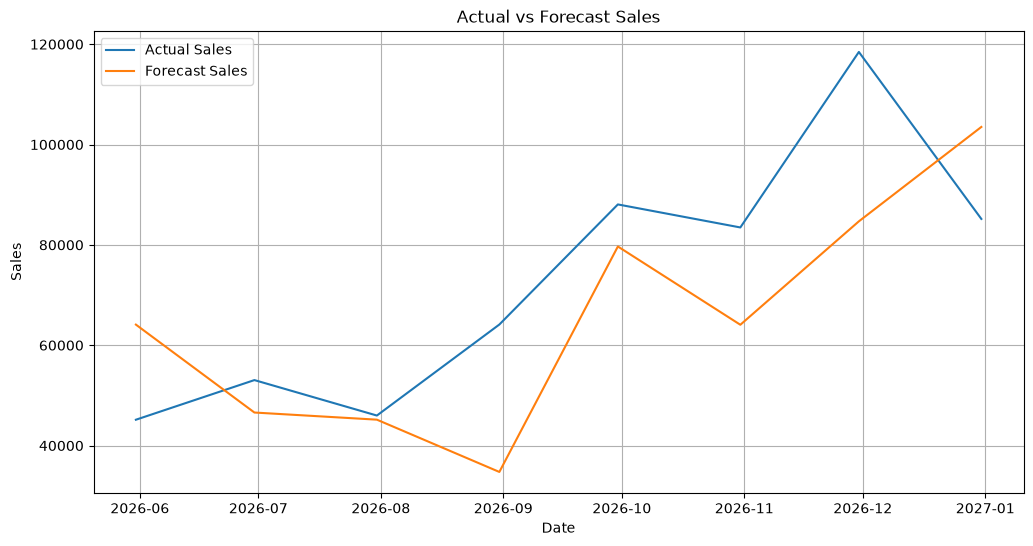

In [291]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(
    forecast_output.index,
    forecast_output["Actual Sales"],
    label="Actual Sales"
)

plt.plot(
    forecast_output.index,
    forecast_output["Forecast Sales"],
    label="Forecast Sales"
)

plt.title("Actual vs Forecast Sales")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.legend()
plt.grid(True)

plt.show()

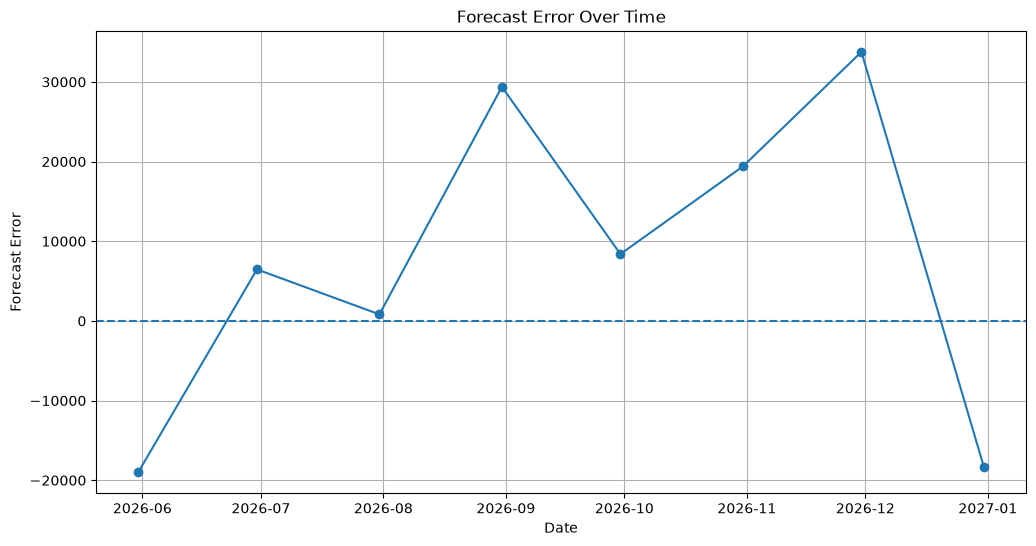

In [292]:
plt.figure(figsize=(12, 6))

plt.plot(
    forecast_output.index,
    forecast_output["Forecast Error"],
    marker="o"
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.title("Forecast Error Over Time")
plt.xlabel("Date")
plt.ylabel("Forecast Error")

plt.grid(True)

plt.show()

In [293]:
forecast_output["Absolute Error"] = (
    forecast_output["Forecast Error"].abs()
)

highest_errors = (
    forecast_output
    .sort_values("Absolute Error", ascending=False)
    .head(10)
)

print(highest_errors[
    [
        "Actual Sales",
        "Forecast Sales",
        "Forecast Error",
        "Absolute Error"
    ]
])

            Actual Sales  Forecast Sales  Forecast Error  Absolute Error
2026-11-30   118454.5050    84694.897432    33759.607568    33759.607568
2026-08-31    64129.7580    34748.994851    29380.763149    29380.763149
2026-10-31    83474.7832    64083.040358    19391.742842    19391.742842
2026-05-31    45155.4822    64114.144179   -18958.661979    18958.661979
2026-12-31    85175.0328   103507.905797   -18332.872997    18332.872997
2026-09-30    88064.5320    79681.345493     8383.186507     8383.186507
2026-06-30    53056.0777    46590.764421     6465.313279     6465.313279
2026-07-31    45989.4960    45168.544936      820.951064      820.951064


In [294]:
underestimated = (
    forecast_output["Forecast Error"] > 0
).sum()

overestimated = (
    forecast_output["Forecast Error"] < 0
).sum()

accurate = (
    forecast_output["Forecast Error"] == 0
).sum()

print("Underestimated periods:", underestimated)
print("Overestimated periods:", overestimated)
print("Exactly accurate periods:", accurate)

Underestimated periods: 6
Overestimated periods: 2
Exactly accurate periods: 0


In [295]:
forecast_analysis = forecast_output[
    [
        "Actual Sales",
        "Forecast Sales",
        "Forecast Error",
        "Absolute Error"
    ]
].copy()

forecast_analysis = forecast_analysis.reset_index()

print(forecast_analysis.head(10))

       index  Actual Sales  Forecast Sales  Forecast Error  Absolute Error
0 2026-05-31    45155.4822    64114.144179   -18958.661979    18958.661979
1 2026-06-30    53056.0777    46590.764421     6465.313279     6465.313279
2 2026-07-31    45989.4960    45168.544936      820.951064      820.951064
3 2026-08-31    64129.7580    34748.994851    29380.763149    29380.763149
4 2026-09-30    88064.5320    79681.345493     8383.186507     8383.186507
5 2026-10-31    83474.7832    64083.040358    19391.742842    19391.742842
6 2026-11-30   118454.5050    84694.897432    33759.607568    33759.607568
7 2026-12-31    85175.0328   103507.905797   -18332.872997    18332.872997


In [296]:
print("Rows:", len(forecast_analysis))
print("Columns:", len(forecast_analysis.columns))
print("\nColumn names:")
print(forecast_analysis.columns.tolist())

Rows: 8
Columns: 5

Column names:
['index', 'Actual Sales', 'Forecast Sales', 'Forecast Error', 'Absolute Error']


In [297]:
forecast_analysis_path = PROCESSED_DATA_DIR / "forecast_analysis.csv"

forecast_analysis.to_csv(
    forecast_analysis_path,
    index=False
)

print("Forecast analysis saved successfully!")
print("Saved to:", forecast_analysis_path)

Forecast analysis saved successfully!
Saved to: D:\InsightAI\data\processed\forecast_analysis.csv


In [298]:
saved_forecast = pd.read_csv(forecast_analysis_path)

print(saved_forecast.head())
print("\nShape:", saved_forecast.shape)

        index  Actual Sales  Forecast Sales  Forecast Error  Absolute Error
0  2026-05-31    45155.4822    64114.144179   -18958.661979    18958.661979
1  2026-06-30    53056.0777    46590.764421     6465.313279     6465.313279
2  2026-07-31    45989.4960    45168.544936      820.951064      820.951064
3  2026-08-31    64129.7580    34748.994851    29380.763149    29380.763149
4  2026-09-30    88064.5320    79681.345493     8383.186507     8383.186507

Shape: (8, 5)


In [299]:
highest_forecast = forecast_analysis.loc[
    forecast_analysis["Forecast Sales"].idxmax()
]

print("Highest Forecasted Sales Period:")
print(highest_forecast)

Highest Forecasted Sales Period:
index             2026-12-31 00:00:00
Actual Sales               85175.0328
Forecast Sales          103507.905797
Forecast Error          -18332.872997
Absolute Error           18332.872997
Name: 7, dtype: object


In [300]:
lowest_forecast = forecast_analysis.loc[
    forecast_analysis["Forecast Sales"].idxmin()
]

print("Lowest Forecasted Sales Period:")
print(lowest_forecast)

Lowest Forecasted Sales Period:
index             2026-08-31 00:00:00
Actual Sales                64129.758
Forecast Sales           34748.994851
Forecast Error           29380.763149
Absolute Error           29380.763149
Name: 3, dtype: object


In [301]:
forecast_max = forecast_analysis["Forecast Sales"].max()
forecast_min = forecast_analysis["Forecast Sales"].min()

forecast_range = forecast_max - forecast_min

print("Maximum Forecasted Sales:", forecast_max)
print("Minimum Forecasted Sales:", forecast_min)
print("Forecast Range:", forecast_range)

Maximum Forecasted Sales: 103507.90579698283
Minimum Forecasted Sales: 34748.994850834824
Forecast Range: 68758.91094614801


In [302]:
print("Columns:")
print(forecast_analysis.columns.tolist())

print("\nIndex name:")
print(forecast_analysis.index.name)

Columns:
['index', 'Actual Sales', 'Forecast Sales', 'Forecast Error', 'Absolute Error']

Index name:
None


In [303]:
forecast_analysis = forecast_analysis.rename(
    columns={"index": "Date"}
)

print(forecast_analysis.columns.tolist())

['Date', 'Actual Sales', 'Forecast Sales', 'Forecast Error', 'Absolute Error']


In [304]:
print(forecast_analysis["Date"].head())



0   2026-05-31
1   2026-06-30
2   2026-07-31
3   2026-08-31
4   2026-09-30
Name: Date, dtype: datetime64[us]


In [305]:
top_forecast_periods = (
    forecast_analysis
    .sort_values("Forecast Sales", ascending=False)
    .head(5)
)

print(
    top_forecast_periods[
        ["Date", "Forecast Sales"]
    ]
)

        Date  Forecast Sales
7 2026-12-31   103507.905797
6 2026-11-30    84694.897432
4 2026-09-30    79681.345493
0 2026-05-31    64114.144179
5 2026-10-31    64083.040358


In [306]:
bottom_forecast_periods = (
    forecast_analysis
    .sort_values("Forecast Sales", ascending=True)
    .head(5)
)

print(
    bottom_forecast_periods[
        ["Date", "Forecast Sales"]
    ]
)

        Date  Forecast Sales
3 2026-08-31    34748.994851
2 2026-07-31    45168.544936
1 2026-06-30    46590.764421
5 2026-10-31    64083.040358
0 2026-05-31    64114.144179


In [307]:
worst_forecast_periods = (
    forecast_analysis
    .sort_values("Absolute Error", ascending=False)
    .head(5)
)

print(
    worst_forecast_periods[
        [
            "Date",
            "Actual Sales",
            "Forecast Sales",
            "Forecast Error",
            "Absolute Error"
        ]
    ]
)

        Date  Actual Sales  Forecast Sales  Forecast Error  Absolute Error
6 2026-11-30   118454.5050    84694.897432    33759.607568    33759.607568
3 2026-08-31    64129.7580    34748.994851    29380.763149    29380.763149
5 2026-10-31    83474.7832    64083.040358    19391.742842    19391.742842
0 2026-05-31    45155.4822    64114.144179   -18958.661979    18958.661979
7 2026-12-31    85175.0328   103507.905797   -18332.872997    18332.872997


In [308]:
worst_forecast_periods = worst_forecast_periods.copy()

worst_forecast_periods["Prediction Type"] = worst_forecast_periods[
    "Forecast Error"
].apply(
    lambda x: "Underestimated"
    if x > 0
    else "Overestimated"
    if x < 0
    else "Accurate"
)

print(
    worst_forecast_periods[
        [
            "Date",
            "Actual Sales",
            "Forecast Sales",
            "Forecast Error",
            "Absolute Error",
            "Prediction Type"
        ]
    ]
)

        Date  Actual Sales  Forecast Sales  Forecast Error  Absolute Error  \
6 2026-11-30   118454.5050    84694.897432    33759.607568    33759.607568   
3 2026-08-31    64129.7580    34748.994851    29380.763149    29380.763149   
5 2026-10-31    83474.7832    64083.040358    19391.742842    19391.742842   
0 2026-05-31    45155.4822    64114.144179   -18958.661979    18958.661979   
7 2026-12-31    85175.0328   103507.905797   -18332.872997    18332.872997   

  Prediction Type  
6  Underestimated  
3  Underestimated  
5  Underestimated  
0   Overestimated  
7   Overestimated  


In [309]:
mean_error = forecast_analysis["Forecast Error"].mean()

print("Mean Forecast Error:", mean_error)

Mean Forecast Error: 7613.753679117899


In [310]:
highest_sales = forecast_analysis.loc[
    forecast_analysis["Forecast Sales"].idxmax()
]

lowest_sales = forecast_analysis.loc[
    forecast_analysis["Forecast Sales"].idxmin()
]

print("========== FORECAST BUSINESS INSIGHTS ==========")

print(
    f"Highest forecasted sales: "
    f"{highest_sales['Forecast Sales']:.2f} "
    f"on {highest_sales['Date']}"
)

print(
    f"Lowest forecasted sales: "
    f"{lowest_sales['Forecast Sales']:.2f} "
    f"on {lowest_sales['Date']}"
)

print(f"MAE: {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"MAPE: {mape:.2f}%")
print(f"Mean Forecast Error: {mean_error:.2f}")

if mean_error > 0:
    print("Forecast tendency: The model generally underestimated sales.")
elif mean_error < 0:
    print("Forecast tendency: The model generally overestimated sales.")
else:
    print("Forecast tendency: No overall forecast bias detected.")

print("================================================")

========== FORECAST BUSINESS INSIGHTS ==========
Highest forecasted sales: 103507.91 on 2026-12-31 00:00:00
Lowest forecasted sales: 34748.99 on 2026-08-31 00:00:00
MAE: 16936.64
RMSE: 19960.14
MAPE: 23.07%
Mean Forecast Error: 7613.75
Forecast tendency: The model generally underestimated sales.


In [311]:
business_insights = {
    "Highest Forecasted Sales": highest_sales["Forecast Sales"],
    "Highest Sales Date": highest_sales["Date"],
    "Lowest Forecasted Sales": lowest_sales["Forecast Sales"],
    "Lowest Sales Date": lowest_sales["Date"],
    "MAE": mae,
    "RMSE": rmse,
    "MAPE": mape,
    "Mean Forecast Error": mean_error
}

print(business_insights)

{'Highest Forecasted Sales': np.float64(103507.90579698283), 'Highest Sales Date': Timestamp('2026-12-31 00:00:00'), 'Lowest Forecasted Sales': np.float64(34748.994850834824), 'Lowest Sales Date': Timestamp('2026-08-31 00:00:00'), 'MAE': 16936.63742317406, 'RMSE': np.float64(19960.13898267474), 'MAPE': np.float64(23.06807462627663), 'Mean Forecast Error': np.float64(7613.753679117899)}


In [312]:
business_insights_df = pd.DataFrame(
    [business_insights]
)

print(business_insights_df)

   Highest Forecasted Sales Highest Sales Date  Lowest Forecasted Sales  \
0             103507.905797         2026-12-31             34748.994851   

  Lowest Sales Date           MAE          RMSE       MAPE  \
0        2026-08-31  16936.637423  19960.138983  23.068075   

   Mean Forecast Error  
0          7613.753679  


In [313]:
insights_path = PROCESSED_DATA_DIR / "forecast_business_insights.csv"

business_insights_df.to_csv(
    insights_path,
    index=False
)

print("Business insights saved successfully!")
print("Saved to:", insights_path)

Business insights saved successfully!
Saved to: D:\InsightAI\data\processed\forecast_business_insights.csv


In [314]:
print(
    pd.read_csv(insights_path)
)

   Highest Forecasted Sales Highest Sales Date  Lowest Forecasted Sales  \
0             103507.905797         2026-12-31             34748.994851   

  Lowest Sales Date           MAE          RMSE       MAPE  \
0        2026-08-31  16936.637423  19960.138983  23.068075   

   Mean Forecast Error  
0          7613.753679  


In [315]:
if mape < 10:
    forecast_rating = "Excellent"
elif mape < 20:
    forecast_rating = "Good"
elif mape < 50:
    forecast_rating = "Reasonable"
else:
    forecast_rating = "Poor"

print("Forecast MAPE:", round(mape, 2), "%")
print("Forecast Performance:", forecast_rating)

Forecast MAPE: 23.07 %
Forecast Performance: Reasonable


In [316]:
forecast_conclusion = f"""
InsightAI Sales Forecasting Conclusion

The SARIMA model was evaluated using MAE, RMSE, and MAPE.

MAE: {mae:.2f}
RMSE: {rmse:.2f}
MAPE: {mape:.2f}%

The highest forecasted sales were {highest_sales["Forecast Sales"]:.2f}
on {highest_sales["Date"]}.

The lowest forecasted sales were {lowest_sales["Forecast Sales"]:.2f}
on {lowest_sales["Date"]}.

The mean forecast error was {mean_error:.2f}.
"""

if mean_error > 0:
    forecast_conclusion += (
        "\nThe model generally underestimated sales."
    )
elif mean_error < 0:
    forecast_conclusion += (
        "\nThe model generally overestimated sales."
    )
else:
    forecast_conclusion += (
        "\nThe model showed no overall forecast bias."
    )

forecast_conclusion += (
    "\n\nOverall, the forecasting results provide a useful "
    "baseline for future sales planning, but the model should "
    "be monitored and improved if higher forecasting accuracy "
    "is required."
)

print(forecast_conclusion)


InsightAI Sales Forecasting Conclusion

The SARIMA model was evaluated using MAE, RMSE, and MAPE.

MAE: 16936.64
RMSE: 19960.14
MAPE: 23.07%

The highest forecasted sales were 103507.91
on 2026-12-31 00:00:00.

The lowest forecasted sales were 34748.99
on 2026-08-31 00:00:00.

The mean forecast error was 7613.75.

The model generally underestimated sales.

Overall, the forecasting results provide a useful baseline for future sales planning, but the model should be monitored and improved if higher forecasting accuracy is required.


In [317]:
conclusion_path = PROCESSED_DATA_DIR / "forecast_conclusion.txt"

with open(conclusion_path, "w", encoding="utf-8") as file:
    file.write(forecast_conclusion)

print("Forecast conclusion saved successfully!")
print("Saved to:", conclusion_path)

Forecast conclusion saved successfully!
Saved to: D:\InsightAI\data\processed\forecast_conclusion.txt


In [318]:
with open(conclusion_path, "r", encoding="utf-8") as file:
    saved_conclusion = file.read()

print(saved_conclusion)


InsightAI Sales Forecasting Conclusion

The SARIMA model was evaluated using MAE, RMSE, and MAPE.

MAE: 16936.64
RMSE: 19960.14
MAPE: 23.07%

The highest forecasted sales were 103507.91
on 2026-12-31 00:00:00.

The lowest forecasted sales were 34748.99
on 2026-08-31 00:00:00.

The mean forecast error was 7613.75.

The model generally underestimated sales.

Overall, the forecasting results provide a useful baseline for future sales planning, but the model should be monitored and improved if higher forecasting accuracy is required.


In [319]:
print("Customer Segments:")
print(df["Segment"].unique())

Customer Segments:
<StringArray>
['Consumer', 'Home Office', 'Corporate']
Length: 3, dtype: str


In [320]:
print("\nRecords by Segment:")
print(df["Segment"].value_counts())


Records by Segment:
Segment
Consumer       5281
Corporate      3090
Home Office    1823
Name: count, dtype: int64


In [321]:
segment_analysis = (
    df.groupby("Segment")
      .agg(
          Total_Sales=("Sales", "sum"),
          Total_Profit=("Profit", "sum"),
          Total_Quantity=("Quantity", "sum"),
          Total_Orders=("Order ID", "nunique")
      )
      .reset_index()
)

print(segment_analysis)

       Segment   Total_Sales  Total_Profit  Total_Quantity  Total_Orders
0     Consumer  1.170660e+06   136371.4463           19844          2628
1    Corporate  7.158061e+05    94249.6400           11898          1552
2  Home Office  4.400684e+05    61675.7283            6912           931


In [322]:
segment_analysis["Profit_Margin_%"] = (
    segment_analysis["Total_Profit"]
    / segment_analysis["Total_Sales"]
) * 100

print(
    segment_analysis[
        [
            "Segment",
            "Total_Sales",
            "Total_Profit",
            "Profit_Margin_%"
        ]
    ]
)

       Segment   Total_Sales  Total_Profit  Profit_Margin_%
0     Consumer  1.170660e+06   136371.4463        11.649110
1    Corporate  7.158061e+05    94249.6400        13.166923
2  Home Office  4.400684e+05    61675.7283        14.015031


In [323]:
best_segment = segment_analysis.loc[
    segment_analysis["Total_Profit"].idxmax()
]

weakest_segment = segment_analysis.loc[
    segment_analysis["Total_Profit"].idxmin()
]

print("========== SEGMENT PERFORMANCE ==========")

print(
    f"Best Segment: {best_segment['Segment']}"
)

print(
    f"Best Segment Profit: "
    f"{best_segment['Total_Profit']:.2f}"
)

print(
    f"Best Segment Profit Margin: "
    f"{best_segment['Profit_Margin_%']:.2f}%"
)

print()

print(
    f"Weakest Segment: {weakest_segment['Segment']}"
)

print(
    f"Weakest Segment Profit: "
    f"{weakest_segment['Total_Profit']:.2f}"
)

print(
    f"Weakest Segment Profit Margin: "
    f"{weakest_segment['Profit_Margin_%']:.2f}%"
)

print("==========================================")

========== SEGMENT PERFORMANCE ==========
Best Segment: Consumer
Best Segment Profit: 136371.45
Best Segment Profit Margin: 11.65%

Weakest Segment: Home Office
Weakest Segment Profit: 61675.73
Weakest Segment Profit Margin: 14.02%


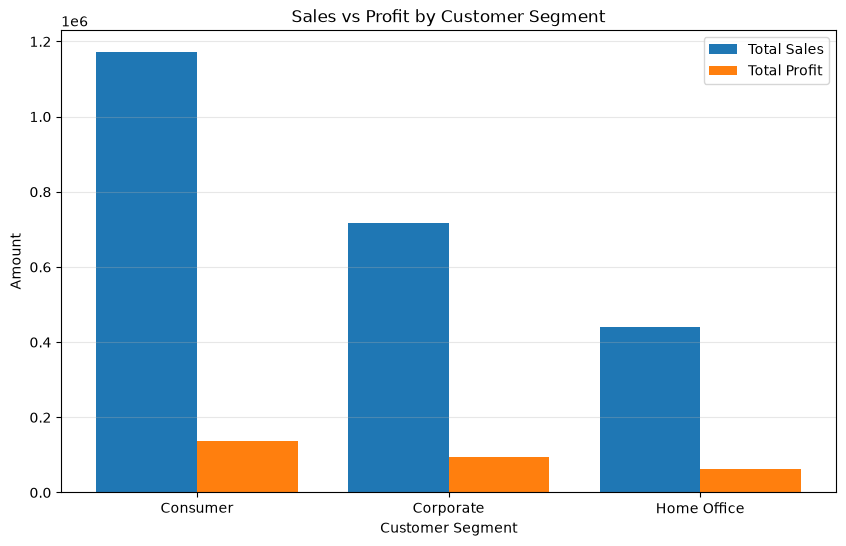

In [324]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

x = range(len(segment_analysis))

plt.bar(
    [i - 0.2 for i in x],
    segment_analysis["Total_Sales"],
    width=0.4,
    label="Total Sales"
)

plt.bar(
    [i + 0.2 for i in x],
    segment_analysis["Total_Profit"],
    width=0.4,
    label="Total Profit"
)

plt.xticks(
    x,
    segment_analysis["Segment"]
)

plt.title("Sales vs Profit by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Amount")
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.show()

In [325]:
highest_sales_segment = segment_analysis.loc[
    segment_analysis["Total_Sales"].idxmax()
]

highest_profit_segment = segment_analysis.loc[
    segment_analysis["Total_Profit"].idxmax()
]

highest_margin_segment = segment_analysis.loc[
    segment_analysis["Profit_Margin_%"].idxmax()
]

print("========== SEGMENT BUSINESS INSIGHTS ==========")

print(
    f"Highest Sales Segment: "
    f"{highest_sales_segment['Segment']}"
)

print(
    f"Highest Sales: "
    f"{highest_sales_segment['Total_Sales']:.2f}"
)

print()

print(
    f"Highest Profit Segment: "
    f"{highest_profit_segment['Segment']}"
)

print(
    f"Highest Profit: "
    f"{highest_profit_segment['Total_Profit']:.2f}"
)

print()

print(
    f"Highest Profit Margin Segment: "
    f"{highest_margin_segment['Segment']}"
)

print(
    f"Profit Margin: "
    f"{highest_margin_segment['Profit_Margin_%']:.2f}%"
)

print("===============================================")

========== SEGMENT BUSINESS INSIGHTS ==========
Highest Sales Segment: Consumer
Highest Sales: 1170659.79

Highest Profit Segment: Consumer
Highest Profit: 136371.45

Highest Profit Margin Segment: Home Office
Profit Margin: 14.02%


In [326]:
segment_analysis_path = PROCESSED_DATA_DIR / "segment_analysis.csv"

segment_analysis.to_csv(
    segment_analysis_path,
    index=False
)

print("Segment analysis saved successfully!")
print("Saved to:", segment_analysis_path)

Segment analysis saved successfully!
Saved to: D:\InsightAI\data\processed\segment_analysis.csv


In [327]:
saved_segment_analysis = pd.read_csv(
    segment_analysis_path
)

print(saved_segment_analysis)

print("\nShape:", saved_segment_analysis.shape)
print("\nColumns:")
print(saved_segment_analysis.columns.tolist())

       Segment   Total_Sales  Total_Profit  Total_Quantity  Total_Orders  \
0     Consumer  1.170660e+06   136371.4463           19844          2628   
1    Corporate  7.158061e+05    94249.6400           11898          1552   
2  Home Office  4.400684e+05    61675.7283            6912           931   

   Profit_Margin_%  
0        11.649110  
1        13.166923  
2        14.015031  

Shape: (3, 6)

Columns:
['Segment', 'Total_Sales', 'Total_Profit', 'Total_Quantity', 'Total_Orders', 'Profit_Margin_%']


In [328]:
print("Product Categories:")
print(df["Category"].unique())

print("\nRecords by Category:")
print(df["Category"].value_counts())

Product Categories:
<StringArray>
['Office Supplies', 'Furniture', 'Technology']
Length: 3, dtype: str

Records by Category:
Category
Office Supplies    6128
Furniture          2201
Technology         1865
Name: count, dtype: int64


In [329]:
category_analysis = (
    df.groupby("Category")
      .agg(
          Total_Sales=("Sales", "sum"),
          Total_Profit=("Profit", "sum"),
          Total_Quantity=("Quantity", "sum"),
          Total_Orders=("Order ID", "nunique")
      )
      .reset_index()
)

print(category_analysis)

          Category  Total_Sales  Total_Profit  Total_Quantity  Total_Orders
0        Furniture  754747.7613    19729.9956            8369          1819
1  Office Supplies  731893.3140   126023.4434           23268          3812
2       Technology  839893.2790   146543.3756            7017          1560


In [330]:
category_analysis["Profit_Margin_%"] = (
    category_analysis["Total_Profit"]
    / category_analysis["Total_Sales"]
) * 100

print(
    category_analysis[
        [
            "Category",
            "Total_Sales",
            "Total_Profit",
            "Total_Quantity",
            "Total_Orders",
            "Profit_Margin_%"
        ]
    ]
)

          Category  Total_Sales  Total_Profit  Total_Quantity  Total_Orders  \
0        Furniture  754747.7613    19729.9956            8369          1819   
1  Office Supplies  731893.3140   126023.4434           23268          3812   
2       Technology  839893.2790   146543.3756            7017          1560   

   Profit_Margin_%  
0         2.614118  
1        17.218827  
2        17.447857  


In [331]:
highest_sales_category = category_analysis.loc[
    category_analysis["Total_Sales"].idxmax()
]

highest_profit_category = category_analysis.loc[
    category_analysis["Total_Profit"].idxmax()
]

highest_margin_category = category_analysis.loc[
    category_analysis["Profit_Margin_%"].idxmax()
]

lowest_profit_category = category_analysis.loc[
    category_analysis["Total_Profit"].idxmin()
]

print("========== CATEGORY PERFORMANCE ==========")

print(
    f"Highest Sales Category: "
    f"{highest_sales_category['Category']}"
)

print(
    f"Highest Profit Category: "
    f"{highest_profit_category['Category']}"
)

print(
    f"Highest Profit Margin Category: "
    f"{highest_margin_category['Category']}"
)

print(
    f"Lowest Profit Category: "
    f"{lowest_profit_category['Category']}"
)

print("===========================================")

========== CATEGORY PERFORMANCE ==========
Highest Sales Category: Technology
Highest Profit Category: Technology
Highest Profit Margin Category: Technology
Lowest Profit Category: Furniture


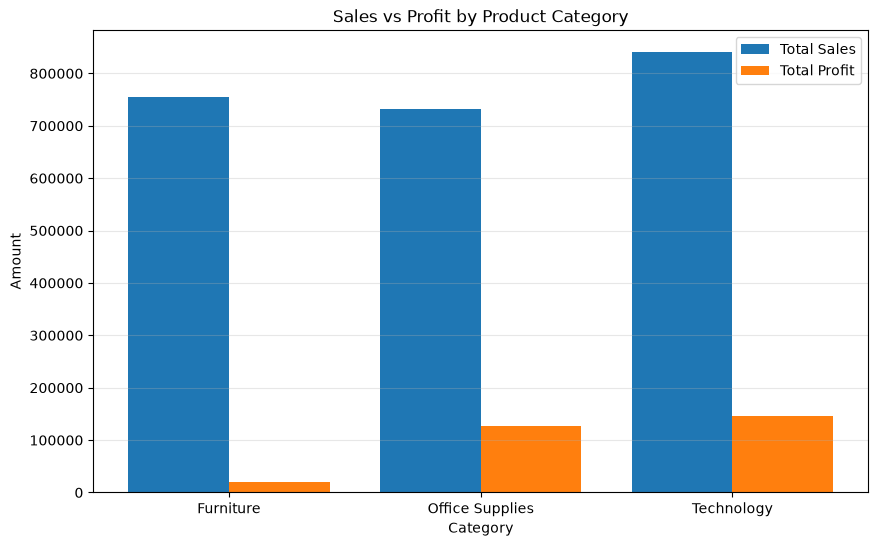

In [332]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

x = range(len(category_analysis))

plt.bar(
    [i - 0.2 for i in x],
    category_analysis["Total_Sales"],
    width=0.4,
    label="Total Sales"
)

plt.bar(
    [i + 0.2 for i in x],
    category_analysis["Total_Profit"],
    width=0.4,
    label="Total Profit"
)

plt.xticks(
    x,
    category_analysis["Category"]
)

plt.title("Sales vs Profit by Product Category")
plt.xlabel("Category")
plt.ylabel("Amount")
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.show()

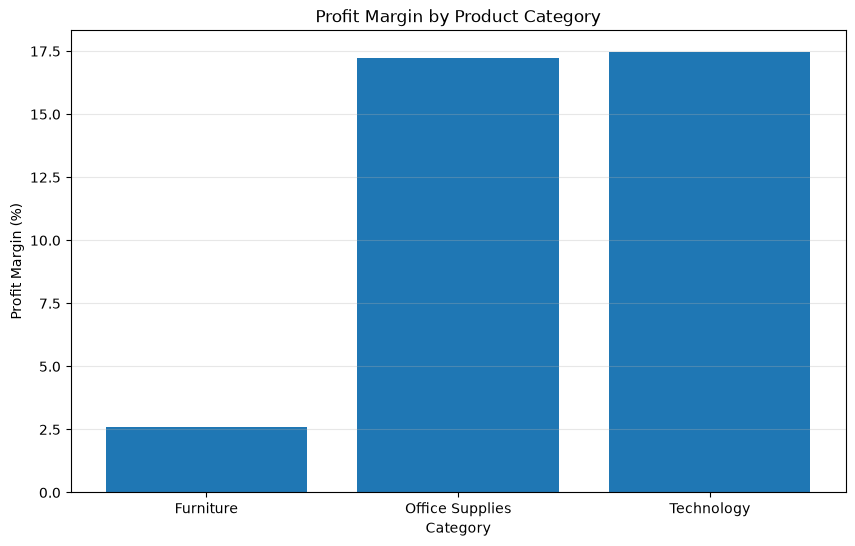

In [333]:
plt.figure(figsize=(10, 6))

plt.bar(
    category_analysis["Category"],
    category_analysis["Profit_Margin_%"]
)

plt.title("Profit Margin by Product Category")
plt.xlabel("Category")
plt.ylabel("Profit Margin (%)")
plt.grid(axis="y", alpha=0.3)

plt.show()

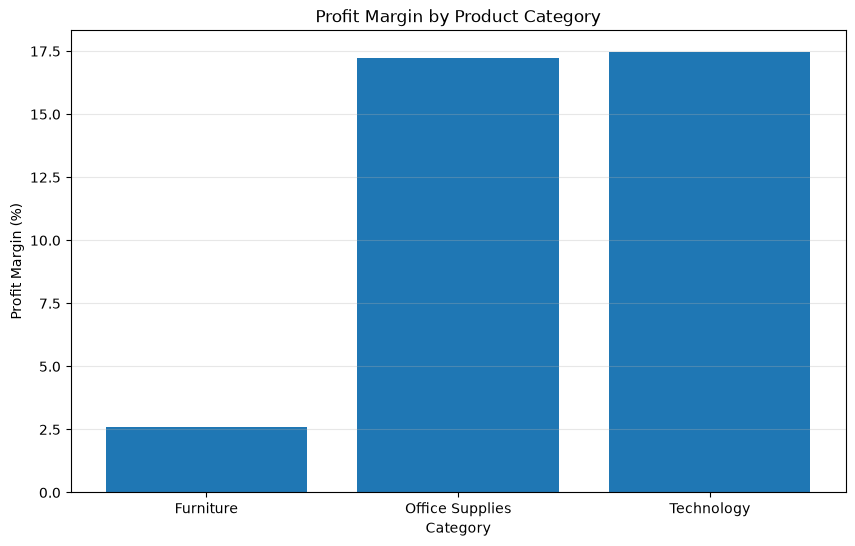

In [334]:
plt.figure(figsize=(10, 6))

plt.bar(
    category_analysis["Category"],
    category_analysis["Profit_Margin_%"]
)

plt.title("Profit Margin by Product Category")
plt.xlabel("Category")
plt.ylabel("Profit Margin (%)")
plt.grid(axis="y", alpha=0.3)

plt.show()

In [335]:
category_analysis_path = (
    PROCESSED_DATA_DIR / "category_analysis.csv"
)

category_analysis.to_csv(
    category_analysis_path,
    index=False
)

print("Category analysis saved successfully!")
print("Saved to:", category_analysis_path)

Category analysis saved successfully!
Saved to: D:\InsightAI\data\processed\category_analysis.csv


In [336]:
saved_category_analysis = pd.read_csv(
    category_analysis_path
)

print(saved_category_analysis)

print("\nShape:", saved_category_analysis.shape)

print("\nColumns:")
print(saved_category_analysis.columns.tolist())

          Category  Total_Sales  Total_Profit  Total_Quantity  Total_Orders  \
0        Furniture  754747.7613    19729.9956            8369          1819   
1  Office Supplies  731893.3140   126023.4434           23268          3812   
2       Technology  839893.2790   146543.3756            7017          1560   

   Profit_Margin_%  
0         2.614118  
1        17.218827  
2        17.447857  

Shape: (3, 6)

Columns:
['Category', 'Total_Sales', 'Total_Profit', 'Total_Quantity', 'Total_Orders', 'Profit_Margin_%']


In [337]:
print("Number of Sub-Categories:", df["Sub-Category"].nunique())

print("\nSub-Categories:")
print(df["Sub-Category"].unique())

Number of Sub-Categories: 17

Sub-Categories:
<StringArray>
[      'Paper',     'Binders',      'Labels',     'Storage',         'Art',
      'Chairs',   'Fasteners',      'Phones', 'Furnishings', 'Accessories',
   'Bookcases',   'Envelopes',  'Appliances',      'Tables',    'Supplies',
    'Machines',     'Copiers']
Length: 17, dtype: str


In [338]:
print("Number of Sub-Categories:", df["Sub-Category"].nunique())

print("\nSub-Categories:")
print(df["Sub-Category"].unique())

Number of Sub-Categories: 17

Sub-Categories:
<StringArray>
[      'Paper',     'Binders',      'Labels',     'Storage',         'Art',
      'Chairs',   'Fasteners',      'Phones', 'Furnishings', 'Accessories',
   'Bookcases',   'Envelopes',  'Appliances',      'Tables',    'Supplies',
    'Machines',     'Copiers']
Length: 17, dtype: str


In [339]:
subcategory_analysis = (
    df.groupby("Sub-Category")
      .agg(
          Total_Sales=("Sales", "sum"),
          Total_Profit=("Profit", "sum"),
          Total_Quantity=("Quantity", "sum"),
          Total_Orders=("Order ID", "nunique")
      )
      .reset_index()
)

print(subcategory_analysis)

   Sub-Category  Total_Sales  Total_Profit  Total_Quantity  Total_Orders
0   Accessories  167380.3180    41936.6357            2976           718
1    Appliances  108213.1850    18329.4844            1750           459
2           Art   27659.0140     6653.1962            3092           756
3       Binders  207354.8810    31426.1003            6071          1339
4     Bookcases  115361.2043    -3632.0736             878           228
5        Chairs  335768.2490    27223.5323            2431           591
6       Copiers  150745.2900    56093.9365             242            70
7     Envelopes   16528.3620     6988.0247             914           251
8     Fasteners    8532.2400     2428.6358             980           226
9   Furnishings   95598.1260    13891.7430            3799           919
10       Labels   12695.0420     5572.7780            1410           348
11     Machines  189925.0310     3461.9769             442           114
12        Paper   79540.5380    34511.5070         

In [340]:
subcategory_analysis["Profit_Margin_%"] = (
    subcategory_analysis["Total_Profit"]
    / subcategory_analysis["Total_Sales"]
) * 100

print(
    subcategory_analysis[
        [
            "Sub-Category",
            "Total_Sales",
            "Total_Profit",
            "Total_Quantity",
            "Total_Orders",
            "Profit_Margin_%"
        ]
    ]
)

   Sub-Category  Total_Sales  Total_Profit  Total_Quantity  Total_Orders  \
0   Accessories  167380.3180    41936.6357            2976           718   
1    Appliances  108213.1850    18329.4844            1750           459   
2           Art   27659.0140     6653.1962            3092           756   
3       Binders  207354.8810    31426.1003            6071          1339   
4     Bookcases  115361.2043    -3632.0736             878           228   
5        Chairs  335768.2490    27223.5323            2431           591   
6       Copiers  150745.2900    56093.9365             242            70   
7     Envelopes   16528.3620     6988.0247             914           251   
8     Fasteners    8532.2400     2428.6358             980           226   
9   Furnishings   95598.1260    13891.7430            3799           919   
10       Labels   12695.0420     5572.7780            1410           348   
11     Machines  189925.0310     3461.9769             442           114   
12        Pa

In [341]:
highest_margin_subcategory = subcategory_analysis.loc[
    subcategory_analysis["Profit_Margin_%"].idxmax()
]

lowest_margin_subcategory = subcategory_analysis.loc[
    subcategory_analysis["Profit_Margin_%"].idxmin()
]

print("Highest Profit Margin:")
print(
    highest_margin_subcategory[
        ["Sub-Category", "Profit_Margin_%"]
    ]
)

print("\nLowest Profit Margin:")
print(
    lowest_margin_subcategory[
        ["Sub-Category", "Profit_Margin_%"]
    ]
)

Highest Profit Margin:
Sub-Category          Labels
Profit_Margin_%    43.897279
Name: 10, dtype: object

Lowest Profit Margin:
Sub-Category         Tables
Profit_Margin_%   -8.534367
Name: 16, dtype: object


In [342]:
highest_margin_subcategory = subcategory_analysis.loc[
    subcategory_analysis["Profit_Margin_%"].idxmax()
]

lowest_margin_subcategory = subcategory_analysis.loc[
    subcategory_analysis["Profit_Margin_%"].idxmin()
]

print("Highest Profit Margin:")
print(
    highest_margin_subcategory[
        ["Sub-Category", "Profit_Margin_%"]
    ]
)

print("\nLowest Profit Margin:")
print(
    lowest_margin_subcategory[
        ["Sub-Category", "Profit_Margin_%"]
    ]
)

Highest Profit Margin:
Sub-Category          Labels
Profit_Margin_%    43.897279
Name: 10, dtype: object

Lowest Profit Margin:
Sub-Category         Tables
Profit_Margin_%   -8.534367
Name: 16, dtype: object


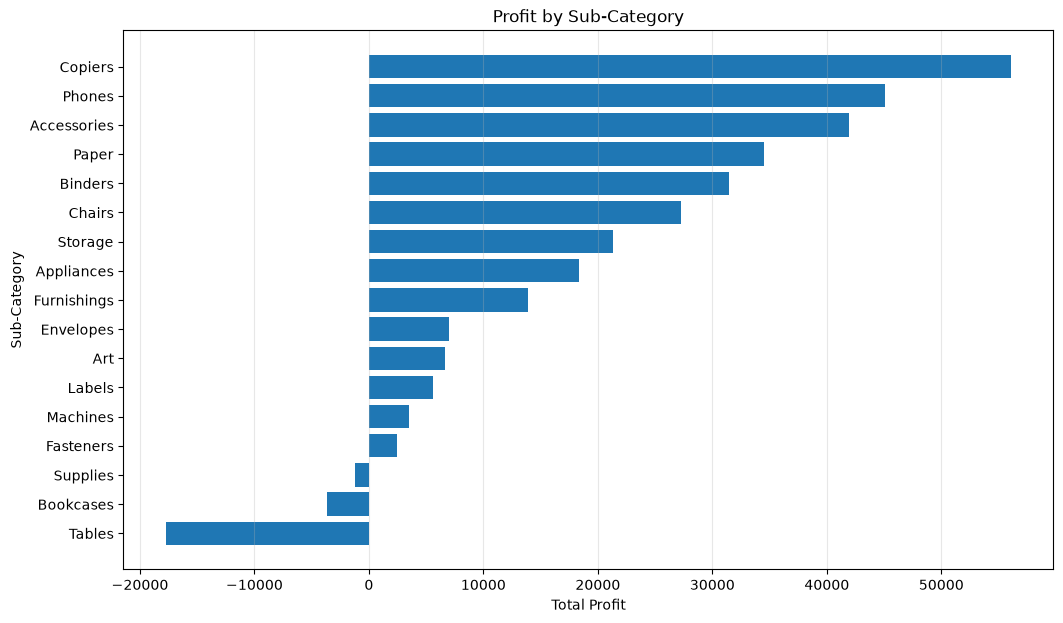

In [343]:
import matplotlib.pyplot as plt

profit_sorted = subcategory_analysis.sort_values(
    "Total_Profit",
    ascending=True
)

plt.figure(figsize=(12, 7))

plt.barh(
    profit_sorted["Sub-Category"],
    profit_sorted["Total_Profit"]
)

plt.title("Profit by Sub-Category")
plt.xlabel("Total Profit")
plt.ylabel("Sub-Category")
plt.grid(axis="x", alpha=0.3)

plt.show()

In [344]:
subcategory_analysis_path = (
    PROCESSED_DATA_DIR / "subcategory_analysis.csv"
)

subcategory_analysis.to_csv(
    subcategory_analysis_path,
    index=False
)

print("Sub-category analysis saved successfully!")
print("Saved to:", subcategory_analysis_path)

Sub-category analysis saved successfully!
Saved to: D:\InsightAI\data\processed\subcategory_analysis.csv


In [345]:
print("Total Unique Products:", df["Product Name"].nunique())

print("\nSample Products:")
print(df["Product Name"].drop_duplicates().head(10))

Total Unique Products: 1849

Sample Products:
0    Message Book, Wirebound, Four 5 1/2" X 4" Form...
1           GBC Standard Plastic Binding Systems Combs
2                                            Avery 508
3                        SAFCO Boltless Steel Shelving
4    Avery Hi-Liter EverBold Pen Style Fluorescent ...
5              Global Deluxe High-Back Manager's Chair
6              Rogers Handheld Barrel Pencil Sharpener
7    Dixon Prang Watercolor Pencils, 10-Color Set w...
8                  Ibico Hi-Tech Manual Binding System
9            Alliance Super-Size Bands, Assorted Sizes
Name: Product Name, dtype: str


In [346]:
product_analysis = (
    df.groupby("Product Name")
      .agg(
          Total_Sales=("Sales", "sum"),
          Total_Profit=("Profit", "sum"),
          Total_Quantity=("Quantity", "sum"),
          Total_Orders=("Order ID", "nunique")
      )
      .reset_index()
)

print(product_analysis.head(10))
print("\nTotal Products:", len(product_analysis))

                                        Product Name  Total_Sales  \
0  "While you Were Out" Message Book, One Form pe...       25.228   
1           #10 Gummed Flap White Envelopes, 100/Box       41.300   
2                      #10 Self-Seal White Envelopes      108.682   
3         #10 White Business Envelopes,4 1/8 x 9 1/2      488.904   
4            #10- 4 1/8" x 9 1/2" Recycled Envelopes      286.672   
5       #10- 4 1/8" x 9 1/2" Security-Tint Envelopes      146.688   
6  #10-4 1/8" x 9 1/2" Premium Diagonal Seam Enve...      176.288   
7                 #6 3/4 Gummed Flap White Envelopes       71.280   
8  1.7 Cubic Foot Compact "Cube" Office Refrigera...     2706.080   
9  1/4 Fold Party Design Invitations & White Enve...       49.980   

   Total_Profit  Total_Quantity  Total_Orders  
0       10.3880               8             3  
1       16.7678              11             4  
2       52.1230              10             4  
3      223.1408              32             7  


In [347]:
top_sales_products = (
    product_analysis
    .sort_values("Total_Sales", ascending=False)
    .head(10)
)

top_profit_products = (
    product_analysis
    .sort_values("Total_Profit", ascending=False)
    .head(10)
)

lowest_profit_products = (
    product_analysis
    .sort_values("Total_Profit", ascending=True)
    .head(10)
)

print("========== TOP 10 PRODUCTS BY SALES ==========")
print(
    top_sales_products[
        ["Product Name", "Total_Sales", "Total_Profit"]
    ]
)

print("\n========== TOP 10 PRODUCTS BY PROFIT ==========")
print(
    top_profit_products[
        ["Product Name", "Total_Sales", "Total_Profit"]
    ]
)

print("\n========== 10 LOWEST-PROFIT PRODUCTS ==========")
print(
    lowest_profit_products[
        ["Product Name", "Total_Sales", "Total_Profit"]
    ]
)

========== TOP 10 PRODUCTS BY SALES ==========
                                          Product Name  Total_Sales  \
404              Canon imageCLASS 2200 Advanced Copier    61599.824   
649  Fellowes PB500 Electric Punch Plastic Comb Bin...    27453.384   
444  Cisco TelePresence System EX90 Videoconferenci...    22638.480   
785       HON 5400 Series Task Chairs for Big and Tall    21870.576   
685         GBC DocuBind TL300 Electric Binding System    19823.479   
687   GBC Ibimaster 500 Manual ProClick Binding System    19024.500   
804               Hewlett Packard LaserJet 3310 Copier    18839.686   
786  HP Designjet T520 Inkjet Large Format Printer ...    18374.895   
682          GBC DocuBind P400 Electric Binding System    17965.068   
812        High Speed Automatic Electric Letter Opener    17030.312   

     Total_Profit  
404  2.519993e+04  
649  7.753039e+03  
444 -1.811078e+03  
785  3.410605e-13  
685  2.233505e+03  
687  7.609800e+02  
804  6.983884e+03  
786  4.0949

In [348]:
product_analysis["Profit_Margin_%"] = (
    product_analysis["Total_Profit"]
    / product_analysis["Total_Sales"]
) * 100

print(
    product_analysis[
        [
            "Product Name",
            "Total_Sales",
            "Total_Profit",
            "Profit_Margin_%"
        ]
    ].head(10)
)

                                        Product Name  Total_Sales  \
0  "While you Were Out" Message Book, One Form pe...       25.228   
1           #10 Gummed Flap White Envelopes, 100/Box       41.300   
2                      #10 Self-Seal White Envelopes      108.682   
3         #10 White Business Envelopes,4 1/8 x 9 1/2      488.904   
4            #10- 4 1/8" x 9 1/2" Recycled Envelopes      286.672   
5       #10- 4 1/8" x 9 1/2" Security-Tint Envelopes      146.688   
6  #10-4 1/8" x 9 1/2" Premium Diagonal Seam Enve...      176.288   
7                 #6 3/4 Gummed Flap White Envelopes       71.280   
8  1.7 Cubic Foot Compact "Cube" Office Refrigera...     2706.080   
9  1/4 Fold Party Design Invitations & White Enve...       49.980   

   Total_Profit  Profit_Margin_%  
0       10.3880        41.176471  
1       16.7678        40.600000  
2       52.1230        47.959184  
3      223.1408        45.641026  
4      115.2806        40.213415  
5       64.8636        44.2187

In [349]:
highest_margin_product = product_analysis.loc[
    product_analysis["Profit_Margin_%"].idxmax()
]

lowest_margin_product = product_analysis.loc[
    product_analysis["Profit_Margin_%"].idxmin()
]

print("========== PRODUCT MARGIN INSIGHTS ==========")

print(
    f"Highest Margin Product: "
    f"{highest_margin_product['Product Name']}"
)

print(
    f"Profit Margin: "
    f"{highest_margin_product['Profit_Margin_%']:.2f}%"
)

print()

print(
    f"Lowest Margin Product: "
    f"{lowest_margin_product['Product Name']}"
)

print(
    f"Profit Margin: "
    f"{lowest_margin_product['Profit_Margin_%']:.2f}%"
)

print("==============================================")

========== PRODUCT MARGIN INSIGHTS ==========
Highest Margin Product: Adams Telephone Message Book w/Frequently-Called Numbers Space, 400 Messages per Book
Profit Margin: 50.00%

Lowest Margin Product: Eureka Disposable Bags for Sanitaire Vibra Groomer I Upright Vac
Profit Margin: -275.00%


In [350]:
loss_making_products = product_analysis[
    product_analysis["Total_Profit"] < 0
].sort_values(
    "Total_Profit",
    ascending=True
)

print("Number of Loss-Making Products:", len(loss_making_products))

print("\n========== LOSS-MAKING PRODUCTS ==========")

print(
    loss_making_products[
        [
            "Product Name",
            "Total_Sales",
            "Total_Profit",
            "Profit_Margin_%"
        ]
    ].head(10)
)

Number of Loss-Making Products: 302

========== LOSS-MAKING PRODUCTS ==========
                                           Product Name  Total_Sales  \
475           Cubify CubeX 3D Printer Double Head Print    11099.963   
984           Lexmark MX611dhe Monochrome Laser Printer    16829.901   
476           Cubify CubeX 3D Printer Triple Head Print     7999.980   
425   Chromcraft Bull-Nose Wood Oval Conference Tabl...     9917.640   
376   Bush Advantage Collection Racetrack Conference...     9544.725   
682           GBC DocuBind P400 Electric Binding System    17965.068   
444   Cisco TelePresence System EX90 Videoconferenci...    22638.480   
1042  Martin Yale Chadless Opener Electric Letter Op...    16656.200   
285                        Balt Solid Wood Round Tables     6518.754   
364   BoxOffice By Design Rectangular and Half-Moon ...     1706.250   

      Total_Profit  Profit_Margin_%  
475     -8879.9704       -80.000000  
984     -4589.9730       -27.272727  
476     -3839

In [351]:
top_sales_product = product_analysis.loc[
    product_analysis["Total_Sales"].idxmax()
]

top_profit_product = product_analysis.loc[
    product_analysis["Total_Profit"].idxmax()
]

lowest_profit_product = product_analysis.loc[
    product_analysis["Total_Profit"].idxmin()
]

print("========== PRODUCT BUSINESS INSIGHTS ==========")

print(
    f"Highest Sales Product:\n"
    f"{top_sales_product['Product Name']}"
)

print(
    f"Sales: {top_sales_product['Total_Sales']:.2f}"
)

print()

print(
    f"Highest Profit Product:\n"
    f"{top_profit_product['Product Name']}"
)

print(
    f"Profit: {top_profit_product['Total_Profit']:.2f}"
)

print()

print(
    f"Lowest Profit Product:\n"
    f"{lowest_profit_product['Product Name']}"
)

print(
    f"Profit: {lowest_profit_product['Total_Profit']:.2f}"
)

print(
    f"\nTotal Loss-Making Products: "
    f"{len(loss_making_products)}"
)

print("===============================================")

========== PRODUCT BUSINESS INSIGHTS ==========
Highest Sales Product:
Canon imageCLASS 2200 Advanced Copier
Sales: 61599.82

Highest Profit Product:
Canon imageCLASS 2200 Advanced Copier
Profit: 25199.93

Lowest Profit Product:
Cubify CubeX 3D Printer Double Head Print
Profit: -8879.97

Total Loss-Making Products: 302


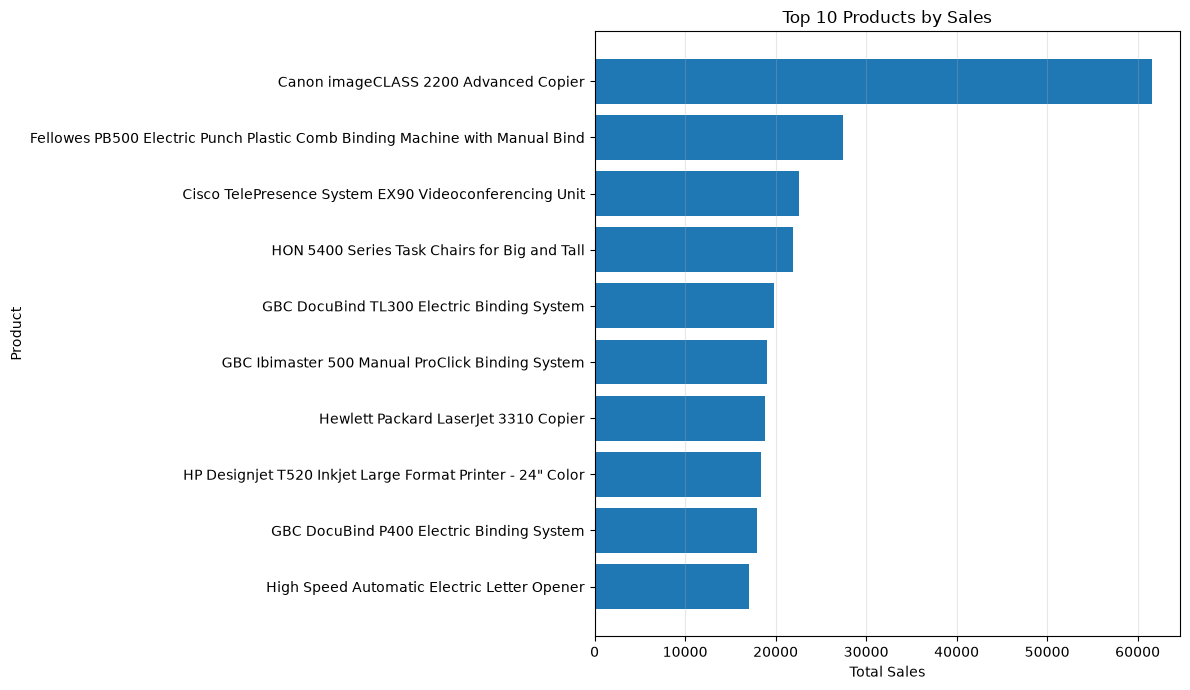

In [352]:
top_products_chart = (
    product_analysis
    .sort_values("Total_Sales", ascending=False)
    .head(10)
    .sort_values("Total_Sales", ascending=True)
)

plt.figure(figsize=(12, 7))

plt.barh(
    top_products_chart["Product Name"],
    top_products_chart["Total_Sales"]
)

plt.title("Top 10 Products by Sales")
plt.xlabel("Total Sales")
plt.ylabel("Product")
plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

In [353]:
product_analysis_path = (
    PROCESSED_DATA_DIR / "product_analysis.csv"
)

product_analysis.to_csv(
    product_analysis_path,
    index=False
)

print("Product analysis saved successfully!")
print("Saved to:", product_analysis_path)

Product analysis saved successfully!
Saved to: D:\InsightAI\data\processed\product_analysis.csv


In [354]:
saved_product_analysis = pd.read_csv(
    product_analysis_path
)

print(saved_product_analysis.head())

print("\nShape:", saved_product_analysis.shape)

print("\nColumns:")
print(saved_product_analysis.columns.tolist())

                                        Product Name  Total_Sales  \
0  "While you Were Out" Message Book, One Form pe...       25.228   
1           #10 Gummed Flap White Envelopes, 100/Box       41.300   
2                      #10 Self-Seal White Envelopes      108.682   
3         #10 White Business Envelopes,4 1/8 x 9 1/2      488.904   
4            #10- 4 1/8" x 9 1/2" Recycled Envelopes      286.672   

   Total_Profit  Total_Quantity  Total_Orders  Profit_Margin_%  
0       10.3880               8             3        41.176471  
1       16.7678              11             4        40.600000  
2       52.1230              10             4        47.959184  
3      223.1408              32             7        45.641026  
4      115.2806              37            10        40.213415  

Shape: (1849, 6)

Columns:
['Product Name', 'Total_Sales', 'Total_Profit', 'Total_Quantity', 'Total_Orders', 'Profit_Margin_%']


In [355]:
print("Regions:")
print(df["Region"].unique())

print("\nNumber of Regions:", df["Region"].nunique())

print("\nRecords by Region:")
print(df["Region"].value_counts())

Regions:
<StringArray>
['Central', 'East', 'South', 'West']
Length: 4, dtype: str

Number of Regions: 4

Records by Region:
Region
West       3253
East       2986
Central    2335
South      1620
Name: count, dtype: int64


In [356]:
regional_analysis = (
    df.groupby("Region")
      .agg(
          Total_Sales=("Sales", "sum"),
          Total_Profit=("Profit", "sum"),
          Total_Quantity=("Quantity", "sum"),
          Total_Orders=("Order ID", "nunique")
      )
      .reset_index()
)

print(regional_analysis)

    Region  Total_Sales  Total_Profit  Total_Quantity  Total_Orders
0  Central  503170.6728    39865.3070            8820          1179
1     East  691828.1680    94883.2603           11159          1475
2    South  391721.9050    46749.4303            6209           822
3     West  739813.6085   110798.8170           12466          1635


In [357]:
regional_analysis["Profit_Margin_%"] = (
    regional_analysis["Total_Profit"]
    / regional_analysis["Total_Sales"]
) * 100

print(
    regional_analysis[
        [
            "Region",
            "Total_Sales",
            "Total_Profit",
            "Total_Quantity",
            "Total_Orders",
            "Profit_Margin_%"
        ]
    ]
)

    Region  Total_Sales  Total_Profit  Total_Quantity  Total_Orders  \
0  Central  503170.6728    39865.3070            8820          1179   
1     East  691828.1680    94883.2603           11159          1475   
2    South  391721.9050    46749.4303            6209           822   
3     West  739813.6085   110798.8170           12466          1635   

   Profit_Margin_%  
0         7.922820  
1        13.714859  
2        11.934342  
3        14.976585  


In [358]:
highest_sales_region = regional_analysis.loc[
    regional_analysis["Total_Sales"].idxmax()
]

highest_profit_region = regional_analysis.loc[
    regional_analysis["Total_Profit"].idxmax()
]

highest_margin_region = regional_analysis.loc[
    regional_analysis["Profit_Margin_%"].idxmax()
]

lowest_profit_region = regional_analysis.loc[
    regional_analysis["Total_Profit"].idxmin()
]

print("========== REGIONAL PERFORMANCE ==========")

print(
    f"Highest Sales Region: "
    f"{highest_sales_region['Region']}"
)

print(
    f"Highest Profit Region: "
    f"{highest_profit_region['Region']}"
)

print(
    f"Highest Profit Margin Region: "
    f"{highest_margin_region['Region']}"
)

print(
    f"Lowest Profit Region: "
    f"{lowest_profit_region['Region']}"
)

print("==========================================")

========== REGIONAL PERFORMANCE ==========
Highest Sales Region: West
Highest Profit Region: West
Highest Profit Margin Region: West
Lowest Profit Region: Central


In [359]:
highest_sales_region = regional_analysis.loc[
    regional_analysis["Total_Sales"].idxmax()
]

highest_profit_region = regional_analysis.loc[
    regional_analysis["Total_Profit"].idxmax()
]

highest_margin_region = regional_analysis.loc[
    regional_analysis["Profit_Margin_%"].idxmax()
]

lowest_profit_region = regional_analysis.loc[
    regional_analysis["Total_Profit"].idxmin()
]

print("========== REGIONAL PERFORMANCE ==========")

print(
    f"Highest Sales Region: "
    f"{highest_sales_region['Region']}"
)

print(
    f"Highest Profit Region: "
    f"{highest_profit_region['Region']}"
)

print(
    f"Highest Profit Margin Region: "
    f"{highest_margin_region['Region']}"
)

print(
    f"Lowest Profit Region: "
    f"{lowest_profit_region['Region']}"
)

print("==========================================")

========== REGIONAL PERFORMANCE ==========
Highest Sales Region: West
Highest Profit Region: West
Highest Profit Margin Region: West
Lowest Profit Region: Central


In [360]:
regional_business_summary = pd.DataFrame({
    "Metric": [
        "Highest Sales Region",
        "Highest Profit Region",
        "Highest Profit Margin Region",
        "Lowest Profit Region"
    ],
    "Region": [
        highest_sales_region["Region"],
        highest_profit_region["Region"],
        highest_margin_region["Region"],
        lowest_profit_region["Region"]
    ]
})

print(regional_business_summary)

                         Metric   Region
0          Highest Sales Region     West
1         Highest Profit Region     West
2  Highest Profit Margin Region     West
3          Lowest Profit Region  Central


In [361]:
regional_analysis_path = (
    PROCESSED_DATA_DIR / "regional_analysis.csv"
)

regional_analysis.to_csv(
    regional_analysis_path,
    index=False
)

print("Regional analysis saved successfully!")
print("Saved to:", regional_analysis_path)

Regional analysis saved successfully!
Saved to: D:\InsightAI\data\processed\regional_analysis.csv


In [362]:
saved_regional_analysis = pd.read_csv(
    regional_analysis_path
)

print(saved_regional_analysis)

print("\nShape:", saved_regional_analysis.shape)

print("\nColumns:")
print(saved_regional_analysis.columns.tolist())

    Region  Total_Sales  Total_Profit  Total_Quantity  Total_Orders  \
0  Central  503170.6728    39865.3070            8820          1179   
1     East  691828.1680    94883.2603           11159          1475   
2    South  391721.9050    46749.4303            6209           822   
3     West  739813.6085   110798.8170           12466          1635   

   Profit_Margin_%  
0         7.922820  
1        13.714859  
2        11.934342  
3        14.976585  

Shape: (4, 6)

Columns:
['Region', 'Total_Sales', 'Total_Profit', 'Total_Quantity', 'Total_Orders', 'Profit_Margin_%']


In [363]:
total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
total_quantity = df["Quantity"].sum()
total_orders = df["Order ID"].nunique()
total_customers = df["Customer ID"].nunique()

overall_profit_margin = (
    total_profit / total_sales
) * 100

print("========== INSIGHTAI BUSINESS KPI SUMMARY ==========")

print(f"Total Sales: {total_sales:,.2f}")
print(f"Total Profit: {total_profit:,.2f}")
print(f"Total Quantity Sold: {total_quantity:,}")
print(f"Total Orders: {total_orders:,}")
print(f"Total Customers: {total_customers:,}")
print(f"Overall Profit Margin: {overall_profit_margin:.2f}%")

print("=====================================================")

========== INSIGHTAI BUSINESS KPI SUMMARY ==========
Total Sales: 2,326,534.35
Total Profit: 292,296.81
Total Quantity Sold: 38,654
Total Orders: 5,111
Total Customers: 804
Overall Profit Margin: 12.56%


In [364]:
print("========== OVERALL PROFITABILITY ==========")

print(f"Total Sales: {total_sales:,.2f}")
print(f"Total Profit: {total_profit:,.2f}")
print(f"Overall Profit Margin: {overall_profit_margin:.2f}%")

if total_profit > 0:
    print("Overall Result: Positive total profit.")
elif total_profit < 0:
    print("Overall Result: Negative total profit.")
else:
    print("Overall Result: Break-even.")

print("============================================")

========== OVERALL PROFITABILITY ==========
Total Sales: 2,326,534.35
Total Profit: 292,296.81
Overall Profit Margin: 12.56%
Overall Result: Positive total profit.


In [366]:
# Make sure Order Date is datetime
df["Order Date"] = pd.to_datetime(
    df["Order Date"],
    errors="coerce"
)

# Recreate Order Year
df["Order Year"] = df["Order Date"].dt.year

# Yearly business analysis
yearly_business_analysis = (
    df.groupby("Order Year")
      .agg(
          Total_Sales=("Sales", "sum"),
          Total_Profit=("Profit", "sum"),
          Total_Orders=("Order ID", "nunique")
      )
      .reset_index()
)

# Calculate profit margin
yearly_business_analysis["Profit_Margin_%"] = (
    yearly_business_analysis["Total_Profit"]
    / yearly_business_analysis["Total_Sales"]
) * 100

print("========== YEARLY BUSINESS PERFORMANCE ==========")
print(yearly_business_analysis)
print("==================================================")

========== YEARLY BUSINESS PERFORMANCE ==========
   Order Year  Total_Sales  Total_Profit  Total_Orders  Profit_Margin_%
0        2023  494040.2121    51684.2957           995        10.461556
1        2024  472993.0310    62020.9695          1053        13.112449
2        2025  613933.5800    82665.2018          1340        13.464844
3        2026  745567.5312    95926.3476          1723        12.866218


In [367]:
yearly_business_analysis["Sales_Growth_%"] = (
    yearly_business_analysis["Total_Sales"]
    .pct_change()
    * 100
)

yearly_business_analysis["Profit_Growth_%"] = (
    yearly_business_analysis["Total_Profit"]
    .pct_change()
    * 100
)

print("========== YEAR-OVER-YEAR PERFORMANCE ==========")

print(
    yearly_business_analysis[
        [
            "Order Year",
            "Total_Sales",
            "Sales_Growth_%",
            "Total_Profit",
            "Profit_Growth_%",
            "Profit_Margin_%"
        ]
    ]
)

print("=================================================")

========== YEAR-OVER-YEAR PERFORMANCE ==========
   Order Year  Total_Sales  Sales_Growth_%  Total_Profit  Profit_Growth_%  \
0        2023  494040.2121             NaN    51684.2957              NaN   
1        2024  472993.0310       -4.260216    62020.9695        19.999641   
2        2025  613933.5800       29.797595    82665.2018        33.285891   
3        2026  745567.5312       21.441074    95926.3476        16.041993   

   Profit_Margin_%  
0        10.461556  
1        13.112449  
2        13.464844  
3        12.866218  


In [368]:

yearly_business_analysis["Sales_Growth_%"] = (
    yearly_business_analysis["Total_Sales"]
    .pct_change()
    * 100
)

yearly_business_analysis["Profit_Growth_%"] = (
    yearly_business_analysis["Total_Profit"]
    .pct_change()
    * 100
)

print("========== YEAR-OVER-YEAR PERFORMANCE ==========")

print(
    yearly_business_analysis[
        [
            "Order Year",
            "Total_Sales",
            "Sales_Growth_%",
            "Total_Profit",
            "Profit_Growth_%",
            "Profit_Margin_%"
        ]
    ]
)

print("=================================================")

========== YEAR-OVER-YEAR PERFORMANCE ==========
   Order Year  Total_Sales  Sales_Growth_%  Total_Profit  Profit_Growth_%  \
0        2023  494040.2121             NaN    51684.2957              NaN   
1        2024  472993.0310       -4.260216    62020.9695        19.999641   
2        2025  613933.5800       29.797595    82665.2018        33.285891   
3        2026  745567.5312       21.441074    95926.3476        16.041993   

   Profit_Margin_%  
0        10.461556  
1        13.112449  
2        13.464844  
3        12.866218  


In [369]:
best_sales_year = yearly_business_analysis.loc[
    yearly_business_analysis["Total_Sales"].idxmax()
]

best_profit_year = yearly_business_analysis.loc[
    yearly_business_analysis["Total_Profit"].idxmax()
]

lowest_profit_year = yearly_business_analysis.loc[
    yearly_business_analysis["Total_Profit"].idxmin()
]

print("========== YEARLY BUSINESS INSIGHTS ==========")

print(
    f"Highest Sales Year: "
    f"{int(best_sales_year['Order Year'])}"
)

print(
    f"Sales: "
    f"{best_sales_year['Total_Sales']:,.2f}"
)

print()

print(
    f"Highest Profit Year: "
    f"{int(best_profit_year['Order Year'])}"
)

print(
    f"Profit: "
    f"{best_profit_year['Total_Profit']:,.2f}"
)

print()

print(
    f"Lowest Profit Year: "
    f"{int(lowest_profit_year['Order Year'])}"
)

print(
    f"Profit: "
    f"{lowest_profit_year['Total_Profit']:,.2f}"
)

print("===============================================")

========== YEARLY BUSINESS INSIGHTS ==========
Highest Sales Year: 2026
Sales: 745,567.53

Highest Profit Year: 2026
Profit: 95,926.35

Lowest Profit Year: 2023
Profit: 51,684.30


In [370]:
yearly_analysis_path = (
    PROCESSED_DATA_DIR / "yearly_business_analysis.csv"
)

yearly_business_analysis.to_csv(
    yearly_analysis_path,
    index=False
)

print("Yearly business analysis saved successfully!")
print("Saved to:", yearly_analysis_path)

Yearly business analysis saved successfully!
Saved to: D:\InsightAI\data\processed\yearly_business_analysis.csv


In [371]:
saved_yearly_analysis = pd.read_csv(
    yearly_analysis_path
)

print(saved_yearly_analysis)

print("\nShape:", saved_yearly_analysis.shape)

print("\nColumns:")
print(saved_yearly_analysis.columns.tolist())

   Order Year  Total_Sales  Total_Profit  Total_Orders  Profit_Margin_%  \
0        2023  494040.2121    51684.2957           995        10.461556   
1        2024  472993.0310    62020.9695          1053        13.112449   
2        2025  613933.5800    82665.2018          1340        13.464844   
3        2026  745567.5312    95926.3476          1723        12.866218   

   Sales_Growth_%  Profit_Growth_%  
0             NaN              NaN  
1       -4.260216        19.999641  
2       29.797595        33.285891  
3       21.441074        16.041993  

Shape: (4, 7)

Columns:
['Order Year', 'Total_Sales', 'Total_Profit', 'Total_Orders', 'Profit_Margin_%', 'Sales_Growth_%', 'Profit_Growth_%']


In [372]:
print("Unique Discount Values:")
print(sorted(df["Discount"].dropna().unique()))

print("\nDiscount Statistics:")
print(df["Discount"].describe())

Unique Discount Values:
[np.float64(0.0), np.float64(0.1), np.float64(0.15), np.float64(0.2), np.float64(0.3), np.float64(0.32), np.float64(0.4), np.float64(0.45), np.float64(0.5), np.float64(0.6), np.float64(0.7), np.float64(0.8)]

Discount Statistics:
count    10194.000000
mean         0.155385
std          0.206249
min          0.000000
25%          0.000000
50%          0.200000
75%          0.200000
max          0.800000
Name: Discount, dtype: float64


In [373]:
discount_analysis = (
    df.groupby("Discount")
      .agg(
          Total_Sales=("Sales", "sum"),
          Total_Profit=("Profit", "sum"),
          Total_Quantity=("Quantity", "sum"),
          Total_Orders=("Order ID", "nunique")
      )
      .reset_index()
)

discount_analysis


,Discount,Total_Sales,Total_Profit,Total_Quantity,Total_Orders
0,0.00,1.105324e+06,326718.5872,18770,2714
1,0.10,5.495250e+04,9099.9700,377,91
2,0.15,2.755852e+04,1418.9915,198,51
3,0.20,7.739394e+05,91079.9517,13856,2440
4,0.30,1.044741e+05,-10513.4456,855,214
5,0.32,1.449346e+04,-2391.1377,105,27
6,0.40,1.164978e+05,-23086.3742,789,186
7,0.45,5.484974e+03,-2493.1111,45,10
8,0.50,5.891854e+04,-20506.4281,241,64
9,0.60,7.105940e+03,-6164.3472,554,138


In [374]:
discount_analysis["Profit_Margin_%"] = (
    discount_analysis["Total_Profit"]
    / discount_analysis["Total_Sales"]
) * 100

discount_analysis

,Discount,Total_Sales,Total_Profit,Total_Quantity,Total_Orders,Profit_Margin_%
0,0.00,1.105324e+06,326718.5872,18770,2714,29.558632
1,0.10,5.495250e+04,9099.9700,377,91,16.559702
2,0.15,2.755852e+04,1418.9915,198,51,5.149012
3,0.20,7.739394e+05,91079.9517,13856,2440,11.768357
4,0.30,1.044741e+05,-10513.4456,855,214,-10.063211
5,0.32,1.449346e+04,-2391.1377,105,27,-16.498047
6,0.40,1.164978e+05,-23086.3742,789,186,-19.817012
7,0.45,5.484974e+03,-2493.1111,45,10,-45.453472
8,0.50,5.891854e+04,-20506.4281,241,64,-34.804712
9,0.60,7.105940e+03,-6164.3472,554,138,-86.749215


In [375]:
highest_profit_discount = discount_analysis.loc[
    discount_analysis["Total_Profit"].idxmax()
]

lowest_profit_discount = discount_analysis.loc[
    discount_analysis["Total_Profit"].idxmin()
]

print("Highest Profit Discount Level:")
print(highest_profit_discount)

print("\nLowest Profit Discount Level:")
print(lowest_profit_discount)

Highest Profit Discount Level:
Discount           0.000000e+00
Total_Sales        1.105324e+06
Total_Profit       3.267186e+05
Total_Quantity     1.877000e+04
Total_Orders       2.714000e+03
Profit_Margin_%    2.955863e+01
Name: 0, dtype: float64

Lowest Profit Discount Level:
Discount               0.700000
Total_Sales        40805.266000
Total_Profit      -40300.572700
Total_Quantity      1674.000000
Total_Orders         349.000000
Profit_Margin_%      -98.763166
Name: 10, dtype: float64


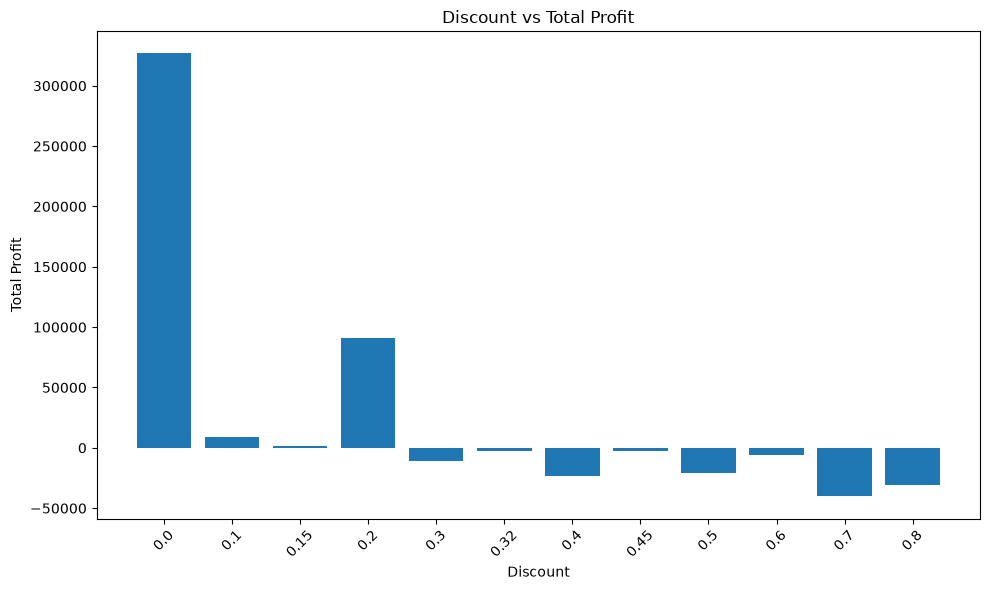

In [376]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.bar(
    discount_analysis["Discount"].astype(str),
    discount_analysis["Total_Profit"]
)

plt.xlabel("Discount")
plt.ylabel("Total Profit")
plt.title("Discount vs Total Profit")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

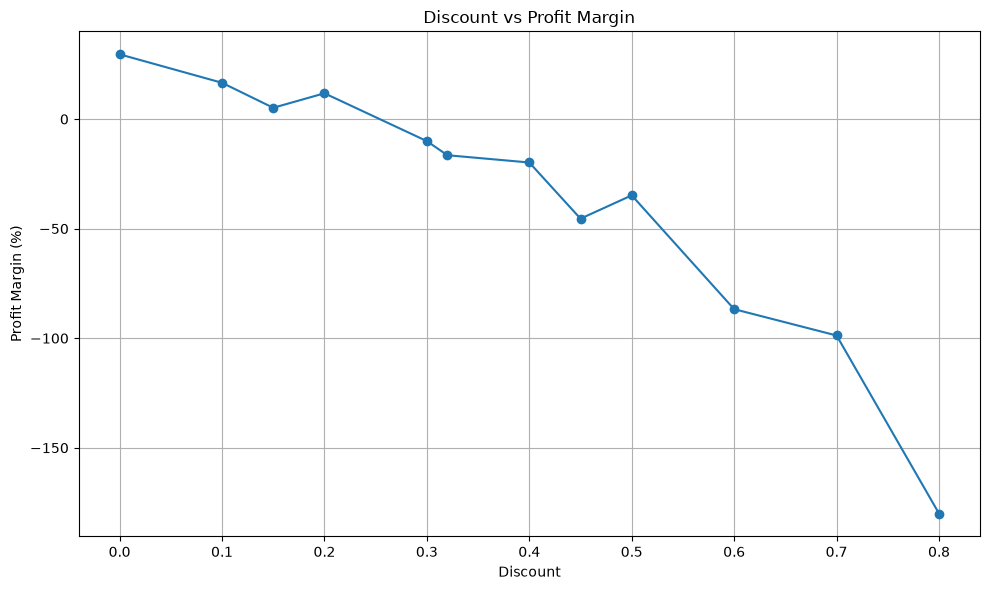

In [377]:
plt.figure(figsize=(10, 6))

plt.plot(
    discount_analysis["Discount"],
    discount_analysis["Profit_Margin_%"],
    marker="o"
)

plt.xlabel("Discount")
plt.ylabel("Profit Margin (%)")
plt.title("Discount vs Profit Margin")
plt.grid(True)
plt.tight_layout()
plt.show()

In [378]:
print("Discount Analysis Summary")
print("=" * 40)

for _, row in discount_analysis.iterrows():
    print(
        f"Discount: {row['Discount']:.0%} | "
        f"Sales: {row['Total_Sales']:,.2f} | "
        f"Profit: {row['Total_Profit']:,.2f} | "
        f"Margin: {row['Profit_Margin_%']:.2f}%"
    )

Discount Analysis Summary
Discount: 0% | Sales: 1,105,323.79 | Profit: 326,718.59 | Margin: 29.56%
Discount: 10% | Sales: 54,952.50 | Profit: 9,099.97 | Margin: 16.56%
Discount: 15% | Sales: 27,558.52 | Profit: 1,418.99 | Margin: 5.15%
Discount: 20% | Sales: 773,939.40 | Profit: 91,079.95 | Margin: 11.77%
Discount: 30% | Sales: 104,474.07 | Profit: -10,513.45 | Margin: -10.06%
Discount: 32% | Sales: 14,493.46 | Profit: -2,391.14 | Margin: -16.50%
Discount: 40% | Sales: 116,497.76 | Profit: -23,086.37 | Margin: -19.82%
Discount: 45% | Sales: 5,484.97 | Profit: -2,493.11 | Margin: -45.45%
Discount: 50% | Sales: 58,918.54 | Profit: -20,506.43 | Margin: -34.80%
Discount: 60% | Sales: 7,105.94 | Profit: -6,164.35 | Margin: -86.75%
Discount: 70% | Sales: 40,805.27 | Profit: -40,300.57 | Margin: -98.76%
Discount: 80% | Sales: 16,980.15 | Profit: -30,565.27 | Margin: -180.01%


In [379]:
discount_analysis_path = PROCESSED_DATA_DIR / "discount_analysis.csv"

discount_analysis.to_csv(
    discount_analysis_path,
    index=False
)

print(f"Saved: {discount_analysis_path}")

Saved: D:\InsightAI\data\processed\discount_analysis.csv


In [380]:
discount_analysis_path = PROCESSED_DATA_DIR / "discount_analysis.csv"

discount_analysis.to_csv(
    discount_analysis_path,
    index=False
)

print(f"Saved: {discount_analysis_path}")

Saved: D:\InsightAI\data\processed\discount_analysis.csv


In [381]:
print("Unique Ship Modes:")
print(df["Ship Mode"].unique())

print("\nShip Mode Counts:")
print(df["Ship Mode"].value_counts())

Unique Ship Modes:
<StringArray>
['Standard Class', 'First Class', 'Second Class', 'Same Day']
Length: 4, dtype: str

Ship Mode Counts:
Ship Mode
Standard Class    6120
Second Class      1979
First Class       1548
Same Day           547
Name: count, dtype: int64


In [382]:
shipping_analysis = (
    df.groupby("Ship Mode")
      .agg(
          Total_Sales=("Sales", "sum"),
          Total_Profit=("Profit", "sum"),
          Total_Quantity=("Quantity", "sum"),
          Total_Orders=("Order ID", "nunique")
      )
      .reset_index()
)

shipping_analysis

,Ship Mode,Total_Sales,Total_Profit,Total_Quantity,Total_Orders
0,First Class,3.517507e+05,49012.7242,5724,795
1,Same Day,1.292720e+05,16160.7480,1975,266
2,Second Class,4.666711e+05,58962.1329,7546,982
3,Standard Class,1.378841e+06,168161.2095,23409,3068


In [383]:
shipping_analysis["Profit_Margin_%"] = (
    shipping_analysis["Total_Profit"]
    / shipping_analysis["Total_Sales"]
) * 100

shipping_analysis

,Ship Mode,Total_Sales,Total_Profit,Total_Quantity,Total_Orders,Profit_Margin_%
0,First Class,3.517507e+05,49012.7242,5724,795,13.933936
1,Same Day,1.292720e+05,16160.7480,1975,266,12.501357
2,Second Class,4.666711e+05,58962.1329,7546,982,12.634622
3,Standard Class,1.378841e+06,168161.2095,23409,3068,12.195842


In [384]:
highest_sales_ship = shipping_analysis.loc[
    shipping_analysis["Total_Sales"].idxmax()
]

highest_profit_ship = shipping_analysis.loc[
    shipping_analysis["Total_Profit"].idxmax()
]

highest_margin_ship = shipping_analysis.loc[
    shipping_analysis["Profit_Margin_%"].idxmax()
]

print("Highest Sales Ship Mode:")
print(highest_sales_ship)

print("\nHighest Profit Ship Mode:")
print(highest_profit_ship)

print("\nHighest Profit Margin Ship Mode:")
print(highest_margin_ship)

Highest Sales Ship Mode:
Ship Mode          Standard Class
Total_Sales           1378840.551
Total_Profit          168161.2095
Total_Quantity              23409
Total_Orders                 3068
Profit_Margin_%         12.195842
Name: 3, dtype: object

Highest Profit Ship Mode:
Ship Mode          Standard Class
Total_Sales           1378840.551
Total_Profit          168161.2095
Total_Quantity              23409
Total_Orders                 3068
Profit_Margin_%         12.195842
Name: 3, dtype: object

Highest Profit Margin Ship Mode:
Ship Mode          First Class
Total_Sales        351750.7369
Total_Profit        49012.7242
Total_Quantity            5724
Total_Orders               795
Profit_Margin_%      13.933936
Name: 0, dtype: object


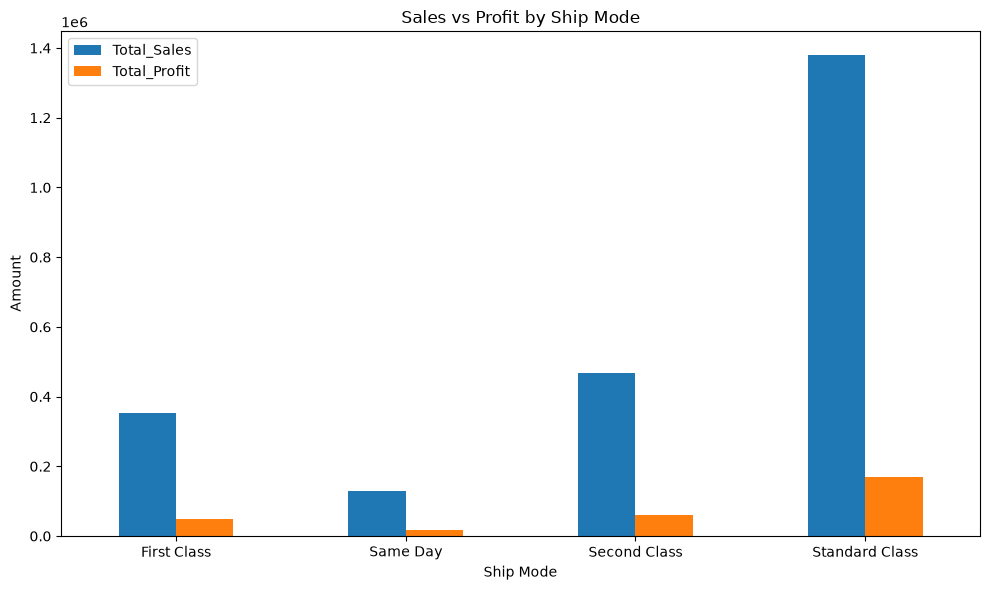

In [385]:
import matplotlib.pyplot as plt

shipping_analysis.plot(
    x="Ship Mode",
    y=["Total_Sales", "Total_Profit"],
    kind="bar",
    figsize=(10, 6)
)

plt.title("Sales vs Profit by Ship Mode")
plt.xlabel("Ship Mode")
plt.ylabel("Amount")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [386]:
shipping_analysis_path = PROCESSED_DATA_DIR / "shipping_analysis.csv"

shipping_analysis.to_csv(
    shipping_analysis_path,
    index=False
)

print(f"Saved: {shipping_analysis_path}")

Saved: D:\InsightAI\data\processed\shipping_analysis.csv


In [387]:
shipping_check = pd.read_csv(shipping_analysis_path)

print("Shipping analysis verified!")
print("Rows:", len(shipping_check))
print("Columns:", len(shipping_check.columns))

shipping_check

Shipping analysis verified!
Rows: 4
Columns: 6


,Ship Mode,Total_Sales,Total_Profit,Total_Quantity,Total_Orders,Profit_Margin_%
0,First Class,3.517507e+05,49012.7242,5724,795,13.933936
1,Same Day,1.292720e+05,16160.7480,1975,266,12.501357
2,Second Class,4.666711e+05,58962.1329,7546,982,12.634622
3,Standard Class,1.378841e+06,168161.2095,23409,3068,12.195842


In [390]:
print("Number of States:", df["State/Province"].nunique())

print("\nUnique States:")
print(df["State/Province"].unique())

Number of States: 59

Unique States:
<StringArray>
[                    'Texas',                  'Illinois',
              'Pennsylvania',                  'Kentucky',
                   'Georgia',                'California',
                  'Virginia',                  'Delaware',
            'South Carolina',                      'Ohio',
                 'Louisiana',                    'Oregon',
                   'Arizona',                  'Arkansas',
                  'Michigan',                 'Tennessee',
                   'Florida',                   'Ontario',
                   'Indiana',                    'Nevada',
              'South Dakota',                  'New York',
                 'Wisconsin',                'Washington',
                'New Jersey',                  'Missouri',
            'North Carolina',                  'Colorado',
                   'Alberta',                      'Utah',
                 'Minnesota',               'Mississippi',
     

In [389]:
print("Available columns:")
print(df.columns.tolist())

Available columns:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country/Region', 'City', 'State/Province', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit', 'Discount Band', 'Order Year']


In [391]:
state_analysis = (
    df.groupby("State/Province")
      .agg(
          Total_Sales=("Sales", "sum"),
          Total_Profit=("Profit", "sum"),
          Total_Quantity=("Quantity", "sum"),
          Total_Orders=("Order ID", "nunique")
      )
      .reset_index()
)

state_analysis.head(10)

,State/Province,Total_Sales,Total_Profit,Total_Quantity,Total_Orders
0,Alabama,19510.6400,5786.8253,256,34
1,Alberta,11460.1860,2236.1578,110,8
2,Arizona,35282.0010,-3427.9246,862,108
3,Arkansas,11678.1300,4008.6871,240,27
4,British Columbia,2763.2000,115.6703,81,14
5,California,457687.6315,76381.3871,7667,1021
6,Colorado,32108.1180,-6527.8579,693,79
7,Connecticut,13384.3570,3511.4918,281,45
8,Delaware,27451.0690,9977.3748,367,44
9,District of Columbia,2865.0200,1059.5893,40,4


In [392]:
state_analysis["Profit_Margin_%"] = (
    state_analysis["Total_Profit"]
    / state_analysis["Total_Sales"]
) * 100

state_analysis.head(10)

,State/Province,Total_Sales,Total_Profit,Total_Quantity,Total_Orders,Profit_Margin_%
0,Alabama,19510.6400,5786.8253,256,34,29.659844
1,Alberta,11460.1860,2236.1578,110,8,19.512404
2,Arizona,35282.0010,-3427.9246,862,108,-9.715789
3,Arkansas,11678.1300,4008.6871,240,27,34.326447
4,British Columbia,2763.2000,115.6703,81,14,4.186099
5,California,457687.6315,76381.3871,7667,1021,16.688541
6,Colorado,32108.1180,-6527.8579,693,79,-20.330864
7,Connecticut,13384.3570,3511.4918,281,45,26.235790
8,Delaware,27451.0690,9977.3748,367,44,36.346034
9,District of Columbia,2865.0200,1059.5893,40,4,36.983662


In [393]:
top_10_sales_states = (
    state_analysis
    .sort_values("Total_Sales", ascending=False)
    .head(10)
)

top_10_sales_states

,State/Province,Total_Sales,Total_Profit,Total_Quantity,Total_Orders,Profit_Margin_%
5,California,457687.6315,76381.3871,7667,1021,16.688541
34,New York,310876.2710,74038.5486,4224,562,23.816082
51,Texas,170188.0458,-25729.3563,3724,487,-15.118192
55,Washington,138641.2700,33402.6517,1883,256,24.092863
43,Pennsylvania,116511.9140,-15559.9603,2153,288,-13.354823
10,Florida,89473.7080,-3399.3017,1379,200,-3.799219
13,Illinois,80166.1010,-12607.8870,1845,276,-15.727205
39,Ohio,78258.1360,-16971.3766,1759,236,-21.686405
23,Michigan,76269.6140,24463.1876,946,117,32.074618
54,Virginia,70636.7200,18597.9504,893,115,26.329012


In [394]:
top_10_sales_states = (
    state_analysis
    .sort_values("Total_Sales", ascending=False)
    .head(10)
)

top_10_sales_states

,State/Province,Total_Sales,Total_Profit,Total_Quantity,Total_Orders,Profit_Margin_%
5,California,457687.6315,76381.3871,7667,1021,16.688541
34,New York,310876.2710,74038.5486,4224,562,23.816082
51,Texas,170188.0458,-25729.3563,3724,487,-15.118192
55,Washington,138641.2700,33402.6517,1883,256,24.092863
43,Pennsylvania,116511.9140,-15559.9603,2153,288,-13.354823
10,Florida,89473.7080,-3399.3017,1379,200,-3.799219
13,Illinois,80166.1010,-12607.8870,1845,276,-15.727205
39,Ohio,78258.1360,-16971.3766,1759,236,-21.686405
23,Michigan,76269.6140,24463.1876,946,117,32.074618
54,Virginia,70636.7200,18597.9504,893,115,26.329012


In [395]:
top_10_profit_states = (
    state_analysis
    .sort_values("Total_Profit", ascending=False)
    .head(10)
)

top_10_profit_states

,State/Province,Total_Sales,Total_Profit,Total_Quantity,Total_Orders,Profit_Margin_%
5,California,457687.6315,76381.3871,7667,1021,16.688541
34,New York,310876.2710,74038.5486,4224,562,23.816082
55,Washington,138641.2700,33402.6517,1883,256,24.092863
23,Michigan,76269.6140,24463.1876,946,117,32.074618
54,Virginia,70636.7200,18597.9504,893,115,26.329012
14,Indiana,53555.3600,18382.9363,578,73,34.325110
11,Georgia,49095.8400,16250.0433,705,91,33.098615
17,Kentucky,36591.7500,11199.6966,523,61,30.607163
24,Minnesota,29863.1500,10823.1874,331,44,36.242618
8,Delaware,27451.0690,9977.3748,367,44,36.346034


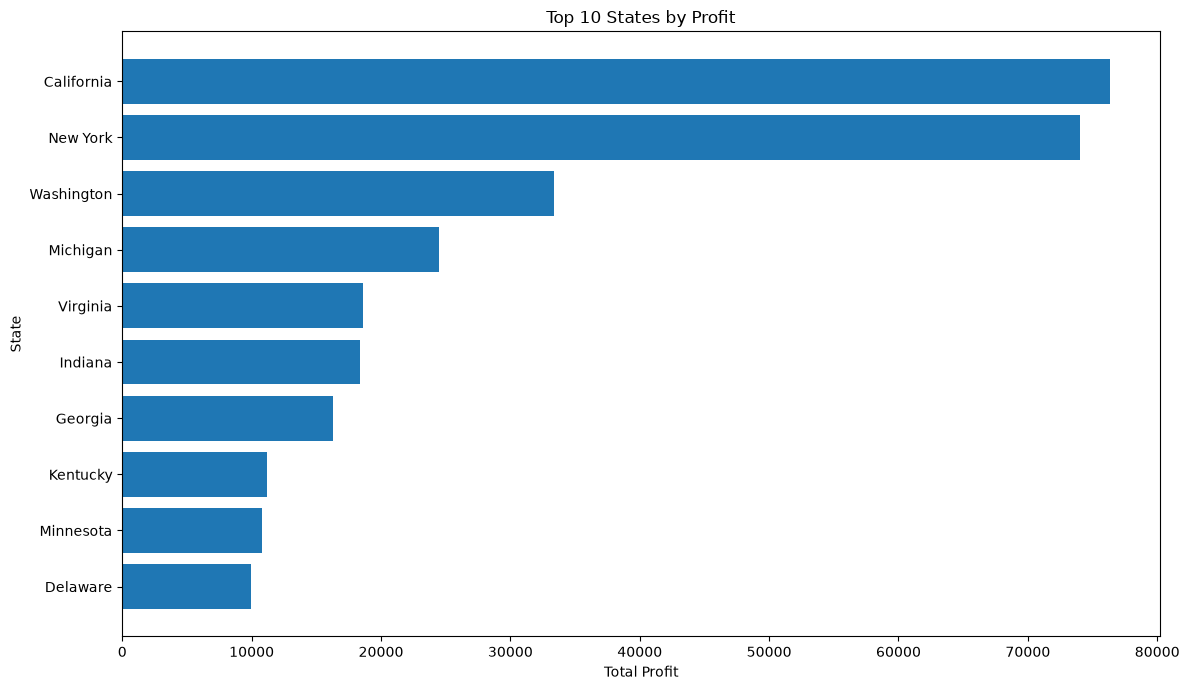

In [396]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 7))

plt.barh(
    top_10_profit_states["State/Province"],
    top_10_profit_states["Total_Profit"]
)

plt.xlabel("Total Profit")
plt.ylabel("State")
plt.title("Top 10 States by Profit")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [397]:
state_analysis_path = PROCESSED_DATA_DIR / "state_analysis.csv"

state_analysis.to_csv(
    state_analysis_path,
    index=False
)

print(f"Saved: {state_analysis_path}")

Saved: D:\InsightAI\data\processed\state_analysis.csv


In [398]:
state_check = pd.read_csv(state_analysis_path)

print("State analysis verified!")
print("Rows:", len(state_check))
print("Columns:", len(state_check.columns))

state_check.head()

State analysis verified!
Rows: 59
Columns: 6


,State/Province,Total_Sales,Total_Profit,Total_Quantity,Total_Orders,Profit_Margin_%
0,Alabama,19510.640,5786.8253,256,34,29.659844
1,Alberta,11460.186,2236.1578,110,8,19.512404
2,Arizona,35282.001,-3427.9246,862,108,-9.715789
3,Arkansas,11678.130,4008.6871,240,27,34.326447
4,British Columbia,2763.200,115.6703,81,14,4.186099


In [399]:
print("FINAL BUSINESS KPI SUMMARY")
print("=" * 45)

print(f"Total Sales:      {total_sales:,.2f}")
print(f"Total Profit:     {total_profit:,.2f}")
print(f"Total Quantity:   {total_quantity:,}")
print(f"Total Orders:     {total_orders:,}")
print(f"Total Customers:  {total_customers:,}")
print(f"Profit Margin:    {overall_profit_margin:.2f}%")

FINAL BUSINESS KPI SUMMARY
Total Sales:      2,326,534.35
Total Profit:     292,296.81
Total Quantity:   38,654
Total Orders:     5,111
Total Customers:  804
Profit Margin:    12.56%


In [400]:
best_segment = segment_analysis.loc[
    segment_analysis["Total_Profit"].idxmax()
]

print("Best Performing Segment:")
print(best_segment)

Best Performing Segment:
Segment               Consumer
Total_Sales        1170659.787
Total_Profit       136371.4463
Total_Quantity           19844
Total_Orders              2628
Profit_Margin_%       11.64911
Name: 0, dtype: object


In [401]:
best_segment = segment_analysis.loc[
    segment_analysis["Total_Profit"].idxmax()
]

print("Best Performing Segment:")
print(best_segment)

Best Performing Segment:
Segment               Consumer
Total_Sales        1170659.787
Total_Profit       136371.4463
Total_Quantity           19844
Total_Orders              2628
Profit_Margin_%       11.64911
Name: 0, dtype: object


In [402]:
best_region = regional_analysis.loc[
    regional_analysis["Total_Profit"].idxmax()
]

print("Best Performing Region:")
print(best_region)

Best Performing Region:
Region                    West
Total_Sales        739813.6085
Total_Profit        110798.817
Total_Quantity           12466
Total_Orders              1635
Profit_Margin_%      14.976585
Name: 3, dtype: object


In [403]:
best_product = product_analysis.loc[
    product_analysis["Total_Profit"].idxmax()
]

print("Best Performing Product:")
print(best_product)

Best Performing Product:
Product Name       Canon imageCLASS 2200 Advanced Copier
Total_Sales                                    61599.824
Total_Profit                                   25199.928
Total_Quantity                                        20
Total_Orders                                           5
Profit_Margin_%                                40.909091
Name: 404, dtype: object


In [404]:
best_product = product_analysis.loc[
    product_analysis["Total_Profit"].idxmax()
]

print("Best Performing Product:")
print(best_product)

Best Performing Product:
Product Name       Canon imageCLASS 2200 Advanced Copier
Total_Sales                                    61599.824
Total_Profit                                   25199.928
Total_Quantity                                        20
Total_Orders                                           5
Profit_Margin_%                                40.909091
Name: 404, dtype: object


In [406]:
# 10.23.7 — Final Business Summary

best_category = category_analysis.loc[
    category_analysis["Total_Profit"].idxmax()
]

best_region = regional_analysis.loc[
    regional_analysis["Total_Profit"].idxmax()
]

best_product = product_analysis.loc[
    product_analysis["Total_Profit"].idxmax()
]

best_state = state_analysis.loc[
    state_analysis["Total_Profit"].idxmax()
]

print("FINAL BUSINESS ANALYSIS")
print("=" * 50)

print(f"Overall Profit Margin: {overall_profit_margin:.2f}%")
print(f"Best Segment: {best_segment['Segment']}")
print(f"Best Category: {best_category['Category']}")
print(f"Best Region: {best_region['Region']}")
print(f"Best Product: {best_product['Product Name']}")
print(f"Best State: {best_state['State/Province']}")

FINAL BUSINESS ANALYSIS
Overall Profit Margin: 12.56%
Best Segment: Consumer
Best Category: Technology
Best Region: West
Best Product: Canon imageCLASS 2200 Advanced Copier
Best State: California


In [407]:
final_business_insights = {
    "Total Sales": total_sales,
    "Total Profit": total_profit,
    "Total Quantity": total_quantity,
    "Total Orders": total_orders,
    "Total Customers": total_customers,
    "Overall Profit Margin (%)": overall_profit_margin,
    "Best Segment": best_segment["Segment"],
    "Best Category": best_category["Category"],
    "Best Region": best_region["Region"],
    "Best Product": best_product["Product Name"],
    "Best State": best_state["State/Province"]
}

final_business_insights

{'Total Sales': np.float64(2326534.3543),
 'Total Profit': np.float64(292296.8145999999),
 'Total Quantity': np.int64(38654),
 'Total Orders': 5111,
 'Total Customers': 804,
 'Overall Profit Margin (%)': np.float64(12.563614805849074),
 'Best Segment': 'Consumer',
 'Best Category': 'Technology',
 'Best Region': 'West',
 'Best Product': 'Canon imageCLASS 2200 Advanced Copier',
 'Best State': 'California'}

In [408]:
final_insights_path = PROCESSED_DATA_DIR / "final_business_insights.csv"

pd.DataFrame(
    [final_business_insights]
).to_csv(
    final_insights_path,
    index=False
)

print(f"Saved: {final_insights_path}")

Saved: D:\InsightAI\data\processed\final_business_insights.csv


In [409]:
final_check = pd.read_csv(final_insights_path)

print("Final business insights verified!")
print("Rows:", len(final_check))
print("Columns:", len(final_check.columns))

final_check

Final business insights verified!
Rows: 1
Columns: 11


,Total Sales,Total Profit,Total Quantity,Total Orders,Total Customers,Overall Profit Margin (%),Best Segment,Best Category,Best Region,Best Product,Best State
0,2.326534e+06,292296.8146,38654,5111,804,12.563615,Consumer,Technology,West,Canon imageCLASS 2200 Advanced Copier,California


In [410]:
print("FINAL DATASET QUALITY CHECK")
print("=" * 45)

print(f"Rows: {len(df):,}")
print(f"Columns: {len(df.columns)}")

print("\nMissing Values:")
print(df.isna().sum().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nDate Range:")
print(df["Order Date"].min(), "to", df["Order Date"].max())

FINAL DATASET QUALITY CHECK
Rows: 10,194
Columns: 23

Missing Values:
9983

Duplicate Rows:
0

Date Range:
2023-01-03 00:00:00 to 2026-12-30 00:00:00


In [411]:
final_dataset_path = PROCESSED_DATA_DIR / "Superstore_final_analysis.csv"

df.to_csv(
    final_dataset_path,
    index=False
)

print(f"Final dataset saved successfully:")
print(final_dataset_path)

Final dataset saved successfully:
D:\InsightAI\data\processed\Superstore_final_analysis.csv


In [412]:
final_dataset_check = pd.read_csv(final_dataset_path)

print("FINAL DATASET VERIFIED")
print("=" * 45)
print("Rows:", len(final_dataset_check))
print("Columns:", len(final_dataset_check.columns))

print("\nFirst 5 rows:")
display(final_dataset_check.head())

FINAL DATASET VERIFIED
Rows: 10194
Columns: 23

First 5 rows:


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,...,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Discount Band,Order Year
0,1,US-2023-103800,2023-01-03,2023-01-07,Standard Class,DP-13000,Darren Powers,Consumer,United States,Houston,...,OFF-PA-10000174,Office Supplies,Paper,"Message Book, Wirebound, Four 5 1/2"" X 4"" Form...",16.448,2,0.2,5.5512,11-20%,2023
1,2,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,OFF-BI-10004094,Office Supplies,Binders,GBC Standard Plastic Binding Systems Combs,3.540,2,0.8,-5.4870,51%+,2023
2,3,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,OFF-LA-10003223,Office Supplies,Labels,Avery 508,11.784,3,0.2,4.2717,11-20%,2023
3,4,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,OFF-ST-10002743,Office Supplies,Storage,SAFCO Boltless Steel Shelving,272.736,3,0.2,-64.7748,11-20%,2023
4,5,US-2023-141817,2023-01-05,2023-01-12,Standard Class,MB-18085,Mick Brown,Consumer,United States,Philadelphia,...,OFF-AR-10003478,Office Supplies,Art,Avery Hi-Liter EverBold Pen Style Fluorescent ...,19.536,3,0.2,4.8840,11-20%,2023


In [413]:
print("INSIGHTAI — PROCESSED OUTPUTS")
print("=" * 50)

for file in sorted(PROCESSED_DATA_DIR.iterdir()):
    print(file.name)

INSIGHTAI — PROCESSED OUTPUTS
category_analysis.csv
discount_analysis.csv
final_business_insights.csv
forecast_analysis.csv
forecast_business_insights.csv
forecast_conclusion.txt
forecast_metrics.csv
product_analysis.csv
regional_analysis.csv
sales_forecast.csv
segment_analysis.csv
shipping_analysis.csv
state_analysis.csv
subcategory_analysis.csv
Superstore_cleaned.csv
Superstore_final_analysis.csv
yearly_business_analysis.csv


In [414]:
expected_outputs = [
    "Superstore_cleaned.csv",
    "Superstore_final_analysis.csv",
    "sales_forecast.csv",
    "forecast_metrics.csv",
    "forecast_analysis.csv",
    "forecast_business_insights.csv",
    "forecast_conclusion.txt",
    "segment_analysis.csv",
    "category_analysis.csv",
    "subcategory_analysis.csv",
    "product_analysis.csv",
    "regional_analysis.csv",
    "yearly_business_analysis.csv",
    "discount_analysis.csv",
    "shipping_analysis.csv",
    "state_analysis.csv",
    "final_business_insights.csv"
]

print("INSIGHTAI OUTPUT STATUS")
print("=" * 50)

for filename in expected_outputs:
    file_path = PROCESSED_DATA_DIR / filename
    
    status = "✅ Found" if file_path.exists() else "❌ Missing"
    print(f"{status}: {filename}")

INSIGHTAI OUTPUT STATUS
✅ Found: Superstore_cleaned.csv
✅ Found: Superstore_final_analysis.csv
✅ Found: sales_forecast.csv
✅ Found: forecast_metrics.csv
✅ Found: forecast_analysis.csv
✅ Found: forecast_business_insights.csv
✅ Found: forecast_conclusion.txt
✅ Found: segment_analysis.csv
✅ Found: category_analysis.csv
✅ Found: subcategory_analysis.csv
✅ Found: product_analysis.csv
✅ Found: regional_analysis.csv
✅ Found: yearly_business_analysis.csv
✅ Found: discount_analysis.csv
✅ Found: shipping_analysis.csv
✅ Found: state_analysis.csv
✅ Found: final_business_insights.csv


In [415]:
from pathlib import Path

POWERBI_DATA_DIR = PROCESSED_DATA_DIR / "PowerBI"

POWERBI_DATA_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("Power BI folder ready:")
print(POWERBI_DATA_DIR)

Power BI folder ready:
D:\InsightAI\data\processed\PowerBI


In [416]:
powerbi_main_path = POWERBI_DATA_DIR / "PowerBI_Main_Dataset.csv"

df.to_csv(
    powerbi_main_path,
    index=False
)

print("Power BI main dataset created:")
print(powerbi_main_path)
print("Rows:", len(df))
print("Columns:", len(df.columns))

Power BI main dataset created:
D:\InsightAI\data\processed\PowerBI\PowerBI_Main_Dataset.csv
Rows: 10194
Columns: 23


In [417]:
powerbi_kpi = pd.DataFrame({
    "KPI": [
        "Total Sales",
        "Total Profit",
        "Total Quantity",
        "Total Orders",
        "Total Customers",
        "Profit Margin (%)"
    ],
    "Value": [
        total_sales,
        total_profit,
        total_quantity,
        total_orders,
        total_customers,
        overall_profit_margin
    ]
})

kpi_path = POWERBI_DATA_DIR / "PowerBI_KPI_Summary.csv"

powerbi_kpi.to_csv(
    kpi_path,
    index=False
)

print("KPI Summary created:")
print(kpi_path)

display(powerbi_kpi)

KPI Summary created:
D:\InsightAI\data\processed\PowerBI\PowerBI_KPI_Summary.csv


,KPI,Value
0,Total Sales,2.326534e+06
1,Total Profit,2.922968e+05
2,Total Quantity,3.865400e+04
3,Total Orders,5.111000e+03
4,Total Customers,8.040000e+02
5,Profit Margin (%),1.256361e+01


In [418]:
powerbi_yearly = yearly_business_analysis[
    [
        "Order Year",
        "Total_Sales",
        "Total_Profit",
        "Total_Orders",
        "Profit_Margin_%",
        "Sales_Growth_%",
        "Profit_Growth_%"
    ]
].copy()

yearly_path = POWERBI_DATA_DIR / "PowerBI_Yearly_Analysis.csv"

powerbi_yearly.to_csv(
    yearly_path,
    index=False
)

print("Yearly Power BI table created:")
print(yearly_path)

display(powerbi_yearly)

Yearly Power BI table created:
D:\InsightAI\data\processed\PowerBI\PowerBI_Yearly_Analysis.csv


,Order Year,Total_Sales,Total_Profit,Total_Orders,Profit_Margin_%,Sales_Growth_%,Profit_Growth_%
0,2023,494040.2121,51684.2957,995,10.461556,NaN,NaN
1,2024,472993.0310,62020.9695,1053,13.112449,-4.260216,19.999641
2,2025,613933.5800,82665.2018,1340,13.464844,29.797595,33.285891
3,2026,745567.5312,95926.3476,1723,12.866218,21.441074,16.041993


In [419]:
powerbi_segment = segment_analysis[
    [
        "Segment",
        "Total_Sales",
        "Total_Profit",
        "Total_Quantity",
        "Total_Orders",
        "Profit_Margin_%"
    ]
].copy()

segment_path = POWERBI_DATA_DIR / "PowerBI_Segment_Analysis.csv"

powerbi_segment.to_csv(
    segment_path,
    index=False
)

print("Segment Power BI table created:")
print(segment_path)

display(powerbi_segment)

Segment Power BI table created:
D:\InsightAI\data\processed\PowerBI\PowerBI_Segment_Analysis.csv


,Segment,Total_Sales,Total_Profit,Total_Quantity,Total_Orders,Profit_Margin_%
0,Consumer,1.170660e+06,136371.4463,19844,2628,11.649110
1,Corporate,7.158061e+05,94249.6400,11898,1552,13.166923
2,Home Office,4.400684e+05,61675.7283,6912,931,14.015031


In [420]:
powerbi_category = category_analysis[
    [
        "Category",
        "Total_Sales",
        "Total_Profit",
        "Total_Quantity",
        "Total_Orders",
        "Profit_Margin_%"
    ]
].copy()

category_path = POWERBI_DATA_DIR / "PowerBI_Category_Analysis.csv"

powerbi_category.to_csv(
    category_path,
    index=False
)

print("Category Power BI table created:")
print(category_path)

display(powerbi_category)

Category Power BI table created:
D:\InsightAI\data\processed\PowerBI\PowerBI_Category_Analysis.csv


,Category,Total_Sales,Total_Profit,Total_Quantity,Total_Orders,Profit_Margin_%
0,Furniture,754747.7613,19729.9956,8369,1819,2.614118
1,Office Supplies,731893.3140,126023.4434,23268,3812,17.218827
2,Technology,839893.2790,146543.3756,7017,1560,17.447857


In [421]:
powerbi_subcategory = subcategory_analysis[
    [
        "Sub-Category",
        "Total_Sales",
        "Total_Profit",
        "Total_Quantity",
        "Total_Orders",
        "Profit_Margin_%"
    ]
].copy()

subcategory_path = POWERBI_DATA_DIR / "PowerBI_SubCategory_Analysis.csv"

powerbi_subcategory.to_csv(
    subcategory_path,
    index=False
)

print("Sub-Category Power BI table created:")
print(subcategory_path)

display(powerbi_subcategory)

Sub-Category Power BI table created:
D:\InsightAI\data\processed\PowerBI\PowerBI_SubCategory_Analysis.csv


,Sub-Category,Total_Sales,Total_Profit,Total_Quantity,Total_Orders,Profit_Margin_%
0,Accessories,167380.3180,41936.6357,2976,718,25.054700
1,Appliances,108213.1850,18329.4844,1750,459,16.938310
2,Art,27659.0140,6653.1962,3092,756,24.054351
3,Binders,207354.8810,31426.1003,6071,1339,15.155708
4,Bookcases,115361.2043,-3632.0736,878,228,-3.148436
5,Chairs,335768.2490,27223.5323,2431,591,8.107834
6,Copiers,150745.2900,56093.9365,242,70,37.211071
7,Envelopes,16528.3620,6988.0247,914,251,42.278991
8,Fasteners,8532.2400,2428.6358,980,226,28.464223
9,Furnishings,95598.1260,13891.7430,3799,919,14.531397


In [422]:
powerbi_regional = regional_analysis[
    [
        "Region",
        "Total_Sales",
        "Total_Profit",
        "Total_Quantity",
        "Total_Orders",
        "Profit_Margin_%"
    ]
].copy()

regional_path = POWERBI_DATA_DIR / "PowerBI_Regional_Analysis.csv"

powerbi_regional.to_csv(
    regional_path,
    index=False
)

print("Regional Power BI table created:")
print(regional_path)

display(powerbi_regional)

Regional Power BI table created:
D:\InsightAI\data\processed\PowerBI\PowerBI_Regional_Analysis.csv


,Region,Total_Sales,Total_Profit,Total_Quantity,Total_Orders,Profit_Margin_%
0,Central,503170.6728,39865.3070,8820,1179,7.922820
1,East,691828.1680,94883.2603,11159,1475,13.714859
2,South,391721.9050,46749.4303,6209,822,11.934342
3,West,739813.6085,110798.8170,12466,1635,14.976585


In [423]:
powerbi_discount = discount_analysis[
    [
        "Discount",
        "Total_Sales",
        "Total_Profit",
        "Total_Quantity",
        "Total_Orders",
        "Profit_Margin_%"
    ]
].copy()

discount_path = POWERBI_DATA_DIR / "PowerBI_Discount_Analysis.csv"

powerbi_discount.to_csv(
    discount_path,
    index=False
)

print("Discount Power BI table created:")
print(discount_path)

display(powerbi_discount)

Discount Power BI table created:
D:\InsightAI\data\processed\PowerBI\PowerBI_Discount_Analysis.csv


,Discount,Total_Sales,Total_Profit,Total_Quantity,Total_Orders,Profit_Margin_%
0,0.00,1.105324e+06,326718.5872,18770,2714,29.558632
1,0.10,5.495250e+04,9099.9700,377,91,16.559702
2,0.15,2.755852e+04,1418.9915,198,51,5.149012
3,0.20,7.739394e+05,91079.9517,13856,2440,11.768357
4,0.30,1.044741e+05,-10513.4456,855,214,-10.063211
5,0.32,1.449346e+04,-2391.1377,105,27,-16.498047
6,0.40,1.164978e+05,-23086.3742,789,186,-19.817012
7,0.45,5.484974e+03,-2493.1111,45,10,-45.453472
8,0.50,5.891854e+04,-20506.4281,241,64,-34.804712
9,0.60,7.105940e+03,-6164.3472,554,138,-86.749215


In [424]:
powerbi_shipping = shipping_analysis[
    [
        "Ship Mode",
        "Total_Sales",
        "Total_Profit",
        "Total_Quantity",
        "Total_Orders",
        "Profit_Margin_%"
    ]
].copy()

shipping_path = POWERBI_DATA_DIR / "PowerBI_Shipping_Analysis.csv"

shipping_path.parent.mkdir(
    parents=True,
    exist_ok=True
)

powerbi_shipping.to_csv(
    shipping_path,
    index=False
)

print("Shipping Power BI table created:")
print(shipping_path)

display(powerbi_shipping)

Shipping Power BI table created:
D:\InsightAI\data\processed\PowerBI\PowerBI_Shipping_Analysis.csv


,Ship Mode,Total_Sales,Total_Profit,Total_Quantity,Total_Orders,Profit_Margin_%
0,First Class,3.517507e+05,49012.7242,5724,795,13.933936
1,Same Day,1.292720e+05,16160.7480,1975,266,12.501357
2,Second Class,4.666711e+05,58962.1329,7546,982,12.634622
3,Standard Class,1.378841e+06,168161.2095,23409,3068,12.195842


In [425]:
powerbi_state = state_analysis[
    [
        "State/Province",
        "Total_Sales",
        "Total_Profit",
        "Total_Quantity",
        "Total_Orders",
        "Profit_Margin_%"
    ]
].copy()

state_path = POWERBI_DATA_DIR / "PowerBI_State_Analysis.csv"

state_path.parent.mkdir(
    parents=True,
    exist_ok=True
)

powerbi_state.to_csv(
    state_path,
    index=False
)

print("State Power BI table created:")
print(state_path)

display(powerbi_state)

State Power BI table created:
D:\InsightAI\data\processed\PowerBI\PowerBI_State_Analysis.csv


,State/Province,Total_Sales,Total_Profit,Total_Quantity,Total_Orders,Profit_Margin_%
0,Alabama,19510.6400,5786.8253,256,34,29.659844
1,Alberta,11460.1860,2236.1578,110,8,19.512404
2,Arizona,35282.0010,-3427.9246,862,108,-9.715789
3,Arkansas,11678.1300,4008.6871,240,27,34.326447
4,British Columbia,2763.2000,115.6703,81,14,4.186099
5,California,457687.6315,76381.3871,7667,1021,16.688541
6,Colorado,32108.1180,-6527.8579,693,79,-20.330864
7,Connecticut,13384.3570,3511.4918,281,45,26.235790
8,Delaware,27451.0690,9977.3748,367,44,36.346034
9,District of Columbia,2865.0200,1059.5893,40,4,36.983662


In [426]:
powerbi_product = product_analysis[
    [
        "Product Name",
        "Total_Sales",
        "Total_Profit",
        "Total_Quantity",
        "Total_Orders",
        "Profit_Margin_%"
    ]
].copy()

product_path = POWERBI_DATA_DIR / "PowerBI_Product_Analysis.csv"

product_path.parent.mkdir(
    parents=True,
    exist_ok=True
)

powerbi_product.to_csv(
    product_path,
    index=False
)

print("Product Power BI table created:")
print(product_path)

display(powerbi_product.head(10))

Product Power BI table created:
D:\InsightAI\data\processed\PowerBI\PowerBI_Product_Analysis.csv


,Product Name,Total_Sales,Total_Profit,Total_Quantity,Total_Orders,Profit_Margin_%
0,"""While you Were Out"" Message Book, One Form pe...",25.228,10.3880,8,3,41.176471
1,"#10 Gummed Flap White Envelopes, 100/Box",41.300,16.7678,11,4,40.600000
2,#10 Self-Seal White Envelopes,108.682,52.1230,10,4,47.959184
3,"#10 White Business Envelopes,4 1/8 x 9 1/2",488.904,223.1408,32,7,45.641026
4,"#10- 4 1/8"" x 9 1/2"" Recycled Envelopes",286.672,115.2806,37,10,40.213415
5,"#10- 4 1/8"" x 9 1/2"" Security-Tint Envelopes",146.688,64.8636,21,8,44.218750
6,"#10-4 1/8"" x 9 1/2"" Premium Diagonal Seam Enve...",176.288,63.7470,13,2,36.160714
7,#6 3/4 Gummed Flap White Envelopes,71.280,24.9480,9,4,35.000000
8,"1.7 Cubic Foot Compact ""Cube"" Office Refrigera...",2706.080,578.6848,14,6,21.384615
9,1/4 Fold Party Design Invitations & White Enve...,49.980,22.7115,7,2,45.441176


In [427]:
powerbi_forecast_metrics = forecast_metrics.copy()

forecast_metrics_path = (
    POWERBI_DATA_DIR / "PowerBI_Forecast_Metrics.csv"
)

powerbi_forecast_metrics.to_csv(
    forecast_metrics_path,
    index=False
)

print("Forecast metrics Power BI table created:")
print(forecast_metrics_path)

display(powerbi_forecast_metrics)

Forecast metrics Power BI table created:
D:\InsightAI\data\processed\PowerBI\PowerBI_Forecast_Metrics.csv


,Metric,Value
0,MAE,16936.637423
1,RMSE,19960.138983
2,MAPE,23.068075


In [428]:
print("INSIGHTAI — POWER BI OUTPUTS")
print("=" * 55)

powerbi_files = sorted(POWERBI_DATA_DIR.glob("*"))

for file in powerbi_files:
    print(f"✅ {file.name}")

print("\nTotal Power BI files:", len(powerbi_files))

INSIGHTAI — POWER BI OUTPUTS
✅ PowerBI_Category_Analysis.csv
✅ PowerBI_Discount_Analysis.csv
✅ PowerBI_Forecast_Metrics.csv
✅ PowerBI_KPI_Summary.csv
✅ PowerBI_Main_Dataset.csv
✅ PowerBI_Product_Analysis.csv
✅ PowerBI_Regional_Analysis.csv
✅ PowerBI_Segment_Analysis.csv
✅ PowerBI_Shipping_Analysis.csv
✅ PowerBI_State_Analysis.csv
✅ PowerBI_SubCategory_Analysis.csv
✅ PowerBI_Yearly_Analysis.csv

Total Power BI files: 12


In [429]:
powerbi_summary = pd.DataFrame({
    "Table": [
        "Main Dataset",
        "KPI Summary",
        "Yearly Analysis",
        "Segment Analysis",
        "Category Analysis",
        "Sub-Category Analysis",
        "Regional Analysis",
        "Discount Analysis",
        "Shipping Analysis",
        "State Analysis",
        "Product Analysis",
        "Forecast Analysis",
        "Forecast Metrics"
    ],
    "File": [
        "PowerBI_Main_Dataset.csv",
        "PowerBI_KPI_Summary.csv",
        "PowerBI_Yearly_Analysis.csv",
        "PowerBI_Segment_Analysis.csv",
        "PowerBI_Category_Analysis.csv",
        "PowerBI_SubCategory_Analysis.csv",
        "PowerBI_Regional_Analysis.csv",
        "PowerBI_Discount_Analysis.csv",
        "PowerBI_Shipping_Analysis.csv",
        "PowerBI_State_Analysis.csv",
        "PowerBI_Product_Analysis.csv",
        "PowerBI_Forecast_Analysis.csv",
        "PowerBI_Forecast_Metrics.csv"
    ]
})

summary_path = POWERBI_DATA_DIR / "PowerBI_Output_Summary.csv"

powerbi_summary.to_csv(
    summary_path,
    index=False
)

print("Power BI output summary created:")
print(summary_path)

display(powerbi_summary)

Power BI output summary created:
D:\InsightAI\data\processed\PowerBI\PowerBI_Output_Summary.csv


,Table,File
0,Main Dataset,PowerBI_Main_Dataset.csv
1,KPI Summary,PowerBI_KPI_Summary.csv
2,Yearly Analysis,PowerBI_Yearly_Analysis.csv
3,Segment Analysis,PowerBI_Segment_Analysis.csv
4,Category Analysis,PowerBI_Category_Analysis.csv
5,Sub-Category Analysis,PowerBI_SubCategory_Analysis.csv
6,Regional Analysis,PowerBI_Regional_Analysis.csv
7,Discount Analysis,PowerBI_Discount_Analysis.csv
8,Shipping Analysis,PowerBI_Shipping_Analysis.csv
9,State Analysis,PowerBI_State_Analysis.csv


In [430]:
print("POWER BI FILE VERIFICATION")
print("=" * 60)

required_powerbi_files = [
    "PowerBI_Main_Dataset.csv",
    "PowerBI_KPI_Summary.csv",
    "PowerBI_Yearly_Analysis.csv",
    "PowerBI_Segment_Analysis.csv",
    "PowerBI_Category_Analysis.csv",
    "PowerBI_SubCategory_Analysis.csv",
    "PowerBI_Regional_Analysis.csv",
    "PowerBI_Discount_Analysis.csv",
    "PowerBI_Shipping_Analysis.csv",
    "PowerBI_State_Analysis.csv",
    "PowerBI_Product_Analysis.csv",
    "PowerBI_Forecast_Analysis.csv",
    "PowerBI_Forecast_Metrics.csv",
    "PowerBI_Output_Summary.csv"
]

for filename in required_powerbi_files:
    file_path = POWERBI_DATA_DIR / filename

    if file_path.exists():
        print(f"✅ {filename}")
    else:
        print(f"❌ MISSING: {filename}")

print("\nVerification complete.")

POWER BI FILE VERIFICATION
✅ PowerBI_Main_Dataset.csv
✅ PowerBI_KPI_Summary.csv
✅ PowerBI_Yearly_Analysis.csv
✅ PowerBI_Segment_Analysis.csv
✅ PowerBI_Category_Analysis.csv
✅ PowerBI_SubCategory_Analysis.csv
✅ PowerBI_Regional_Analysis.csv
✅ PowerBI_Discount_Analysis.csv
✅ PowerBI_Shipping_Analysis.csv
✅ PowerBI_State_Analysis.csv
✅ PowerBI_Product_Analysis.csv
❌ MISSING: PowerBI_Forecast_Analysis.csv
✅ PowerBI_Forecast_Metrics.csv
✅ PowerBI_Output_Summary.csv

Verification complete.


In [431]:
# 11.18 — Power BI Date Table

date_table = pd.DataFrame({
    "Date": pd.date_range(
        start=df["Order Date"].min(),
        end=df["Order Date"].max(),
        freq="D"
    )
})

date_table["Year"] = date_table["Date"].dt.year
date_table["Month Number"] = date_table["Date"].dt.month
date_table["Month"] = date_table["Date"].dt.month_name()
date_table["Quarter"] = "Q" + date_table["Date"].dt.quarter.astype(str)
date_table["Year-Month"] = date_table["Date"].dt.strftime("%Y-%m")

date_table_path = POWERBI_DATA_DIR / "PowerBI_Date_Table.csv"

date_table.to_csv(
    date_table_path,
    index=False
)

print("Power BI Date Table created:")
print(date_table_path)

display(date_table.head())

Power BI Date Table created:
D:\InsightAI\data\processed\PowerBI\PowerBI_Date_Table.csv


,Date,Year,Month Number,Month,Quarter,Year-Month
0,2023-01-03,2023,1,January,Q1,2023-01
1,2023-01-04,2023,1,January,Q1,2023-01
2,2023-01-05,2023,1,January,Q1,2023-01
3,2023-01-06,2023,1,January,Q1,2023-01
4,2023-01-07,2023,1,January,Q1,2023-01


In [432]:
print("POWER BI DATE TABLE VERIFICATION")
print("=" * 50)

print("Rows:", len(date_table))
print("Columns:", len(date_table.columns))

print("\nDate Range:")
print(date_table["Date"].min(), "to", date_table["Date"].max())

print("\nMissing Values:")
print(date_table.isna().sum().sum())

print("\nDuplicate Dates:")
print(date_table["Date"].duplicated().sum())

display(date_table.head(10))

POWER BI DATE TABLE VERIFICATION
Rows: 1458
Columns: 6

Date Range:
2023-01-03 00:00:00 to 2026-12-30 00:00:00

Missing Values:
0

Duplicate Dates:
0


,Date,Year,Month Number,Month,Quarter,Year-Month
0,2023-01-03,2023,1,January,Q1,2023-01
1,2023-01-04,2023,1,January,Q1,2023-01
2,2023-01-05,2023,1,January,Q1,2023-01
3,2023-01-06,2023,1,January,Q1,2023-01
4,2023-01-07,2023,1,January,Q1,2023-01
5,2023-01-08,2023,1,January,Q1,2023-01
6,2023-01-09,2023,1,January,Q1,2023-01
7,2023-01-10,2023,1,January,Q1,2023-01
8,2023-01-11,2023,1,January,Q1,2023-01
9,2023-01-12,2023,1,January,Q1,2023-01


In [433]:
date_table_path = POWERBI_DATA_DIR / "PowerBI_Date_Table.csv"

date_table.to_csv(
    date_table_path,
    index=False
)

print("Date table saved successfully:")
print(date_table_path)

Date table saved successfully:
D:\InsightAI\data\processed\PowerBI\PowerBI_Date_Table.csv


In [434]:
powerbi_model_summary = pd.DataFrame({
    "Table": [
        "Main Dataset",
        "Date Table",
        "KPI Summary",
        "Yearly Analysis",
        "Segment Analysis",
        "Category Analysis",
        "Sub-Category Analysis",
        "Regional Analysis",
        "Discount Analysis",
        "Shipping Analysis",
        "State Analysis",
        "Product Analysis",
        "Forecast Analysis",
        "Forecast Metrics"
    ],
    "Purpose": [
        "Transaction-level data",
        "Date hierarchy and time analysis",
        "Dashboard KPI cards",
        "Yearly sales and profit trends",
        "Customer segment analysis",
        "Category performance",
        "Sub-category performance",
        "Regional performance",
        "Discount profitability",
        "Shipping performance",
        "State-level performance",
        "Product performance",
        "Actual vs forecast sales",
        "Forecast accuracy metrics"
    ]
})

display(powerbi_model_summary)

,Table,Purpose
0,Main Dataset,Transaction-level data
1,Date Table,Date hierarchy and time analysis
2,KPI Summary,Dashboard KPI cards
3,Yearly Analysis,Yearly sales and profit trends
4,Segment Analysis,Customer segment analysis
5,Category Analysis,Category performance
6,Sub-Category Analysis,Sub-category performance
7,Regional Analysis,Regional performance
8,Discount Analysis,Discount profitability
9,Shipping Analysis,Shipping performance


In [435]:
model_summary_path = POWERBI_DATA_DIR / "PowerBI_Data_Model_Summary.csv"

powerbi_model_summary.to_csv(
    model_summary_path,
    index=False
)

print("Power BI data model summary saved:")
print(model_summary_path)

Power BI data model summary saved:
D:\InsightAI\data\processed\PowerBI\PowerBI_Data_Model_Summary.csv


In [436]:
model_check = pd.read_csv(model_summary_path)

print("POWER BI DATA MODEL SUMMARY")
print("=" * 55)
print("Tables:", len(model_check))

display(model_check)

POWER BI DATA MODEL SUMMARY
Tables: 14


,Table,Purpose
0,Main Dataset,Transaction-level data
1,Date Table,Date hierarchy and time analysis
2,KPI Summary,Dashboard KPI cards
3,Yearly Analysis,Yearly sales and profit trends
4,Segment Analysis,Customer segment analysis
5,Category Analysis,Category performance
6,Sub-Category Analysis,Sub-category performance
7,Regional Analysis,Regional performance
8,Discount Analysis,Discount profitability
9,Shipping Analysis,Shipping performance


In [437]:
all_powerbi_files = sorted(POWERBI_DATA_DIR.glob("*"))

print("FINAL POWER BI OUTPUT CHECK")
print("=" * 55)

for file in all_powerbi_files:
    print(f"✅ {file.name}")

print("\nTotal files:", len(all_powerbi_files))

FINAL POWER BI OUTPUT CHECK
✅ PowerBI_Category_Analysis.csv
✅ PowerBI_Data_Model_Summary.csv
✅ PowerBI_Date_Table.csv
✅ PowerBI_Discount_Analysis.csv
✅ PowerBI_Forecast_Metrics.csv
✅ PowerBI_KPI_Summary.csv
✅ PowerBI_Main_Dataset.csv
✅ PowerBI_Output_Summary.csv
✅ PowerBI_Product_Analysis.csv
✅ PowerBI_Regional_Analysis.csv
✅ PowerBI_Segment_Analysis.csv
✅ PowerBI_Shipping_Analysis.csv
✅ PowerBI_State_Analysis.csv
✅ PowerBI_SubCategory_Analysis.csv
✅ PowerBI_Yearly_Analysis.csv

Total files: 15


In [438]:
required_files = [
    "PowerBI_Main_Dataset.csv",
    "PowerBI_KPI_Summary.csv",
    "PowerBI_Yearly_Analysis.csv",
    "PowerBI_Segment_Analysis.csv",
    "PowerBI_Category_Analysis.csv",
    "PowerBI_SubCategory_Analysis.csv",
    "PowerBI_Regional_Analysis.csv",
    "PowerBI_Discount_Analysis.csv",
    "PowerBI_Shipping_Analysis.csv",
    "PowerBI_State_Analysis.csv",
    "PowerBI_Product_Analysis.csv",
    "PowerBI_Forecast_Analysis.csv",
    "PowerBI_Forecast_Metrics.csv",
    "PowerBI_Output_Summary.csv",
    "PowerBI_Date_Table.csv",
    "PowerBI_Data_Model_Summary.csv"
]

missing_files = [
    filename
    for filename in required_files
    if not (POWERBI_DATA_DIR / filename).exists()
]

if not missing_files:
    print("✅ POWER BI PREPARATION COMPLETE")
    print(f"Total required files: {len(required_files)}")
else:
    print("⚠️ Missing files:")
    for filename in missing_files:
        print("-", filename)

⚠️ Missing files:
- PowerBI_Forecast_Analysis.csv


In [439]:
# 11.13 — Recreate Power BI Forecast Table

powerbi_forecast = forecast_output.copy()

forecast_path = POWERBI_DATA_DIR / "PowerBI_Forecast_Analysis.csv"

powerbi_forecast.to_csv(
    forecast_path,
    index=False
)

print("✅ Forecast Power BI table created")
print(forecast_path)
print("Rows:", len(powerbi_forecast))
print("Columns:", len(powerbi_forecast.columns))

display(powerbi_forecast.head())

✅ Forecast Power BI table created
D:\InsightAI\data\processed\PowerBI\PowerBI_Forecast_Analysis.csv
Rows: 8
Columns: 4


,Actual Sales,Forecast Sales,Forecast Error,Absolute Error
2026-05-31,45155.4822,64114.144179,-18958.661979,18958.661979
2026-06-30,53056.0777,46590.764421,6465.313279,6465.313279
2026-07-31,45989.4960,45168.544936,820.951064,820.951064
2026-08-31,64129.7580,34748.994851,29380.763149,29380.763149
2026-09-30,88064.5320,79681.345493,8383.186507,8383.186507


In [440]:
missing_files = [
    filename
    for filename in required_files
    if not (POWERBI_DATA_DIR / filename).exists()
]

if not missing_files:
    print("✅ POWER BI PREPARATION COMPLETE")
    print(f"Total required files: {len(required_files)}")
else:
    print("⚠️ Missing files:")
    for filename in missing_files:
        print("-", filename)

✅ POWER BI PREPARATION COMPLETE
Total required files: 16


In [441]:
print("Power BI output folder:")
print(POWERBI_DATA_DIR)

print("\nFiles:")
for file in sorted(POWERBI_DATA_DIR.iterdir()):
    print(file.name)

Power BI output folder:
D:\InsightAI\data\processed\PowerBI

Files:
PowerBI_Category_Analysis.csv
PowerBI_Data_Model_Summary.csv
PowerBI_Date_Table.csv
PowerBI_Discount_Analysis.csv
PowerBI_Forecast_Analysis.csv
PowerBI_Forecast_Metrics.csv
PowerBI_KPI_Summary.csv
PowerBI_Main_Dataset.csv
PowerBI_Output_Summary.csv
PowerBI_Product_Analysis.csv
PowerBI_Regional_Analysis.csv
PowerBI_Segment_Analysis.csv
PowerBI_Shipping_Analysis.csv
PowerBI_State_Analysis.csv
PowerBI_SubCategory_Analysis.csv
PowerBI_Yearly_Analysis.csv


In [442]:
print("🚀 INSIGHTAI — DATA ANALYSIS STATUS")
print("=" * 60)

print("✅ Data Cleaning")
print("✅ Time-Based Analysis")
print("✅ SARIMA Forecasting")
print("✅ Forecast Evaluation")
print("✅ Customer & Segment Analysis")
print("✅ Category Analysis")
print("✅ Sub-Category Analysis")
print("✅ Product Analysis")
print("✅ Regional Analysis")
print("✅ Discount Analysis")
print("✅ Shipping Analysis")
print("✅ State-Level Analysis")
print("✅ Final Business Insights")
print("✅ Power BI Data Preparation")
print("✅ Power BI Date Table")
print("✅ Power BI Data Model Summary")

print("\nSTATUS: READY FOR POWER BI DASHBOARD BUILD")

🚀 INSIGHTAI — DATA ANALYSIS STATUS
✅ Data Cleaning
✅ Time-Based Analysis
✅ SARIMA Forecasting
✅ Forecast Evaluation
✅ Customer & Segment Analysis
✅ Category Analysis
✅ Sub-Category Analysis
✅ Product Analysis
✅ Regional Analysis
✅ Discount Analysis
✅ Shipping Analysis
✅ State-Level Analysis
✅ Final Business Insights
✅ Power BI Data Preparation
✅ Power BI Date Table
✅ Power BI Data Model Summary

STATUS: READY FOR POWER BI DASHBOARD BUILD
